# 🌾 Rice Variety Classification — A Transfer-Learning Benchmark of Pretrained Backbones

**Task:** classify a single rice grain image into one of 5 varieties (*Arborio, Basmati, Ipsala, Jasmine, Karacadag*) — 75,000 images, 15,000 per class.

**Goal:** rice-variety classification from single-grain images is close to saturated — all backbones compared here exceed 99.9 % test accuracy — so accuracy alone barely separates them. This notebook therefore asks a more informative question:

> *Which pretrained backbone gives the best trade-off between **accuracy, reliability, speed, size, robustness and data-efficiency** for rice-variety classification — and how does each model actually behave while it trains?*

### What is compared
7 ImageNet-1k–pretrained backbones from different families (same pre-training data → fair comparison):

| Family | Backbones |
|---|---|
| Classic CNNs | ResNet-50, DenseNet-121 |
| Efficient / mobile CNNs | EfficientNet-B0, MobileNetV3-Large |
| Modernised CNN | ConvNeXt-Tiny |
| Vision Transformers | Swin-Tiny, DeiT-Small |

### Experiments
1. **Main benchmark** — every backbone is trained with the *same recipe, same split, same augmentation*, over 3 random seeds (mean ± std reported).
   Two-stage transfer learning: **(a) linear probe** (frozen backbone, new head) → **(b) full fine-tuning** (differential learning rates, cosine schedule, mixed precision).
2. **Training behaviour** — train vs. validation loss/accuracy curves for every model, overlay comparison, generalisation-gap analysis, time-to-accuracy.
3. **Complete metrics** — accuracy, balanced accuracy, macro-P/R/F1, Cohen's κ, MCC, ROC-AUC, log-loss, Brier score, calibration (ECE), per-class F1, confusion matrices, parameters, GMACs, throughput, latency, memory, training time.
4. **Statistical & error analysis** — McNemar tests between models, images that fool several models, reliability diagrams.
5. **Data efficiency** — train on 1 % / 5 % / 10 % of the data, pretrained *vs.* the same architecture from scratch (shows what transfer learning really buys).
6. **Robustness** — blur, noise, brightness, contrast, rotation, low resolution.
7. **Explainability** — Grad-CAM for every backbone.
8. **Final scorecard** — ranking, Pareto plots, radar chart, recommendation.

### Compute environment and engineering
* **Environment:** Kaggle notebook with 2 × NVIDIA Tesla T4 (15.6 GB each), 4 CPU cores and 33.7 GB RAM; PyTorch 2.4.0, timm 1.0.9, fp16 mixed precision. End-to-end runtime: **5.3 h** (image decoding 16 min · main benchmark 183 min for 21 runs · data-efficiency study 92 min for 42 runs · efficiency benchmark, pre-flight checks, robustness study and analysis ≈ 30 min).
* **Input pipeline:** the 75,000 images are decoded once into an ≈ 11 GB `uint8` tensor in RAM; batches are gathered, copied to the GPU and augmented on the GPU (≈ 10,500 img/s per worker), so training is GPU-bound.
* **Parallel training:** one backbone per GPU — the two T4s work through the job list concurrently.
* **Pre-flight checks** (section 4b): measured GPU and loader speed, an out-of-memory check for every backbone, and a short *learning gate* that aborts the run immediately if fine-tuning ever collapses validation accuracy.
* **Time-budgeted scheduler:** job durations are estimated from the measured speeds, jobs that would exceed the budget are skipped, a failed job is logged without stopping the others, and every finished run is cached as JSON (the benchmark is resumable).


<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Dataset</b></p>
<p>Rice is among the most widely produced grain products worldwide and has many genetic varieties that differ in texture, shape and colour. This dataset contains <b>75,000</b> grain images, <b>15,000</b> for each of five varieties commonly grown in Turkey: <b>Arborio, Basmati, Ipsala, Jasmine and Karacadag</b>.</p>
<p>Every image shows a single, centred grain on a black background (250 × 250 px, JPEG), so the task is a fine-grained one: the varieties differ mainly in grain <b>shape, size, colour and surface texture</b>. In this notebook the images are split once, stratified, into <b>≈52,500 train / 11,250 validation / 11,250 test</b> images.</p>
<p style="margin-bottom:0"><b>Source:</b> Kaggle dataset <a href="https://www.kaggle.com/datasets/mbsoroush/rice-images-dataset" style="color:#c27849; font-weight:600">mbsoroush/rice-images-dataset</a> (public re-upload). Original publications: I. Cinar &amp; M. Koklu (2019), <i>Classification of Rice Varieties Using Artificial Intelligence Methods</i>, IJISAE 7(3); M. Koklu, I. Cinar &amp; Y. S. Taspinar (2021), <i>Classification of rice varieties with deep learning methods</i>, Computers and Electronics in Agriculture 187.</p>
</div>

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Contents</b></p>
<ul style="margin-bottom:0">
<li><a href="#sec0" style="color:#c27849; font-weight:600">0 · Methodology</a></li>
<li><a href="#sec1" style="color:#c27849; font-weight:600">1 · Data: discovery, stratified split, and an in-RAM image tensor</a></li>
<li><a href="#sec2" style="color:#c27849; font-weight:600">2 · Backbones, parameter counts and inference efficiency</a></li>
<li><a href="#sec3" style="color:#c27849; font-weight:600">3 · Metrics toolbox</a></li>
<li><a href="#sec4" style="color:#c27849; font-weight:600">4 · Training engine (two-stage transfer learning)</a></li>
<li><a href="#sec4b" style="color:#c27849; font-weight:600">4b · Pre-flight checks</a></li>
<li><a href="#sec5" style="color:#c27849; font-weight:600">5 · Main benchmark — all backbones × seeds</a></li>
<li><a href="#sec6" style="color:#c27849; font-weight:600">6 · Data-efficiency study: pretrained vs. training from scratch</a></li>
<li><a href="#sec7" style="color:#c27849; font-weight:600">7 · Robustness study</a></li>
<li><a href="#sec-results" style="color:#c27849; font-weight:600">Results</a></li>
<li><a href="#sec8" style="color:#c27849; font-weight:600">8 · Collecting all runs &amp; summary tables</a></li>
<li><a href="#sec9" style="color:#c27849; font-weight:600">9 · How does each model behave while training? (train vs. validation loss &amp; accuracy)</a></li>
<li><a href="#sec10" style="color:#c27849; font-weight:600">10 · All backbones side by side</a></li>
<li><a href="#sec11" style="color:#c27849; font-weight:600">11 · Metric comparison</a></li>
<li><a href="#sec12" style="color:#c27849; font-weight:600">12 · Where do the models make mistakes?</a></li>
<li><a href="#sec13" style="color:#c27849; font-weight:600">13 · Are the differences statistically real?</a></li>
<li><a href="#sec14" style="color:#c27849; font-weight:600">14 · Accuracy vs. cost (Pareto view)</a></li>
<li><a href="#sec15" style="color:#c27849; font-weight:600">15 · Data-efficiency results</a></li>
<li><a href="#sec16" style="color:#c27849; font-weight:600">16 · Robustness results</a></li>
<li><a href="#sec17" style="color:#c27849; font-weight:600">17 · Explainability: Grad-CAM</a></li>
<li><a href="#sec18" style="color:#c27849; font-weight:600">18 · Final scorecard</a></li>
<li><a href="#sec19" style="color:#c27849; font-weight:600">19 · Conclusions</a></li>
</ul>
</div>

<a class="anchor" id="sec0"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">0 · Methodology</p>

* **Split:** one stratified 70 / 15 / 15 split (seed 42), saved to disk and shared by every model. **The test set is never used for model selection** — the checkpoint with the lowest *validation loss* during fine-tuning is the one evaluated on test.
* **Pre-processing:** all images are resized once to 224×224 and kept in RAM as `uint8` (identical input for every model). Normalisation uses ImageNet mean/std, which all chosen backbones expect.
* **Augmentation (train only, GPU-side, *lossless*):** random transpose + horizontal + vertical flip, i.e. the 8 symmetries of the square. Rice grains have no canonical orientation, so these are label-preserving. They only permute pixels — **no interpolation** — so training and evaluation images have exactly the same pixel statistics. Rotation by arbitrary angles is deliberately avoided: bilinear resampling would smooth the training images only and create a train/test pixel-statistics mismatch. Colour is never jittered because colour is a discriminative feature between varieties.
* **Precise BatchNorm:** after every fine-tuning epoch, the BatchNorm running statistics of BN-based backbones (ResNet, DenseNet, EfficientNet, MobileNet) are re-estimated on a clean (non-augmented) training subset before evaluation. This is a standard, label-free technique that guarantees evaluation uses statistics matching the evaluation pipeline. LayerNorm-based models (ConvNeXt, Swin, DeiT) need nothing.
* **Training metrics:** the *train* curves are running averages over augmented batches in train mode. To measure real over-fitting, a fixed subset of the training set is additionally evaluated in eval mode (“clean train”) after every epoch and used for the generalisation-gap plots.
* **Linear probe vs. fine-tuning** are both reported: the linear-probe result is evaluated at the end of stage 1 of the *same* run.
* **Timing** covers the training loop only (evaluation excluded). Each backbone trains on **one** T4 with mixed precision; two backbones run concurrently (one per GPU). Inference speed is measured separately, on an otherwise idle single T4.

In [1]:
import os, re, sys, gc, json, time, math, copy, random, queue, shutil, threading, traceback, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from tqdm.auto import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, cohen_kappa_score, matthews_corrcoef, roc_auc_score,
                             log_loss, confusion_matrix)
from scipy.stats import binomtest

warnings.filterwarnings('ignore')
print(f'python {sys.version.split()[0]} | torch {torch.__version__} | timm {timm.__version__} | numpy {np.__version__}')

python 3.10.14 | torch 2.4.0 | timm 1.0.9 | numpy 1.26.4


In [2]:
# =====================================================================
#  CONFIGURATION
# =====================================================================
QUICK_TEST = False        # True -> tiny smoke test (2,000 images, 1+1 epochs, 1 seed, ~10 min).

MODELS = {   # display name -> timm model + pretrained tag (all ImageNet-1k pre-training => fair comparison)
    'ResNet-50':       dict(timm='resnet50.tv_in1k',                      family='CNN'),
    'DenseNet-121':    dict(timm='densenet121.tv_in1k',                   family='CNN'),
    'EfficientNet-B0': dict(timm='efficientnet_b0.ra_in1k',               family='CNN'),
    'MobileNetV3-L':   dict(timm='mobilenetv3_large_100.ra_in1k',         family='CNN'),
    'ConvNeXt-T':      dict(timm='convnext_tiny.fb_in1k',                 family='CNN'),
    'Swin-T':          dict(timm='swin_tiny_patch4_window7_224.ms_in1k',  family='Transformer'),
    'DeiT-S':          dict(timm='deit_small_patch16_224.fb_in1k',        family='Transformer'),
}

CFG = dict(
    img_size=224, batch_size=128, eval_batch_size=256,
    use_both_gpus=True,         # one model per GPU, two models trained concurrently
    # ---- training recipe (identical for every backbone) ----
    lp_epochs=2,                # stage 1: frozen backbone, train only the new classification head
    ft_epochs=4,                # stage 2: full fine-tuning
    lp_lr=1e-3, ft_lr_backbone=1e-4, ft_lr_head=1e-3, scratch_lr=5e-4,
    weight_decay=0.01, grad_clip=1.0, precise_bn=True,
    seeds=[42, 43, 44],         # the notebook automatically runs fewer seeds if they do not fit the time budget
    split=(0.70, 0.15, 0.15), split_seed=42,
    clean_train_n=3000,         # size of the un-augmented train subset (generalisation-gap curves, precise BN)
    # ---- time budget (hours of *training* wall-clock; total notebook time ≈ budget + ~1 h) ----
    main_budget_h=5.0, de_budget_h=2.5,
    # ---- data-efficiency experiment ----
    de_models=['ResNet-50', 'EfficientNet-B0', 'ConvNeXt-T', 'Swin-T'],
    de_all_models=True,         # data-efficiency study for all 7 backbones (False -> only the 4 backbones in de_models)
    de_fracs=[0.01, 0.05, 0.10],
    de_epochs={0.01: 30, 0.05: 15, 0.10: 10},   # total epochs for each fraction (20 % are linear-probe)
    # ---- robustness / explainability ----
    robust_n=5000,
)
if CFG['de_all_models']: CFG['de_models'] = list(MODELS)

if QUICK_TEST:
    CFG.update(lp_epochs=1, ft_epochs=1, seeds=[42], de_fracs=[0.10], de_epochs={0.10: 2},
               de_models=list(MODELS)[:2], robust_n=300, main_budget_h=1.0, de_budget_h=0.3)
    print('⚠️  QUICK_TEST mode: results are NOT meaningful, this only checks that the pipeline runs.')

# ---- paths ----
ON_KAGGLE = os.path.exists('/kaggle')
WORK = Path('/kaggle/working') if ON_KAGGLE else Path('./working')
INPUT_ROOT = '/kaggle/input' if ON_KAGGLE else '.'
RUN_NAME = 'results_v2_quicktest' if QUICK_TEST else 'results_v2'      # separate folders for the smoke-test mode
RES_DIR  = WORK / RUN_NAME
CKPT_DIR = WORK / ('checkpoints_quicktest' if QUICK_TEST else 'checkpoints')
FIG_DIR  = WORK / ('figures_quicktest' if QUICK_TEST else 'figures')
for d in (RES_DIR, CKPT_DIR, FIG_DIR): d.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']
NUM_CLASSES = len(CLASS_NAMES)
COLORS = {k: plt.cm.tab10(i) for i, k in enumerate(MODELS)}
slugify = lambda s: s.lower().replace(' ', '').replace('-', '').replace('.', '')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12, 'legend.fontsize': 9})

def savefig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [4]:
assert torch.cuda.is_available(), 'No GPU found -> Settings > Accelerator > GPU T4 x2'
N_GPU = torch.cuda.device_count()
GPUS = [torch.device(f'cuda:{i}') for i in range(N_GPU if CFG['use_both_gpus'] else 1)]
dev = GPUS[0]                      # used by single-GPU stages (efficiency benchmark, Grad-CAM, robustness)
torch.backends.cudnn.benchmark = True
for i in range(N_GPU):
    p = torch.cuda.get_device_properties(i)
    print(f'GPU {i}: {p.name} | {p.total_memory/1e9:.1f} GB')
print(f'training workers (one model per GPU): {len(GPUS)} | CPU cores: {os.cpu_count()}')
try:
    import psutil; print(f'RAM: {psutil.virtual_memory().total/1e9:.1f} GB total')
except Exception: pass

INIT_LOCK = threading.Lock()       # makes seeding + model creation deterministic when two workers run in parallel
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

GPU 0: Tesla T4 | 15.6 GB
GPU 1: Tesla T4 | 15.6 GB
training workers (one model per GPU): 2 | CPU cores: 4
RAM: 33.7 GB total


<a class="anchor" id="sec1"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">1 · Data: discovery, stratified split, and an in-RAM image tensor</p>

Decoding 75k JPEGs every epoch would make the CPU the bottleneck, so every image is decoded and resized to 224×224 **once** and kept as one `uint8` tensor in RAM (≈ 11 GB). Batches are gathered with a multi-threaded `index_select`, copied to the GPU, and augmented there. No disk is touched during training.

In [5]:
def find_dataset_root():
    for dp, dn, fn in os.walk(INPUT_ROOT):
        if all(c in dn for c in CLASS_NAMES):
            return Path(dp)
    raise FileNotFoundError('Could not find the 5 class folders under /kaggle/input. Did you add the dataset to the notebook?')

DATA_ROOT = find_dataset_root()
print('Dataset root:', DATA_ROOT)

files, labels = [], []
for ci, c in enumerate(CLASS_NAMES):
    fs = sorted(p for p in (DATA_ROOT / c).iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
    if QUICK_TEST: fs = fs[:400]
    files += fs; labels += [ci] * len(fs)
y_all = np.array(labels, dtype=np.int64)
print(f'{len(files):,} images | per class:', dict(zip(CLASS_NAMES, np.bincount(y_all))))

# ---- one stratified split shared by every experiment ----
all_idx = np.arange(len(files))
tr, tmp = train_test_split(all_idx, test_size=1 - CFG['split'][0], stratify=y_all, random_state=CFG['split_seed'])
va, te = train_test_split(tmp, test_size=CFG['split'][2] / (CFG['split'][1] + CFG['split'][2]),
                          stratify=y_all[tmp], random_state=CFG['split_seed'])
train_idx, val_idx, test_idx = np.sort(tr), np.sort(va), np.sort(te)
assert not (set(train_idx) & set(val_idx)) and not (set(train_idx) & set(test_idx)) and not (set(val_idx) & set(test_idx))
json.dump(dict(train=train_idx.tolist(), val=val_idx.tolist(), test=test_idx.tolist(),
               files=[str(f.relative_to(DATA_ROOT)) for f in files]), open(RES_DIR / 'split.json', 'w'))
print(f'train {len(train_idx):,} | val {len(val_idx):,} | test {len(test_idx):,}')

def strat_subset(idx, n, seed=0):
    idx = np.asarray(idx)
    if n >= len(idx): return np.sort(idx)
    return np.sort(train_test_split(idx, train_size=n, stratify=y_all[idx], random_state=seed)[0])

val_sub_idx = strat_subset(val_idx, 2500, 0)      # cheaper validation set used in the data-efficiency runs

Dataset root: /kaggle/input/rice-images-dataset
75,000 images | per class: {'Arborio': 15000, 'Basmati': 15000, 'Ipsala': 15000, 'Jasmine': 15000, 'Karacadag': 15000}
train 52,499 | val 11,250 | test 11,251


In [6]:
S = CFG['img_size']

def _load_resize(p):
    with Image.open(p) as im:
        return np.asarray(im.convert('RGB').resize((S, S), Image.BILINEAR), dtype=np.uint8)

t0 = time.time()
X_np = np.empty((len(files), S, S, 3), dtype=np.uint8)
with ThreadPoolExecutor(max_workers=max(2, os.cpu_count() or 2)) as ex:
    for i in tqdm(range(0, len(files), 2048), desc='decoding + resizing'):
        chunk = list(ex.map(_load_resize, files[i:i + 2048]))
        X_np[i:i + len(chunk)] = np.stack(chunk)
X_t = torch.from_numpy(X_np)                 # shares memory with X_np
Y_t = torch.from_numpy(y_all)
print(f'images in RAM: {tuple(X_t.shape)} {X_t.dtype} = {X_t.numel()/1e9:.1f} GB | decoded in {time.time()-t0:.0f}s')
try:
    import psutil; print(f'RAM used: {psutil.virtual_memory().used/1e9:.1f} / {psutil.virtual_memory().total/1e9:.1f} GB')
except Exception: pass

decoding + resizing:   0%|          | 0/37 [00:00<?, ?it/s]

images in RAM: (75000, 224, 224, 3) torch.uint8 = 11.3 GB | decoded in 971s
RAM used: 13.3 / 33.7 GB


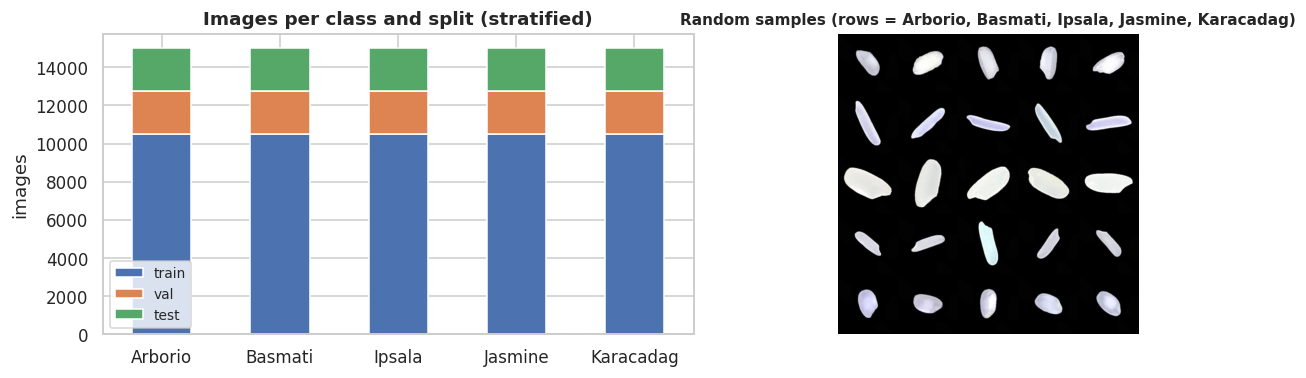

In [7]:
# ---- dataset overview ----
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={'width_ratios': [1, 1.4]})
cnt = pd.DataFrame({'train': np.bincount(y_all[train_idx], minlength=NUM_CLASSES),
                    'val': np.bincount(y_all[val_idx], minlength=NUM_CLASSES),
                    'test': np.bincount(y_all[test_idx], minlength=NUM_CLASSES)}, index=CLASS_NAMES)
cnt.plot.bar(stacked=True, ax=axes[0], color=['#4C72B0', '#DD8452', '#55A868'], rot=0)
axes[0].set_title('Images per class and split (stratified)'); axes[0].set_ylabel('images')
axes[1].axis('off')
n_show = 5
rng = np.random.default_rng(0)
grid = np.ones((NUM_CLASSES * 112, n_show * 112, 3), dtype=np.uint8) * 255
for r, c in enumerate(range(NUM_CLASSES)):
    pick = rng.choice(np.where(y_all == c)[0], n_show, replace=False)
    for k, i in enumerate(pick):
        grid[r*112:(r+1)*112, k*112:(k+1)*112] = np.asarray(Image.fromarray(X_np[i]).resize((112, 112)))
axes[1].imshow(grid); axes[1].set_title('Random samples (rows = ' + ', '.join(CLASS_NAMES) + ')', fontsize=10)
plt.tight_layout(); savefig('00_dataset_overview')

### GPU data pipeline
`GPULoader` gathers `uint8` batches from the RAM tensor on a background thread (torch ops release the GIL), copies them to the GPU and, for training only, applies a **lossless** random dihedral augmentation (random transpose + horizontal flip + vertical flip → the 8 symmetries of a square) — only pixel permutations, no resampling.

In [8]:
_MEAN_STD = {}
for _d in [torch.device(f'cuda:{i}') for i in range(N_GPU)]:
    _MEAN_STD[str(_d)] = (torch.tensor([0.485, 0.456, 0.406], device=_d).view(1, 3, 1, 1),
                          torch.tensor([0.229, 0.224, 0.225], device=_d).view(1, 3, 1, 1))

def gpu_augment(x, gen):
    # random dihedral transform per sample; pure permutation of pixels (no interpolation)
    B, d = x.size(0), x.device
    flag = lambda: (torch.rand(B, device=d, generator=gen) < 0.5).view(B, 1, 1, 1)
    x = torch.where(flag(), x.transpose(2, 3), x)
    x = torch.where(flag(), x.flip(3), x)
    x = torch.where(flag(), x.flip(2), x)
    return x

def prep_batch(xb_uint8, device, augment=False, gen=None, channels_last=True):
    x = xb_uint8.to(device, non_blocking=True).permute(0, 3, 1, 2).float().div_(255.0)
    if augment: x = gpu_augment(x, gen)
    m, s = _MEAN_STD[str(device)]
    x = (x - m) / s
    return x.contiguous(memory_format=torch.channels_last) if channels_last else x.contiguous()

class GPULoader:
    def __init__(self, idx, batch_size, device, shuffle=False, augment=False, drop_last=False, seed=0, channels_last=True):
        self.idx = np.sort(np.asarray(idx)); self.bs = batch_size; self.device = device
        self.shuffle, self.augment, self.drop_last, self.cl = shuffle, augment, drop_last, channels_last
        self.rng = np.random.default_rng(seed)
        self.gen = torch.Generator(device=device); self.gen.manual_seed(int(seed))
    def __len__(self):
        n = len(self.idx)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)
    def __iter__(self):
        order = self.rng.permutation(self.idx) if self.shuffle else self.idx
        q = queue.Queue(maxsize=4); n_batches = len(self)
        def producer():
            try:
                for i in range(n_batches):
                    b = torch.from_numpy(np.ascontiguousarray(order[i * self.bs:(i + 1) * self.bs]))
                    q.put((X_t.index_select(0, b), Y_t.index_select(0, b)))
                q.put(None)
            except BaseException as e:
                q.put(e)
        threading.Thread(target=producer, daemon=True).start()
        while True:
            item = q.get()
            if item is None: break
            if isinstance(item, BaseException): raise item
            xb, yb = item
            yield prep_batch(xb, self.device, self.augment, self.gen, self.cl), yb.to(self.device, non_blocking=True)

@torch.no_grad()
def predict_logits(net, idx, device, cl=True, bs=None):
    net.eval()
    outs, ys = [], []
    for xb, yb in GPULoader(idx, bs or CFG['eval_batch_size'], device, channels_last=cl):
        with torch.autocast('cuda', dtype=torch.float16):
            o = net(xb)
        outs.append(o.float().cpu()); ys.append(yb.cpu())
    return torch.cat(outs), torch.cat(ys)

def eval_split(net, idx, device, cl=True):
    logits, yy = predict_logits(net, idx, device, cl)
    return F.cross_entropy(logits, yy).item(), (logits.argmax(1) == yy).float().mean().item(), logits.numpy(), yy.numpy()

@torch.no_grad()
def recalibrate_bn(model, idx, device, cl=True):
    # "precise BN": re-estimate BatchNorm running statistics on clean (non-augmented) training images.
    bns = [m for m in model.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)]
    if not bns or len(idx) < 8: return
    moms = [m.momentum for m in bns]
    for m in bns: m.reset_running_stats(); m.momentum = None        # None -> exact cumulative average
    model.train()
    for xb, _ in GPULoader(idx, 128, device, shuffle=True, augment=False, seed=0, channels_last=cl):
        if len(xb) < 2: continue
        with torch.autocast('cuda', dtype=torch.float16): model(xb)
    for m, mo in zip(bns, moms): m.momentum = mo

# ---- sanity check of the pipeline + augmentation (must be a pure permutation of the pixels) ----
xb, yb = next(iter(GPULoader(train_idx, 8, dev, shuffle=True, augment=True)))
print('batch:', tuple(xb.shape), xb.dtype, '| mean %.2f std %.2f' % (xb.mean().item(), xb.std().item()), '| labels', yb.tolist())
_g = torch.Generator(device=dev); _g.manual_seed(0)
_x = torch.randn(16, 3, 32, 32, device=dev)
_a = gpu_augment(_x, _g)
assert torch.allclose(_x.flatten(1).sort(1)[0], _a.flatten(1).sort(1)[0]), 'augmentation is not a pure permutation'
print('augmentation check passed: sorted pixel values are identical before/after (lossless).')

batch: (8, 3, 224, 224) torch.float32 | mean -1.54 std 1.21 | labels [1, 1, 0, 3, 4, 2, 4, 0]
augmentation check passed: sorted pixel values are identical before/after (lossless).


<a class="anchor" id="sec2"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">2 · Backbones, parameter counts and inference efficiency</p>

Each backbone is created with `timm`, its ImageNet classifier is replaced by a fresh 5-way head, and pretrained weights are fetched through the timm / Hugging Face hub. Efficiency (params, GMACs, throughput, latency) is measured on a single T4 with random weights — speed does not depend on the weight values.

In [9]:
def build_model(key, pretrained=True, num_classes=NUM_CLASSES):
    name = MODELS[key]['timm']
    try:
        return timm.create_model(name, pretrained=pretrained, num_classes=num_classes)
    except Exception as e:
        base = name.split('.')[0]
        print(f'  ! could not create "{name}" ({type(e).__name__}); falling back to default weights of "{base}"')
        return timm.create_model(base, pretrained=pretrained, num_classes=num_classes)

rows = []
for key in MODELS:
    try:
        m = build_model(key, pretrained=True)
    except Exception as e:
        raise RuntimeError(f'Downloading pretrained weights for {key} failed. Is Internet turned ON in the notebook settings?\n{e}')
    cfg = m.pretrained_cfg
    rows.append(dict(model=key, timm_name=MODELS[key]['timm'], family=MODELS[key]['family'],
                     params_M=sum(p.numel() for p in m.parameters()) / 1e6,
                     input=cfg.get('input_size'), mean_ok=tuple(cfg.get('mean', ())) == (0.485, 0.456, 0.406)))
    del m
display(pd.DataFrame(rows).set_index('model').round(2))
if not all(r['mean_ok'] for r in rows): print('WARNING: a backbone does not use the standard ImageNet mean/std - check MEAN/STD in the data pipeline.')

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/32.3M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/22.1M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

,timm_name,family,params_M,input,mean_ok
model,,,,,
ResNet-50,resnet50.tv_in1k,CNN,23.52,"(3, 224, 224)",True
DenseNet-121,densenet121.tv_in1k,CNN,6.96,"(3, 224, 224)",True
EfficientNet-B0,efficientnet_b0.ra_in1k,CNN,4.01,"(3, 224, 224)",True
MobileNetV3-L,mobilenetv3_large_100.ra_in1k,CNN,4.21,"(3, 224, 224)",True
ConvNeXt-T,convnext_tiny.fb_in1k,CNN,27.82,"(3, 224, 224)",True
Swin-T,swin_tiny_patch4_window7_224.ms_in1k,Transformer,27.52,"(3, 224, 224)",True
DeiT-S,deit_small_patch16_224.fb_in1k,Transformer,21.67,"(3, 224, 224)",True


In [10]:
@torch.no_grad()
def measure_efficiency(key, img=S, bs=128):
    m = build_model(key, pretrained=False).to(dev).eval().to(memory_format=torch.channels_last)
    res = dict(params_m=sum(p.numel() for p in m.parameters()) / 1e6,
               size_mb=sum(p.numel() * 4 for p in m.parameters()) / 1e6)
    try:
        from torch.utils.flop_counter import FlopCounterMode
        with FlopCounterMode(display=False) as fc:
            m(torch.randn(1, 3, img, img, device=dev))
        res['gmacs'] = fc.get_total_flops() / 2 / 1e9
    except Exception:
        res['gmacs'] = float('nan')
    def bench(batch, iters, warm, amp):
        x = torch.randn(batch, 3, img, img, device=dev).contiguous(memory_format=torch.channels_last)
        for _ in range(warm):
            with torch.autocast('cuda', dtype=torch.float16, enabled=amp): m(x)
        torch.cuda.synchronize(); t = []
        for _ in range(iters):
            t0 = time.perf_counter()
            with torch.autocast('cuda', dtype=torch.float16, enabled=amp): m(x)
            torch.cuda.synchronize(); t.append(time.perf_counter() - t0)
        return np.array(t)
    res['throughput_fp16'] = bs / np.median(bench(bs, 20, 5, True))
    res['throughput_fp32'] = bs / np.median(bench(bs, 10, 3, False))
    res['latency_bs1_ms'] = 1000 * np.median(bench(1, 60, 15, False))
    del m; gc.collect(); torch.cuda.empty_cache()
    return res

eff_path = RES_DIR / 'efficiency.json'
EFF_RAW = json.load(open(eff_path)) if eff_path.exists() else {}
for key in MODELS:
    if key not in EFF_RAW:
        EFF_RAW[key] = measure_efficiency(key); print('measured', key)
json.dump(EFF_RAW, open(eff_path, 'w'), indent=1)
EFF = pd.DataFrame(EFF_RAW).T.loc[list(MODELS)]
display(EFF.rename(columns={'params_m': 'Params (M)', 'size_mb': 'Size (MB, fp32)', 'gmacs': 'GMACs @224',
                            'throughput_fp16': 'Throughput fp16 (img/s)', 'throughput_fp32': 'Throughput fp32 (img/s)',
                            'latency_bs1_ms': 'Latency bs=1 (ms)'}).round(2))

measured ResNet-50
measured DenseNet-121
measured EfficientNet-B0
measured MobileNetV3-L
measured ConvNeXt-T
measured Swin-T
measured DeiT-S


,Params (M),"Size (MB, fp32)",GMACs @224,Throughput fp16 (img/s),Throughput fp32 (img/s),Latency bs=1 (ms)
ResNet-50,23.52,94.07,4.09,1041.65,360.39,6.67
DenseNet-121,6.96,27.84,2.83,723.39,329.50,18.79
EfficientNet-B0,4.01,16.06,0.38,1855.00,977.38,8.90
MobileNetV3-L,4.21,16.83,0.22,3087.60,1631.85,7.06
ConvNeXt-T,27.82,111.30,4.45,631.74,225.86,5.89
Swin-T,27.52,110.09,4.49,433.46,212.57,11.00
DeiT-S,21.67,86.67,4.60,1040.62,300.38,5.35


<a class="anchor" id="sec3"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">3 · Metrics toolbox</p>

For every run the **full metric suite** is computed from the softmax probabilities on validation and test data:

*accuracy · balanced accuracy · macro precision / recall / F1 · weighted F1 · Cohen's κ · Matthews corr. coef. · macro one-vs-rest ROC-AUC · log-loss (NLL) · Brier score · Expected Calibration Error (ECE) · mean confidence on correct vs. wrong predictions · per-class P/R/F1 · confusion matrix.*

In [11]:
def softmax_np(logits):
    z = np.nan_to_num(logits.astype(np.float64), nan=0.0, posinf=50.0, neginf=-50.0); z -= z.max(1, keepdims=True)
    e = np.exp(z); return e / e.sum(1, keepdims=True)

def ece_score(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)

def full_metrics(y, probs):
    pred = probs.argmax(1); labs = list(range(NUM_CLASSES))
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=labs, zero_division=0)
    onehot = np.eye(NUM_CLASSES)[y]
    ok = pred == y
    try: auc = roc_auc_score(y, probs, multi_class='ovr', average='macro', labels=labs)
    except Exception: auc = float('nan')
    return dict(
        acc=float(accuracy_score(y, pred)), balanced_acc=float(balanced_accuracy_score(y, pred)),
        macro_precision=float(p.mean()), macro_recall=float(r.mean()), macro_f1=float(f.mean()),
        weighted_f1=float(f1_score(y, pred, average='weighted')),
        kappa=float(cohen_kappa_score(y, pred)), mcc=float(matthews_corrcoef(y, pred)), roc_auc=float(auc),
        log_loss=float(log_loss(y, np.clip(probs, 1e-7, 1), labels=labs)),
        brier=float(np.mean(np.sum((probs - onehot) ** 2, 1))), ece=ece_score(probs, y),
        n_errors=int((~ok).sum()), n=int(len(y)),
        conf_correct=float(probs.max(1)[ok].mean()) if ok.any() else float('nan'),
        conf_wrong=float(probs.max(1)[~ok].mean()) if (~ok).any() else float('nan'),
        per_class_precision=p.tolist(), per_class_recall=r.tolist(), per_class_f1=f.tolist(),
        confusion=confusion_matrix(y, pred, labels=labs).tolist())

# unit test on synthetic data
_y = np.random.default_rng(0).integers(0, 5, 1000); _p = softmax_np(np.eye(5)[_y] * 6 + np.random.default_rng(1).normal(size=(1000, 5)))
_m = full_metrics(_y, _p); print({k: round(v, 4) for k, v in _m.items() if isinstance(v, float)})

{'acc': 1.0, 'balanced_acc': 1.0, 'macro_precision': 1.0, 'macro_recall': 1.0, 'macro_f1': 1.0, 'weighted_f1': 1.0, 'kappa': 1.0, 'mcc': 1.0, 'roc_auc': 1.0, 'log_loss': 0.0272, 'brier': 0.0028, 'ece': 0.0261, 'conf_correct': 0.9739, 'conf_wrong': nan}


<a class="anchor" id="sec4"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">4 · Training engine (two-stage transfer learning)</p>

| Stage | What is trained | Optimiser / LR | Notes |
|---|---|---|---|
| **1 · Linear probe** | new 5-way head only (backbone frozen, BatchNorm statistics frozen) | AdamW, constant 1e-3 | measures the quality of the *frozen* pretrained features |
| **2 · Fine-tuning** | whole network | AdamW, backbone 1e-4 / head 1e-3, 10 % linear warm-up → cosine decay | gradient clipping 1.0, mixed precision (fp16 AMP), precise-BN after every epoch |

Same recipe, same epochs, same split for every backbone. Per epoch the engine records train loss/acc, **validation loss/acc**, clean-train loss/acc, learning rate and wall-clock time. The checkpoint with the lowest validation loss *during fine-tuning* is restored at the end and evaluated on val and test.

In [12]:
def _json_default(o):
    if isinstance(o, np.generic): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(type(o))

def make_scaler():
    try: return torch.amp.GradScaler('cuda')
    except Exception: return torch.cuda.amp.GradScaler()

def cosine_warmup(total, warm_frac=0.1, min_ratio=0.01):
    warm = max(1, int(total * warm_frac))
    def f(s):
        if s < warm: return (s + 1) / warm
        p = (s - warm) / max(1, total - warm)
        return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * p))
    return f

def cleanup(device):
    gc.collect()
    with torch.cuda.device(device): torch.cuda.empty_cache()

PROBE = {}                                   # filled by the pre-flight stage: batch size + memory layout per backbone
get_bs = lambda key: PROBE.get(key, {}).get('bs', CFG['batch_size'])
get_cl = lambda key: PROBE.get(key, {}).get('cl', True)

def run_experiment(key, seed, device, frac=1.0, pretrained=True, lp_epochs=None, ft_epochs=None,
                   kind='main', save_ckpt=False, small_val=False, save=True):
    slug = slugify(key)
    run_id = f'{slug}_s{seed}' if kind == 'main' else f'{slug}_{"pt" if pretrained else "scratch"}_f{frac}_s{seed}'
    out_json = RES_DIR / f'{run_id}.json'
    if save and out_json.exists():
        print(f'[skip] {run_id} (cached)'); return json.load(open(out_json))
    lp_epochs = CFG['lp_epochs'] if lp_epochs is None else lp_epochs
    ft_epochs = CFG['ft_epochs'] if ft_epochs is None else ft_epochs
    if not pretrained: lp_epochs = 0
    bs, cl = get_bs(key), get_cl(key)
    tag = f'gpu{device.index} | {key} | s{seed} | {"PT" if pretrained else "scratch"} | {frac:g}'

    with INIT_LOCK:                                   # deterministic head initialisation even with 2 workers
        set_seed(seed); base = build_model(key, pretrained)
    base = base.to(device)
    if cl: base = base.to(memory_format=torch.channels_last)
    head = list(base.get_classifier().parameters()); head_ids = {id(p) for p in head}
    back = [p for p in base.parameters() if id(p) not in head_ids]

    tr_idx = train_idx if frac >= 1 else strat_subset(train_idx, int(round(frac * len(train_idx))), seed)
    va_idx = val_sub_idx if small_val else val_idx
    clean_idx = strat_subset(tr_idx, CFG['clean_train_n'], 0)
    train_loader = GPULoader(tr_idx, bs, device, shuffle=True, augment=True, drop_last=True, seed=seed, channels_last=cl)
    assert len(train_loader) > 0, 'training set smaller than one batch'

    def make_optimizer(phase):
        wd = CFG['weight_decay']
        if phase == 'linear_probe': return torch.optim.AdamW(head, lr=CFG['lp_lr'], weight_decay=wd)
        if pretrained: return torch.optim.AdamW([{'params': back, 'lr': CFG['ft_lr_backbone']},
                                                 {'params': head, 'lr': CFG['ft_lr_head']}], weight_decay=wd)
        return torch.optim.AdamW(back + head, lr=CFG['scratch_lr'], weight_decay=wd)

    phases = ([('linear_probe', lp_epochs)] if lp_epochs > 0 else []) + [('finetune', ft_epochs)]
    total_epochs = lp_epochs + ft_epochs
    hist = {k: [] for k in ['epoch', 'phase', 'train_loss', 'train_acc', 'trainclean_loss', 'trainclean_acc',
                            'val_loss', 'val_acc', 'lr', 'epoch_time', 'cum_time']}
    best = dict(val_loss=float('inf'), epoch=None, state=None)
    lp_val = lp_test = None
    ep_g, cum = 0, 0.0
    torch.cuda.reset_peak_memory_stats(device)
    snapshot = lambda: {k: v.detach().cpu().clone() for k, v in base.state_dict().items()}

    for phase, n_ep in phases:
        for p in back: p.requires_grad = (phase != 'linear_probe')
        for p in head: p.requires_grad = True
        trainable = [p for p in base.parameters() if p.requires_grad]
        opt = make_optimizer(phase)
        sched = torch.optim.lr_scheduler.LambdaLR(opt, cosine_warmup(n_ep * len(train_loader))) if phase == 'finetune' else None
        scaler = make_scaler()
        for _ in range(n_ep):
            ep_g += 1
            base.train()
            if phase == 'linear_probe':               # frozen backbone: keep BN statistics fixed
                base.eval(); base.get_classifier().train()
            torch.cuda.synchronize(device); t0 = time.time()
            loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device); seen = 0
            for xb, yb in train_loader:
                opt.zero_grad(set_to_none=True)
                with torch.autocast('cuda', dtype=torch.float16):
                    out = base(xb)
                loss = F.cross_entropy(out.float(), yb)
                scaler.scale(loss).backward()
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(trainable, CFG['grad_clip'])
                scaler.step(opt); scaler.update()
                if sched is not None: sched.step()
                loss_sum += loss.detach() * len(yb); correct += (out.argmax(1) == yb).sum(); seen += len(yb)
            torch.cuda.synchronize(device); et = time.time() - t0; cum += et
            tl, ta = loss_sum.item() / seen, correct.item() / seen
            if phase == 'finetune' and CFG['precise_bn']:
                recalibrate_bn(base, clean_idx, device, cl)
            vl, vacc, _, _ = eval_split(base, va_idx, device, cl)
            cll, cacc, _, _ = eval_split(base, clean_idx, device, cl)
            for k, v in zip(hist, [ep_g, phase, tl, ta, cll, cacc, vl, vacc, opt.param_groups[0]['lr'], et, cum]): hist[k].append(v)
            if phase == 'finetune' and vl < best['val_loss']:
                best = dict(val_loss=vl, epoch=ep_g, state=snapshot())
            print(f'[{tag}] ep {ep_g:02d}/{total_epochs} {"LP" if phase == "linear_probe" else "FT"} '
                  f'| train {tl:.4f}/{ta:.4f} | val {vl:.4f}/{vacc:.4f} | clean-train acc {cacc:.4f} | {et:.0f}s')
        if phase == 'linear_probe':                   # stage-1 result, evaluated once, never used for selection
            _, _, lg, yy = eval_split(base, va_idx, device, cl); lp_val = full_metrics(yy, softmax_np(lg))
            _, _, lg, yy = eval_split(base, test_idx, device, cl); lp_test = full_metrics(yy, softmax_np(lg))

    if best['state'] is None:                         # e.g. NaN validation loss: fall back to the last weights
        best = dict(val_loss=float('nan'), epoch=ep_g, state=snapshot())
    base.load_state_dict(best['state'])
    _, _, lg, yy = eval_split(base, va_idx, device, cl);   val_m = full_metrics(yy, softmax_np(lg))
    _, _, lg, yy = eval_split(base, test_idx, device, cl); probs = softmax_np(lg); test_m = full_metrics(yy, probs)
    peak = torch.cuda.max_memory_allocated(device) / 1e9
    res = dict(run_id=run_id, kind=kind, model=key, seed=seed, frac=frac, pretrained=pretrained, n_train=int(len(tr_idx)),
               batch_size=bs, channels_last=cl, lp_epochs=lp_epochs, ft_epochs=ft_epochs, best_epoch=best['epoch'], history=hist,
               train_time_s=cum, peak_mem_gb=peak, val_metrics=val_m, test_metrics=test_m, lp_val_metrics=lp_val, lp_test_metrics=lp_test)
    if save:
        json.dump(res, open(out_json, 'w'), default=_json_default)
        if kind == 'main':
            np.savez_compressed(RES_DIR / f'{run_id}_test.npz', probs=probs.astype(np.float32), y=yy, idx=np.sort(test_idx))
        if save_ckpt: torch.save(best['state'], CKPT_DIR / f'{slug}.pt')
    print(f'[{tag}] => test acc {test_m["acc"]:.4f} | macro-F1 {test_m["macro_f1"]:.4f} | errors {test_m["n_errors"]}/{test_m["n"]} | train time {cum/60:.1f} min')
    return res

# ---------------------------------------------------------------- job runner: one worker thread per GPU
def run_jobs(jobs, budget_h, est_fn=None, name='jobs'):
    t_start = time.time(); deadline = budget_h * 3600
    q = queue.Queue()
    for j in jobs: q.put(j)
    done, failed, skipped, started = [], [], [], [0]
    lock = threading.Lock()
    def worker(device):
        while True:
            try: job = q.get_nowait()
            except queue.Empty: return
            el = time.time() - t_start; need = est_fn(job) if est_fn else 0
            with lock:
                if started[0] > 0 and el + need > deadline:      # never skip the very first job
                    skipped.append(job); continue
                started[0] += 1
            try:
                with torch.cuda.device(device):
                    run_experiment(device=device, **job)
                with lock: done.append(job)
            except Exception as e:
                traceback.print_exc()
                with lock: failed.append((job, repr(e)))
            finally:
                cleanup(device)
    print(f'[{name}] {len(jobs)} jobs on {len(GPUS)} GPU worker(s) | budget {budget_h:.1f} h')
    threads = [threading.Thread(target=worker, args=(d,)) for d in GPUS]
    for t in threads: t.start()
    for t in threads: t.join()
    print(f'\n[{name}] finished in {(time.time()-t_start)/60:.1f} min | done {len(done)} | failed {len(failed)} | skipped (no time left) {len(skipped)}')
    for j, e in failed: print('   FAILED:', {k: j[k] for k in ('key', 'seed', 'frac', 'pretrained') if k in j}, e)
    for j in skipped: print('   skipped:', {k: j[k] for k in ('key', 'seed', 'frac', 'pretrained') if k in j})
    return done, failed, skipped

<a class="anchor" id="sec4b"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">4b · Pre-flight checks</p>

Four checks run before the long training jobs start:

1. **GPU speed probe** — for every backbone: real training-step throughput on synthetic data, channels-last vs. standard memory layout (the faster one is used), and an out-of-memory check (falls back to batch 64 if needed).
2. **Data-loader speed** — makes sure the input pipeline is not the bottleneck.
3. **Budget planning** — from these measurements the notebook estimates the duration of every job and decides how many seeds fit into `main_budget_h`.
4. **Learning gate** — a 3-epoch fine-tuning run on 6,000 images. If validation accuracy collapses (the failure mode of a train/eval pipeline mismatch), the run aborts immediately with a diagnosis, before any long training job starts.

In [13]:
def probe_model(key, device, bs_list=(128, 64), iters=6, warm=4):
    for bs in bs_list:
        res = {}
        for cl in (True, False):
            m = opt = scaler = x = y = None
            try:
                with torch.cuda.device(device):
                    torch.cuda.reset_peak_memory_stats(device)
                    m = build_model(key, pretrained=False).to(device)
                    if cl: m = m.to(memory_format=torch.channels_last)
                    m.train(); opt = torch.optim.AdamW(m.parameters(), lr=1e-4); scaler = make_scaler()
                    x = torch.randn(bs, 3, S, S, device=device)
                    if cl: x = x.contiguous(memory_format=torch.channels_last)
                    y = torch.randint(0, NUM_CLASSES, (bs,), device=device)
                    def step():
                        opt.zero_grad(set_to_none=True)
                        with torch.autocast('cuda', dtype=torch.float16): out = m(x)
                        loss = F.cross_entropy(out.float(), y); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
                    for _ in range(warm): step()
                    torch.cuda.synchronize(device); t0 = time.perf_counter()
                    for _ in range(iters): step()
                    torch.cuda.synchronize(device)
                    res[cl] = dict(ips=bs * iters / (time.perf_counter() - t0), mem=torch.cuda.max_memory_allocated(device) / 1e9)
            except torch.cuda.OutOfMemoryError:
                res[cl] = None
            finally:
                del m, opt, scaler, x, y; cleanup(device)
        ok = {c: r for c, r in res.items() if r}
        if ok:
            best_cl = max(ok, key=lambda c: ok[c]['ips'])
            return dict(bs=bs, cl=best_cl, ips=ok[best_cl]['ips'], mem=ok[best_cl]['mem'],
                        ips_channels_last=res[True]['ips'] if res[True] else float('nan'),
                        ips_standard=res[False]['ips'] if res[False] else float('nan'))
    raise RuntimeError(f'{key} does not fit into GPU memory even with batch size {bs_list[-1]}')

for key in MODELS:
    PROBE[key] = probe_model(key, dev)
    print(f'{key:<16s} bs {PROBE[key]["bs"]:>3d} | {"channels_last" if PROBE[key]["cl"] else "standard    "} | {PROBE[key]["ips"]:6.0f} img/s | peak {PROBE[key]["mem"]:.1f} GB')

# data-loader throughput (gather from RAM + host->GPU copy + GPU augmentation)
_ld = GPULoader(train_idx, 128, dev, shuffle=True, augment=True, drop_last=True, seed=0)
_n = max(1, min(20, len(_ld) - 2)); _it = iter(_ld); next(_it); torch.cuda.synchronize(dev); _t0 = time.perf_counter()
for _ in range(_n): next(_it)
torch.cuda.synchronize(dev); LOADER_IPS = 128 * _n / (time.perf_counter() - _t0)
print(f'\ndata loader: {LOADER_IPS:.0f} img/s per GPU worker (should be well above the training speeds above)')
slowest = min(p['ips'] for p in PROBE.values())
if LOADER_IPS < 1.5 * max(p['ips'] for p in PROBE.values()):
    print('⚠️  the data loader is slow relative to the GPUs; training will be input-bound.')

ResNet-50        bs 128 | channels_last |    346 img/s | peak 10.2 GB
DenseNet-121     bs 128 | channels_last |    254 img/s | peak 9.0 GB
EfficientNet-B0  bs 128 | channels_last |    471 img/s | peak 7.1 GB
MobileNetV3-L    bs 128 | channels_last |    855 img/s | peak 6.2 GB
ConvNeXt-T       bs 128 | channels_last |    225 img/s | peak 10.7 GB
Swin-T           bs 128 | channels_last |    169 img/s | peak 9.5 GB
DeiT-S           bs 128 | standard     |    334 img/s | peak 4.8 GB

data loader: 10507 img/s per GPU worker (should be well above the training speeds above)


In [14]:
def est_seconds(key, frac, lp, ft):
    ips = PROBE[key]['ips']; n = frac * len(train_idx); ep = n / ips
    ev = (len(val_idx) + CFG['clean_train_n']) / (3 * ips)      # forward-only passes are ~3x cheaper than training
    fin = (len(val_idx) + len(test_idx)) / (3 * ips)
    return 1.2 * (lp * 0.45 * ep + ft * ep + (lp + ft) * ev + fin)

n_w = len(GPUS)
seed_cost = sum(est_seconds(k, 1.0, CFG['lp_epochs'], CFG['ft_epochs']) for k in MODELS)
wall_per_seed = seed_cost / n_w * 1.1
budget_s = CFG['main_budget_h'] * 3600
MAIN_FRAC = 1.0
n_fit = int(budget_s // wall_per_seed)
if n_fit >= 1:
    RUN_SEEDS = CFG['seeds'][:min(len(CFG['seeds']), n_fit)]
else:
    RUN_SEEDS = CFG['seeds'][:1]
    MAIN_FRAC = float(np.clip(0.9 * budget_s / wall_per_seed, 0.15, 1.0))
plan = pd.DataFrame({k: dict(batch=PROBE[k]['bs'], layout='channels_last' if PROBE[k]['cl'] else 'standard',
                             train_img_per_s=round(PROBE[k]['ips']), est_min_per_run=round(est_seconds(k, MAIN_FRAC, CFG['lp_epochs'], CFG['ft_epochs']) / 60, 1))
                     for k in MODELS}).T
display(plan)
print(f'estimated wall-clock per seed on {n_w} GPU(s): {wall_per_seed/60:.0f} min  |  budget: {CFG["main_budget_h"]:.1f} h')
print(f'==> seeds that will be run: {RUN_SEEDS}' + (f'   (⚠️ hardware slower than expected: training on {MAIN_FRAC*100:.0f} % of the training set)' if MAIN_FRAC < 1 else ''))

,batch,layout,train_img_per_s,est_min_per_run
ResNet-50,128,channels_last,346,16.9
DenseNet-121,128,channels_last,254,23.1
EfficientNet-B0,128,channels_last,471,12.5
MobileNetV3-L,128,channels_last,855,6.9
ConvNeXt-T,128,channels_last,225,26.1
Swin-T,128,channels_last,169,34.7
DeiT-S,128,standard,334,17.6


estimated wall-clock per seed on 2 GPU(s): 76 min  |  budget: 5.0 h
==> seeds that will be run: [42, 43, 44]


In [15]:
# ---- learning gate: ResNet-50, 6,000 training images, 1 linear-probe + 2 fine-tuning epochs ----
t0 = time.time()
with torch.cuda.device(dev):
    gate = run_experiment('ResNet-50', 0, dev, frac=min(1.0, 6000 / len(train_idx)), pretrained=True,
                          lp_epochs=1, ft_epochs=2, kind='gate', small_val=True, save=False)
cleanup(dev)
g_val, g_clean = gate['val_metrics']['acc'], gate['history']['trainclean_acc'][-1]
print(f'\nLEARNING GATE: linear-probe val acc {gate["lp_val_metrics"]["acc"]:.4f} -> after fine-tuning val acc {g_val:.4f} | '
      f'clean-train acc (eval mode) {g_clean:.4f} | {time.time()-t0:.0f}s')
if not QUICK_TEST and g_val < 0.93:
    raise RuntimeError(
        f'Learning gate FAILED (val acc {g_val:.3f}). Fine-tuning does not generalise to validation images although the pipeline is '
        f'the same for both. Clean-train acc = {g_clean:.3f}: if it is high while val acc is low there is a train/eval mismatch; '
        f'if both are low the model is not learning. Stopping now instead of wasting hours of GPU time.')
print('✅ gate passed — the full benchmark can start.')

[gpu0 | ResNet-50 | s0 | PT | 0.114288] ep 01/3 LP | train 0.5799/0.8682 | val 0.2337/0.9440 | clean-train acc 0.9413 | 7s
[gpu0 | ResNet-50 | s0 | PT | 0.114288] ep 02/3 FT | train 0.1791/0.9346 | val 0.0086/0.9980 | clean-train acc 0.9980 | 18s
[gpu0 | ResNet-50 | s0 | PT | 0.114288] ep 03/3 FT | train 0.0091/0.9975 | val 0.0081/0.9988 | clean-train acc 0.9987 | 18s
[gpu0 | ResNet-50 | s0 | PT | 0.114288] => test acc 0.9987 | macro-F1 0.9987 | errors 15/11251 | train time 0.7 min

LEARNING GATE: linear-probe val acc 0.9440 -> after fine-tuning val acc 0.9988 | clean-train acc (eval mode) 0.9987 | 112s
✅ gate passed — the full benchmark can start.


<a class="anchor" id="sec5"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">5 · Main benchmark — all backbones × seeds</p>

Two backbones train concurrently, one per T4. Each finished run is stored as a JSON file, which makes the benchmark resumable; checkpoints of the **first seed** are kept for the Grad-CAM and robustness studies. A time-budget guard skips jobs that would not fit, and a failed job is logged without stopping the others.

In [16]:
main_jobs = []
for s in RUN_SEEDS:
    for k in sorted(MODELS, key=lambda k: -est_seconds(k, MAIN_FRAC, CFG['lp_epochs'], CFG['ft_epochs'])):   # long jobs first
        main_jobs.append(dict(key=k, seed=s, frac=MAIN_FRAC, pretrained=True, lp_epochs=CFG['lp_epochs'], ft_epochs=CFG['ft_epochs'],
                              kind='main', save_ckpt=(s == RUN_SEEDS[0])))
est_job = lambda j: est_seconds(j['key'], j['frac'], j['lp_epochs'], j['ft_epochs'])
done, failed, skipped = run_jobs(main_jobs, CFG['main_budget_h'], est_job, name='main benchmark')
assert any(RES_DIR.glob('*_s*.json')), 'no main run finished - see the errors above'

[main benchmark] 21 jobs on 2 GPU worker(s) | budget 5.0 h
[gpu1 | ConvNeXt-T | s42 | PT | 1] ep 01/6 LP | train 0.2171/0.9700 | val 0.0690/0.9900 | clean-train acc 0.9900 | 84s
[gpu0 | Swin-T | s42 | PT | 1] ep 01/6 LP | train 0.1265/0.9778 | val 0.0382/0.9917 | clean-train acc 0.9943 | 120s
[gpu1 | ConvNeXt-T | s42 | PT | 1] ep 02/6 LP | train 0.0466/0.9934 | val 0.0389/0.9938 | clean-train acc 0.9953 | 85s
[gpu0 | Swin-T | s42 | PT | 1] ep 02/6 LP | train 0.0284/0.9938 | val 0.0240/0.9941 | clean-train acc 0.9970 | 120s
[gpu1 | ConvNeXt-T | s42 | PT | 1] ep 03/6 FT | train 0.0110/0.9974 | val 0.0118/0.9977 | clean-train acc 0.9980 | 256s
[gpu0 | Swin-T | s42 | PT | 1] ep 03/6 FT | train 0.0276/0.9923 | val 0.0098/0.9980 | clean-train acc 0.9990 | 301s
[gpu1 | ConvNeXt-T | s42 | PT | 1] ep 04/6 FT | train 0.0057/0.9986 | val 0.0041/0.9993 | clean-train acc 0.9990 | 232s
[gpu0 | Swin-T | s42 | PT | 1] ep 04/6 FT | train 0.0108/0.9974 | val 0.0056/0.9987 | clean-train acc 1.0000 | 297s

<a class="anchor" id="sec6"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">6 · Data-efficiency study: pretrained vs. training from scratch</p>

Here the same architectures are trained on only **1 %, 5 %, 10 %** of the training data (≈525 / 2,625 / 5,250 images), once starting from ImageNet weights and once from random initialisation (same recipe, more epochs because there is less data per epoch). Evaluation always uses the full test set. This is the cleanest way to show *what transfer learning actually contributes* on this dataset.

In [17]:
DE_KEYS = [k for k in CFG['de_models'] if k in MODELS]
de_jobs = []
for frac in CFG['de_fracs']:
    ep = CFG['de_epochs'][frac]
    for k in DE_KEYS:
        for pt in (True, False):
            lp = int(round(0.2 * ep)) if pt else 0
            de_jobs.append(dict(key=k, seed=CFG['seeds'][0], frac=frac, pretrained=pt, lp_epochs=lp, ft_epochs=ep - lp, kind='data_eff', small_val=True))
de_done, de_failed, de_skipped = run_jobs(de_jobs, CFG['de_budget_h'], est_job, name='data efficiency')

[data efficiency] 42 jobs on 2 GPU worker(s) | budget 2.5 h
[gpu0 | ResNet-50 | s42 | PT | 0.01] ep 01/30 LP | train 1.5017/0.4180 | val 1.2467/0.7768 | clean-train acc 0.7943 | 2s
[gpu0 | ResNet-50 | s42 | PT | 0.01] ep 02/30 LP | train 1.1170/0.8379 | val 0.9246/0.8600 | clean-train acc 0.8857 | 1s
[gpu1 | ResNet-50 | s42 | scratch | 0.01] ep 01/30 FT | train 1.5369/0.3242 | val 1.3489/0.6816 | clean-train acc 0.7010 | 5s
[gpu0 | ResNet-50 | s42 | PT | 0.01] ep 03/30 LP | train 0.8277/0.8887 | val 0.6963/0.8988 | clean-train acc 0.9219 | 1s
[gpu1 | ResNet-50 | s42 | scratch | 0.01] ep 02/30 FT | train 1.2328/0.6191 | val 1.0477/0.7296 | clean-train acc 0.7410 | 1s
[gpu0 | ResNet-50 | s42 | PT | 0.01] ep 04/30 LP | train 0.6370/0.8926 | val 0.5431/0.9040 | clean-train acc 0.9276 | 1s
[gpu0 | ResNet-50 | s42 | PT | 0.01] ep 05/30 LP | train 0.5064/0.9121 | val 0.4373/0.9132 | clean-train acc 0.9371 | 1s
[gpu1 | ResNet-50 | s42 | scratch | 0.01] ep 03/30 FT | train 0.9967/0.7422 | val 0

<a class="anchor" id="sec7"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">7 · Robustness study</p>

The best checkpoint of each backbone (first seed) is evaluated on a fixed, stratified test subset after applying **synthetic corruptions** that mimic real imaging conditions (camera noise, out-of-focus, lighting changes, different grain orientation, low-resolution cameras). Nothing is retrained.

In [18]:
CORRUPTIONS = {
    'Gaussian noise (σ)':   ('noise',      [0.02, 0.05, 0.10, 0.20]),
    'Gaussian blur (σ px)': ('blur',       [0.5, 1.0, 2.0, 3.0]),
    'Brightness (×)':       ('brightness', [0.4, 0.6, 1.4, 1.8]),
    'Contrast (×)':         ('contrast',   [0.4, 0.6, 1.4, 1.8]),
    'Rotation (°)':         ('rotation',   [15, 45, 90, 135]),
    'Low resolution (px)':  ('lowres',     [112, 64, 32, 16]),
}

def corrupt(x, kind, level, g=None):
    if kind == 'noise':      return (x + torch.randn(x.shape, device=x.device, generator=g) * level).clamp(0, 1)
    if kind == 'blur':
        k = int(2 * math.ceil(3 * level) + 1); return TF.gaussian_blur(x, [k, k], [level, level])
    if kind == 'brightness': return (x * level).clamp(0, 1)
    if kind == 'contrast':
        m = x.mean(dim=(1, 2, 3), keepdim=True); return ((x - m) * level + m).clamp(0, 1)
    if kind == 'rotation':   return TF.rotate(x, float(level), interpolation=TF.InterpolationMode.BILINEAR)
    if kind == 'lowres':
        s = int(level); small = F.interpolate(x, size=(s, s), mode='bilinear', antialias=True, align_corners=False)
        return F.interpolate(small, size=x.shape[-2:], mode='bilinear', align_corners=False)
    raise ValueError(kind)

def load_trained(key):
    path = CKPT_DIR / f'{slugify(key)}.pt'
    if not path.exists(): return None
    m = build_model(key, pretrained=False).to(dev)
    m.load_state_dict(torch.load(path, map_location=dev)); return m.eval()

@torch.no_grad()
def acc_under(model, idx, kind=None, level=None, bs=250):
    g = torch.Generator(device=dev); g.manual_seed(0)
    m_, s_ = _MEAN_STD[str(dev)]
    correct = 0
    for i in range(0, len(idx), bs):
        b = np.asarray(idx[i:i + bs])
        x = X_t.index_select(0, torch.from_numpy(b)).to(dev).permute(0, 3, 1, 2).float() / 255
        if kind: x = corrupt(x, kind, level, g)
        x = ((x - m_) / s_).contiguous()
        with torch.autocast('cuda', dtype=torch.float16): out = model(x)
        correct += int((out.argmax(1).cpu().numpy() == y_all[b]).sum())
    return correct / len(idx)

rob_path = RES_DIR / 'robustness.json'
if rob_path.exists():
    ROB = json.load(open(rob_path))
else:
    rob_idx = strat_subset(test_idx, CFG['robust_n'], 0); ROB = []
    for key in MODELS:
        m = load_trained(key)
        if m is None: print('no checkpoint for', key); continue
        ROB.append(dict(model=key, corruption='Clean', level=0, acc=float(acc_under(m, rob_idx))))
        for cname, (kind, levels) in tqdm(CORRUPTIONS.items(), desc=key):
            for lv in levels:
                ROB.append(dict(model=key, corruption=cname, level=lv, acc=float(acc_under(m, rob_idx, kind, lv))))
        del m; cleanup(dev)
    json.dump(ROB, open(rob_path, 'w'))
df_rob = pd.DataFrame(ROB); print(f'{len(df_rob)} robustness measurements')

ResNet-50:   0%|          | 0/6 [00:00<?, ?it/s]

DenseNet-121:   0%|          | 0/6 [00:00<?, ?it/s]

EfficientNet-B0:   0%|          | 0/6 [00:00<?, ?it/s]

MobileNetV3-L:   0%|          | 0/6 [00:00<?, ?it/s]

ConvNeXt-T:   0%|          | 0/6 [00:00<?, ?it/s]

Swin-T:   0%|          | 0/6 [00:00<?, ?it/s]

DeiT-S:   0%|          | 0/6 [00:00<?, ?it/s]

175 robustness measurements


<a class="anchor" id="sec-results"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Results</p>

<a class="anchor" id="sec8"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">8 · Collecting all runs &amp; summary tables</p>
All tables and figures below are computed from the saved per-run JSON files.

In [19]:
def load_results(kind):
    out = []
    for p in sorted(RES_DIR.glob('*.json')):
        if p.name in ('split.json', 'efficiency.json', 'robustness.json'): continue
        r = json.load(open(p))
        if isinstance(r, dict) and r.get('kind') == kind: out.append(r)
    return out

main_runs = load_results('main')
assert main_runs, 'No main runs found - run section 5 first.'
MODEL_ORDER = [k for k in MODELS if any(r['model'] == k for r in main_runs)]
SEED0 = CFG['seeds'][0]
print(f'{len(main_runs)} main runs | models: {MODEL_ORDER} | seeds: {sorted({r["seed"] for r in main_runs})}')

def first_epoch(va, th):
    hit = np.where(np.array(va) >= th)[0]
    return float(hit[0] + 1) if len(hit) else np.nan

TEST_KEYS = ['acc', 'balanced_acc', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1', 'kappa', 'mcc',
             'roc_auc', 'log_loss', 'brier', 'ece', 'n_errors', 'conf_correct', 'conf_wrong']
rows = []
for r in main_runs:
    tm, h, lp = r['test_metrics'], r['history'], r.get('lp_test_metrics')
    row = dict(model=r['model'], seed=r['seed'])
    row.update({f'test_{k}': tm[k] for k in TEST_KEYS})
    be = r['best_epoch'] - 1
    row.update(val_acc=r['val_metrics']['acc'], lp_test_acc=lp['acc'] if lp else np.nan, ft_gain=(tm['acc'] - lp['acc']) if lp else np.nan, lp_test_f1=lp['macro_f1'] if lp else np.nan,
               best_epoch=r['best_epoch'], train_time_min=r['train_time_s'] / 60, peak_mem_gb=r['peak_mem_gb'],
               epochs_to_99=first_epoch(h['val_acc'], 0.99), epochs_to_995=first_epoch(h['val_acc'], 0.995),
               gap_acc=h['trainclean_acc'][be] - h['val_acc'][be], gap_loss=h['val_loss'][be] - h['trainclean_loss'][be])
    rows.append(row)
df_main = pd.DataFrame(rows)
num_cols = [c for c in df_main.columns if c not in ('model', 'seed')]
SUM_MEAN = df_main.groupby('model')[num_cols].mean().loc[MODEL_ORDER]
SUM_STD  = df_main.groupby('model')[num_cols].std(ddof=0).fillna(0).loc[MODEL_ORDER]
ALL = SUM_MEAN.join(EFF.astype(float), how='left')

def ms_table(spec):
    out = {}
    for m in MODEL_ORDER:
        out[m] = {}
        for col, label, d in spec:
            mu = ALL.loc[m, col]
            out[m][label] = f'{mu:.{d}f} ± {SUM_STD.loc[m, col]:.{d}f}' if col in SUM_STD.columns else f'{mu:.{d}f}'
    return pd.DataFrame(out).T

n_seeds = df_main.groupby('model').size().min()
print(f'\n(mean ± std over {n_seeds} seed(s); std over 1 seed is 0)')

21 main runs | models: ['ResNet-50', 'DenseNet-121', 'EfficientNet-B0', 'MobileNetV3-L', 'ConvNeXt-T', 'Swin-T', 'DeiT-S'] | seeds: [42, 43, 44]

(mean ± std over 3 seed(s); std over 1 seed is 0)


In [20]:
print('TABLE 1 — Classification quality on the TEST set')
T1 = ms_table([('test_acc', 'Accuracy', 4), ('test_balanced_acc', 'Balanced acc', 4), ('test_macro_precision', 'Macro-P', 4),
               ('test_macro_recall', 'Macro-R', 4), ('test_macro_f1', 'Macro-F1', 4), ('test_weighted_f1', 'Weighted-F1', 4),
               ('test_kappa', "Cohen's κ", 4), ('test_mcc', 'MCC', 4), ('test_roc_auc', 'ROC-AUC (OvR)', 5),
               ('test_log_loss', 'Log-loss', 4), ('test_brier', 'Brier', 4), ('test_ece', 'ECE', 4), ('test_n_errors', 'Errors', 1)])
display(T1)
print('\nTABLE 2 — Transfer-learning behaviour (linear probe vs. fine-tuning, convergence, over-fitting)')
T2 = ms_table([('lp_test_acc', 'Linear-probe acc', 4), ('test_acc', 'Fine-tuned acc', 4), ('ft_gain', 'Gain from fine-tuning', 4),
               ('best_epoch', 'Best epoch', 1), ('epochs_to_99', 'Epochs → 99 % val', 1), ('epochs_to_995', 'Epochs → 99.5 % val', 1),
               ('gap_acc', 'Acc gap (clean-train − val)', 4), ('gap_loss', 'Loss gap (val − clean-train)', 4),
               ('test_conf_correct', 'Confidence | correct', 4), ('test_conf_wrong', 'Confidence | wrong', 4)])
display(T2)
print('\nTABLE 3 — Efficiency')
T3 = ms_table([('params_m', 'Params (M)', 1), ('size_mb', 'Size (MB)', 0), ('gmacs', 'GMACs', 2),
               ('throughput_fp16', 'Throughput fp16 (img/s)', 0), ('throughput_fp32', 'Throughput fp32 (img/s)', 0),
               ('latency_bs1_ms', 'Latency bs=1 (ms)', 1), ('train_time_min', 'Training time (min)', 1), ('peak_mem_gb', 'Peak GPU mem (GB)', 1)])
display(T3)
for n, t in [('table1_quality', T1), ('table2_transfer', T2), ('table3_efficiency', T3)]: t.to_csv(WORK / f'{n}.csv')
df_main.to_csv(WORK / 'all_runs_flat.csv', index=False)

TABLE 1 — Classification quality on the TEST set


,Accuracy,Balanced acc,Macro-P,Macro-R,Macro-F1,Weighted-F1,Cohen's κ,MCC,ROC-AUC (OvR),Log-loss,Brier,ECE,Errors
ResNet-50,0.9995 ± 0.0000,0.9995 ± 0.0000,0.9995 ± 0.0000,0.9995 ± 0.0000,0.9995 ± 0.0000,0.9995 ± 0.0000,0.9994 ± 0.0001,0.9994 ± 0.0001,1.00000 ± 0.00000,0.0013 ± 0.0001,0.0007 ± 0.0000,0.0003 ± 0.0000,5.7 ± 0.5
DenseNet-121,0.9994 ± 0.0003,0.9994 ± 0.0003,0.9994 ± 0.0003,0.9994 ± 0.0003,0.9994 ± 0.0003,0.9994 ± 0.0003,0.9993 ± 0.0003,0.9993 ± 0.0003,1.00000 ± 0.00000,0.0016 ± 0.0004,0.0009 ± 0.0003,0.0004 ± 0.0001,6.3 ± 2.9
EfficientNet-B0,0.9993 ± 0.0002,0.9993 ± 0.0002,0.9993 ± 0.0002,0.9993 ± 0.0002,0.9993 ± 0.0002,0.9993 ± 0.0002,0.9991 ± 0.0003,0.9991 ± 0.0003,0.99999 ± 0.00001,0.0028 ± 0.0009,0.0011 ± 0.0004,0.0006 ± 0.0002,8.3 ± 2.5
MobileNetV3-L,0.9990 ± 0.0001,0.9990 ± 0.0001,0.9990 ± 0.0001,0.9990 ± 0.0001,0.9990 ± 0.0001,0.9990 ± 0.0001,0.9987 ± 0.0001,0.9987 ± 0.0001,1.00000 ± 0.00000,0.0034 ± 0.0004,0.0017 ± 0.0002,0.0007 ± 0.0001,11.7 ± 1.2
ConvNeXt-T,0.9995 ± 0.0002,0.9995 ± 0.0002,0.9995 ± 0.0002,0.9995 ± 0.0002,0.9995 ± 0.0002,0.9995 ± 0.0002,0.9993 ± 0.0003,0.9993 ± 0.0003,1.00000 ± 0.00000,0.0018 ± 0.0005,0.0009 ± 0.0002,0.0005 ± 0.0001,6.0 ± 2.4
Swin-T,0.9997 ± 0.0000,0.9997 ± 0.0000,0.9997 ± 0.0000,0.9997 ± 0.0000,0.9997 ± 0.0000,0.9997 ± 0.0000,0.9997 ± 0.0000,0.9997 ± 0.0000,1.00000 ± 0.00000,0.0009 ± 0.0001,0.0005 ± 0.0000,0.0002 ± 0.0000,3.0 ± 0.0
DeiT-S,0.9993 ± 0.0001,0.9993 ± 0.0001,0.9993 ± 0.0001,0.9993 ± 0.0001,0.9993 ± 0.0001,0.9993 ± 0.0001,0.9991 ± 0.0001,0.9991 ± 0.0001,1.00000 ± 0.00000,0.0020 ± 0.0003,0.0011 ± 0.0001,0.0005 ± 0.0001,8.0 ± 0.8



TABLE 2 — Transfer-learning behaviour (linear probe vs. fine-tuning, convergence, over-fitting)


,Linear-probe acc,Fine-tuned acc,Gain from fine-tuning,Best epoch,Epochs → 99 % val,Epochs → 99.5 % val,Acc gap (clean-train − val),Loss gap (val − clean-train),Confidence | correct,Confidence | wrong
ResNet-50,0.9868 ± 0.0006,0.9995 ± 0.0000,0.0127 ± 0.0005,6.0 ± 0.0,3.0 ± 0.0,3.3 ± 0.5,0.0004 ± 0.0000,0.0020 ± 0.0004,0.9998 ± 0.0000,0.8007 ± 0.0125
DenseNet-121,0.9916 ± 0.0005,0.9994 ± 0.0003,0.0078 ± 0.0003,5.7 ± 0.5,2.0 ± 0.0,3.0 ± 0.0,0.0005 ± 0.0001,0.0020 ± 0.0003,0.9997 ± 0.0001,0.8225 ± 0.0203
EfficientNet-B0,0.9930 ± 0.0005,0.9993 ± 0.0002,0.0062 ± 0.0003,6.0 ± 0.0,2.0 ± 0.0,3.0 ± 0.0,0.0010 ± 0.0001,0.0040 ± 0.0007,0.9998 ± 0.0000,0.8197 ± 0.0492
MobileNetV3-L,0.9918 ± 0.0005,0.9990 ± 0.0001,0.0072 ± 0.0006,5.7 ± 0.5,2.0 ± 0.0,3.0 ± 0.0,0.0008 ± 0.0002,0.0035 ± 0.0005,0.9997 ± 0.0001,0.8385 ± 0.0313
ConvNeXt-T,0.9933 ± 0.0001,0.9995 ± 0.0002,0.0061 ± 0.0003,5.7 ± 0.5,1.0 ± 0.0,3.0 ± 0.0,0.0003 ± 0.0002,0.0010 ± 0.0003,0.9998 ± 0.0001,0.8744 ± 0.0768
Swin-T,0.9953 ± 0.0004,0.9997 ± 0.0000,0.0044 ± 0.0004,6.0 ± 0.0,1.0 ± 0.0,3.0 ± 0.0,0.0004 ± 0.0001,0.0015 ± 0.0002,0.9998 ± 0.0000,0.8368 ± 0.0690
DeiT-S,0.9951 ± 0.0002,0.9993 ± 0.0001,0.0042 ± 0.0001,6.0 ± 0.0,1.0 ± 0.0,3.3 ± 0.5,0.0006 ± 0.0002,0.0028 ± 0.0003,0.9996 ± 0.0001,0.8002 ± 0.0397



TABLE 3 — Efficiency


,Params (M),Size (MB),GMACs,Throughput fp16 (img/s),Throughput fp32 (img/s),Latency bs=1 (ms),Training time (min),Peak GPU mem (GB)
ResNet-50,23.5,94,4.09,1042,360,6.7,12.8 ± 0.1,6.1 ± 0.0
DenseNet-121,7.0,28,2.83,723,330,18.8,17.1 ± 0.3,9.0 ± 0.5
EfficientNet-B0,4.0,16,0.38,1855,977,8.9,9.2 ± 0.3,6.3 ± 0.6
MobileNetV3-L,4.2,17,0.22,3088,1632,7.1,5.4 ± 0.2,4.1 ± 1.5
ConvNeXt-T,27.8,111,4.45,632,226,5.9,18.5 ± 0.1,9.2 ± 1.1
Swin-T,27.5,110,4.49,433,213,11.0,24.1 ± 0.2,9.5 ± 0.0
DeiT-S,21.7,87,4.60,1041,300,5.3,11.9 ± 0.0,4.8 ± 0.0


<a class="anchor" id="sec9"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">9 · How does each model behave while training? (train vs. validation loss &amp; accuracy)</p>

One figure per backbone. Solid = train, dashed = validation; shaded band = ±1 std across seeds. The grey region is **stage 1 (frozen backbone)**, the green dotted line marks the epoch whose weights were kept (lowest validation loss).

**Reading the curves**
* *Gap between train and validation* → over-fitting. (Train is measured on augmented batches, so a train curve **below** validation is normal.)
* *Jump at the stage 1 → stage 2 boundary* → how much the ImageNet features were missing for this domain.
* *Validation loss rising while accuracy stays flat* → the model is getting over-confident (see calibration section).

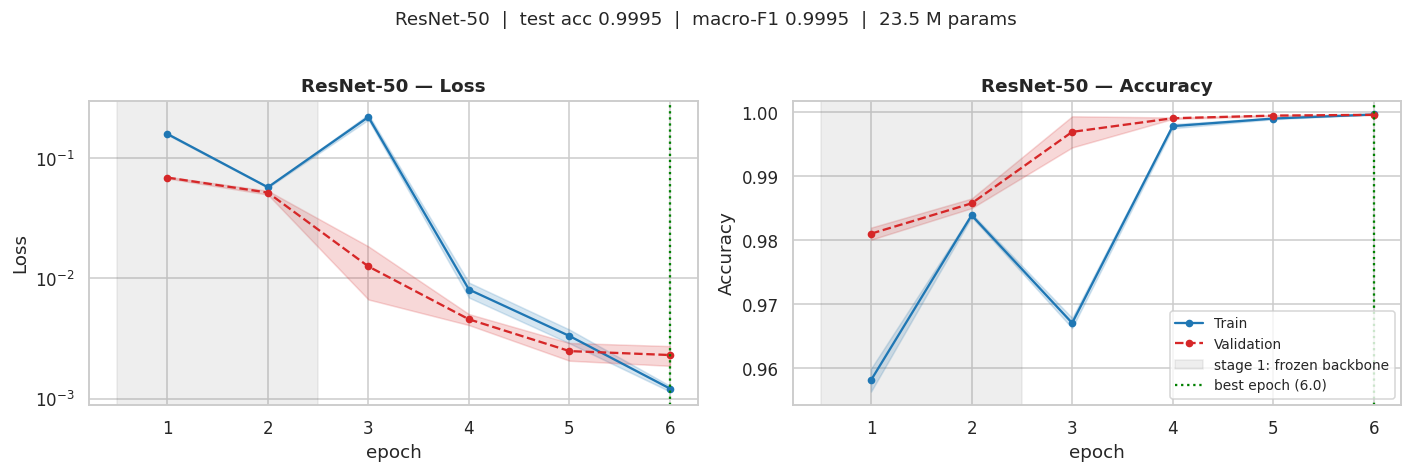

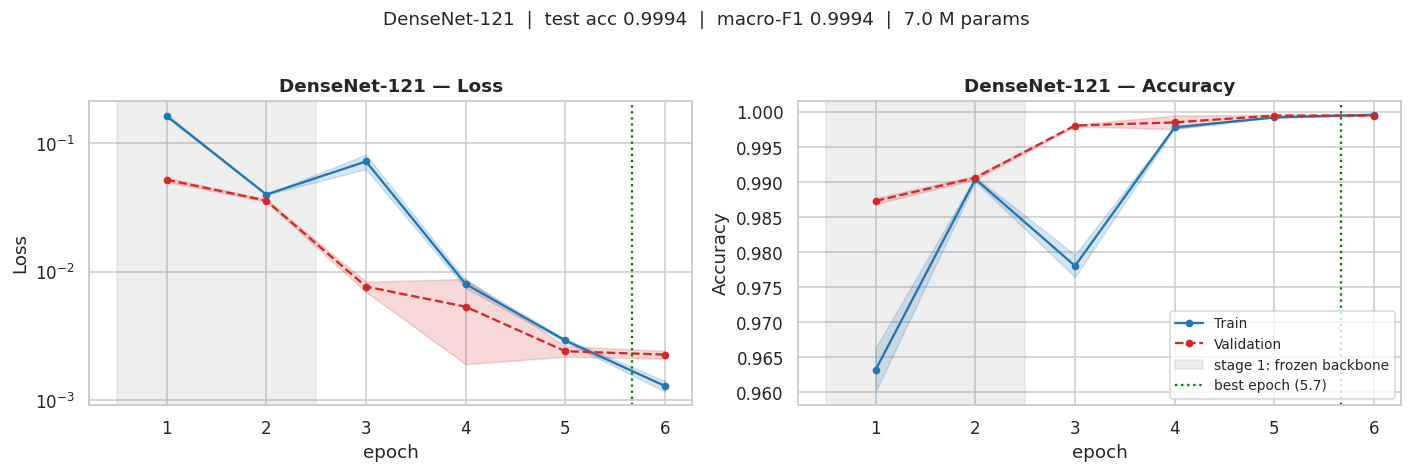

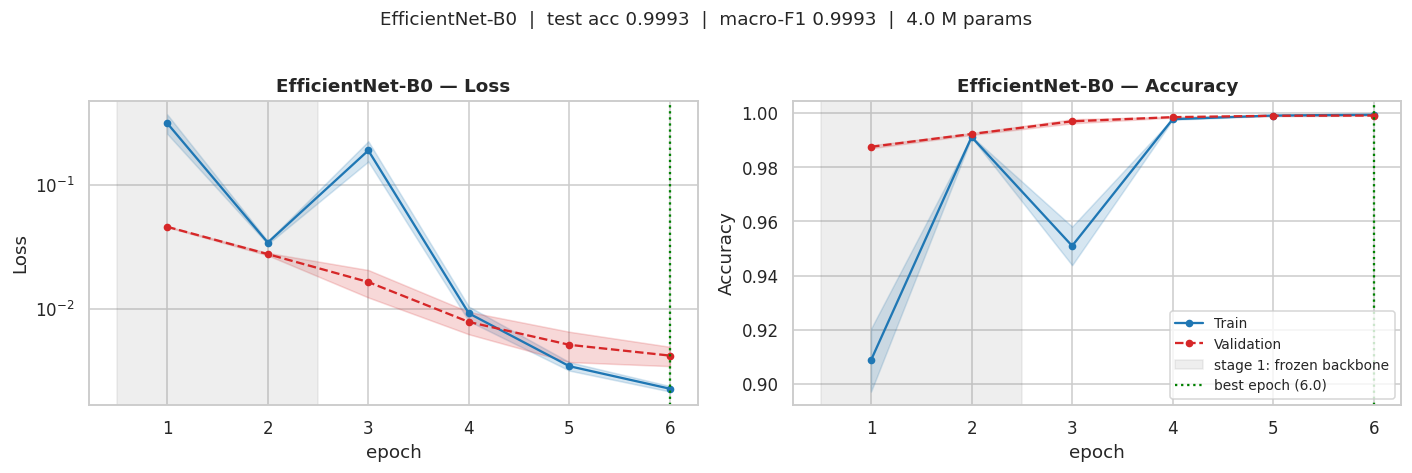

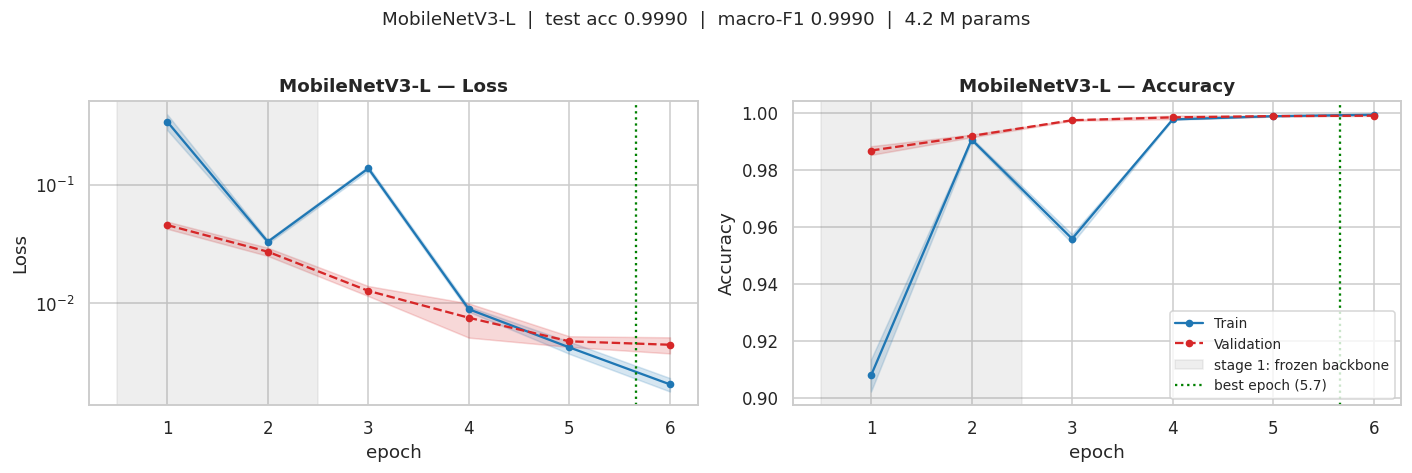

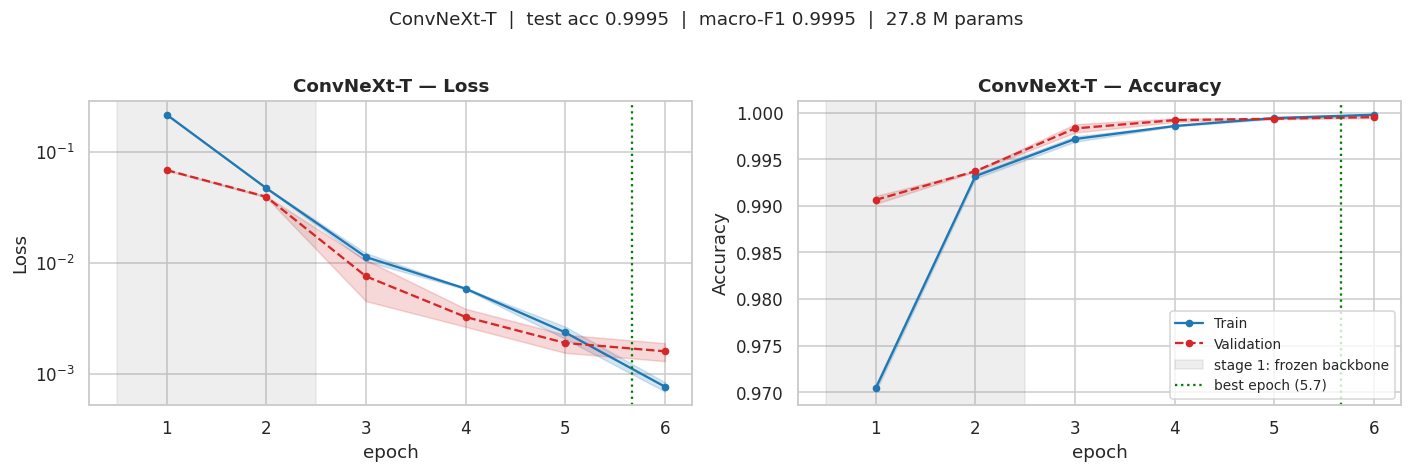

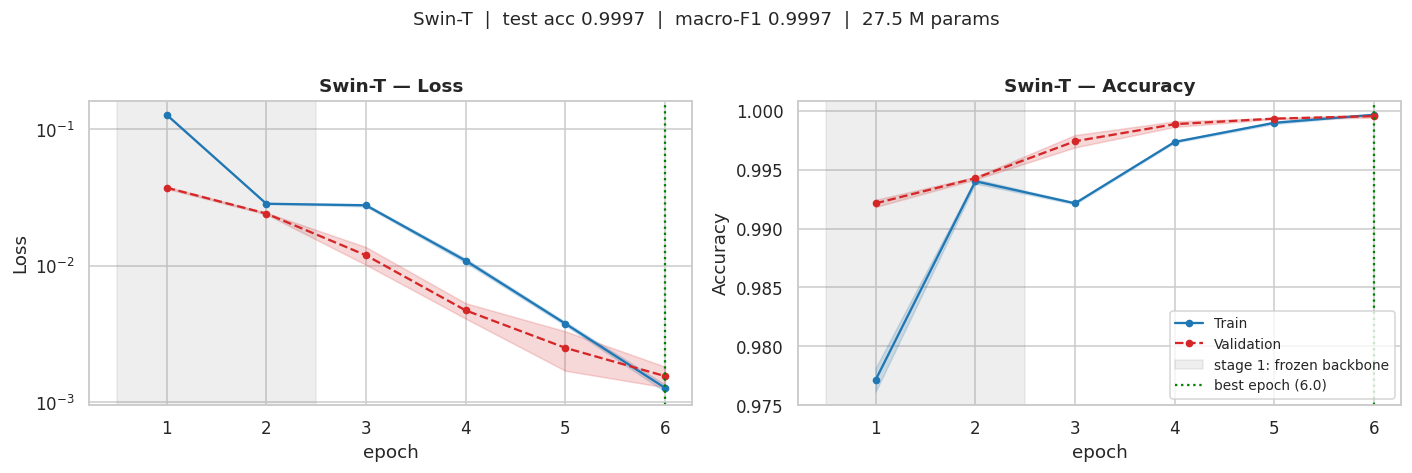

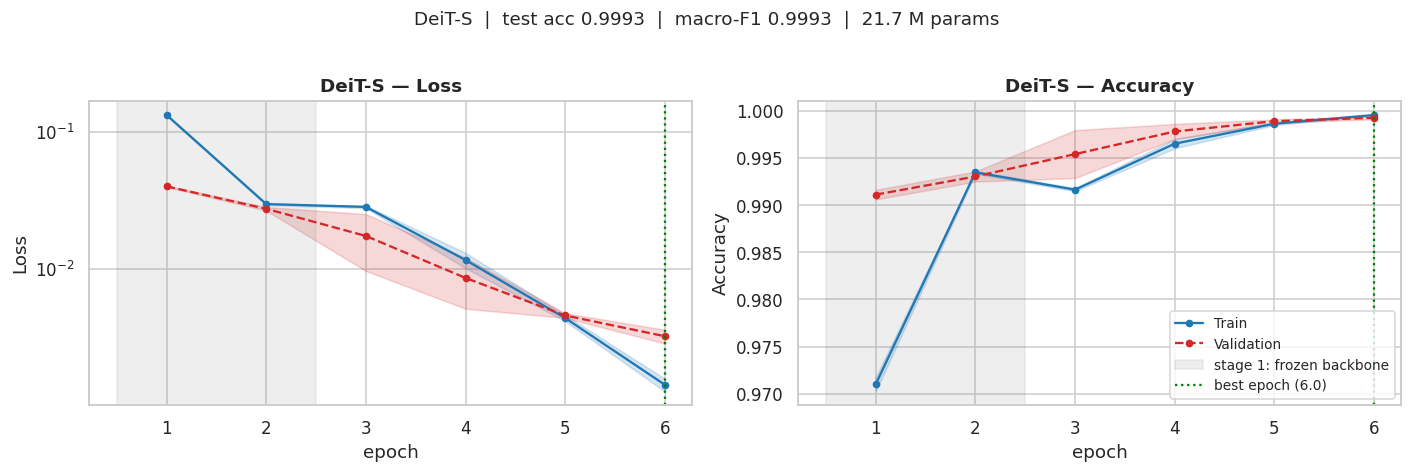

In [21]:
def stack_hist(key, field):
    return np.stack([np.array(r['history'][field], dtype=float) for r in main_runs if r['model'] == key])

def n_lp(key):
    return sum(p == 'linear_probe' for p in next(r for r in main_runs if r['model'] == key)['history']['phase'])

def plot_model_curves(key):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    lpn = n_lp(key); E = stack_hist(key, 'val_acc').shape[1]; ep = np.arange(1, E + 1)
    best = df_main[df_main.model == key].best_epoch.mean()
    for ax, (fld, title) in zip(axes, [('loss', 'Loss'), ('acc', 'Accuracy')]):
        for split, ls, lab, c in [('train', '-', 'Train', '#1f77b4'), ('val', '--', 'Validation', '#d62728')]:
            a = stack_hist(key, f'{split}_{fld}'); mu, sd = a.mean(0), a.std(0)
            ax.plot(ep, mu, ls, color=c, marker='o', ms=4, label=lab); ax.fill_between(ep, mu - sd, mu + sd, color=c, alpha=.18)
        if lpn: ax.axvspan(0.5, lpn + 0.5, color='grey', alpha=.13, label='stage 1: frozen backbone')
        ax.axvline(best, color='green', ls=':', label=f'best epoch ({best:.1f})')
        ax.set_xlabel('epoch'); ax.set_ylabel(title); ax.set_title(f'{key} — {title}'); ax.set_xticks(ep)
        if fld == 'loss': ax.set_yscale('log')
    axes[1].legend(loc='lower right')
    r = ALL.loc[key]
    fig.suptitle(f'{key}  |  test acc {r.test_acc:.4f}  |  macro-F1 {r.test_macro_f1:.4f}  |  {r.params_m:.1f} M params', y=1.02, fontsize=12)
    plt.tight_layout(); savefig(f'01_curves_{slugify(key)}')

for k in MODEL_ORDER: plot_model_curves(k)

<a class="anchor" id="sec10"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">10 · All backbones side by side</p>

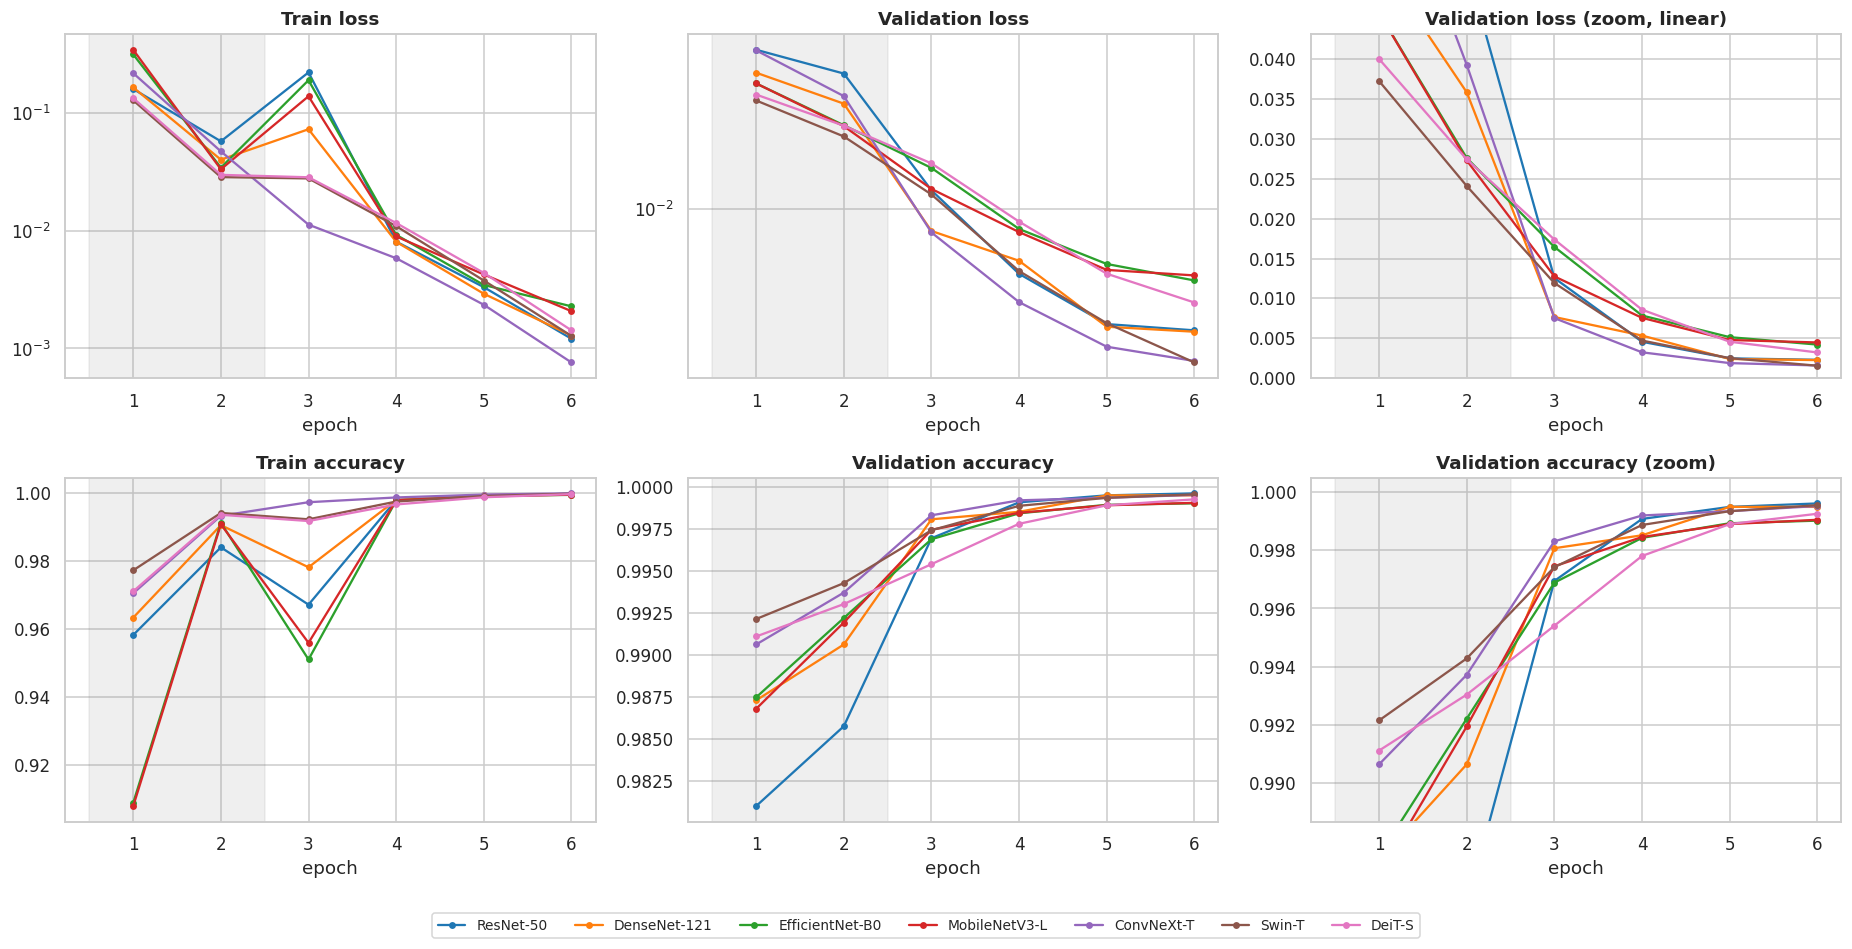

In [22]:
def plot_overlay():
    panels = [('train_loss', 'Train loss', True), ('val_loss', 'Validation loss', True), ('val_loss', 'Validation loss (zoom, linear)', False),
              ('train_acc', 'Train accuracy', False), ('val_acc', 'Validation accuracy', False), ('val_acc', 'Validation accuracy (zoom)', False)]
    fig, axes = plt.subplots(2, 3, figsize=(17, 8.5)); lpn = max(n_lp(k) for k in MODEL_ORDER)
    for i, (ax, (fld, title, logy)) in enumerate(zip(axes.ravel(), panels)):
        allv = []
        for k in MODEL_ORDER:
            mu = stack_hist(k, fld).mean(0); ep = np.arange(1, len(mu) + 1); allv.append(mu[1:])
            ax.plot(ep, mu, marker='o', ms=3.5, color=COLORS[k], label=k)
        if lpn: ax.axvspan(0.5, lpn + 0.5, color='grey', alpha=.12)
        ax.set_title(title); ax.set_xlabel('epoch'); ax.set_xticks(ep)
        if 'loss' in fld and i < 2: ax.set_yscale('log')
        if 'zoom' in title:
            v = np.concatenate(allv)
            if 'accuracy' in title: ax.set_ylim(np.percentile(v, 3) - 0.002, 1.0005)
            else: ax.set_ylim(0, np.percentile(v, 97) * 1.1)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(MODEL_ORDER), bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout(rect=(0, 0.03, 1, 1)); savefig('02_overlay_curves')
plot_overlay()

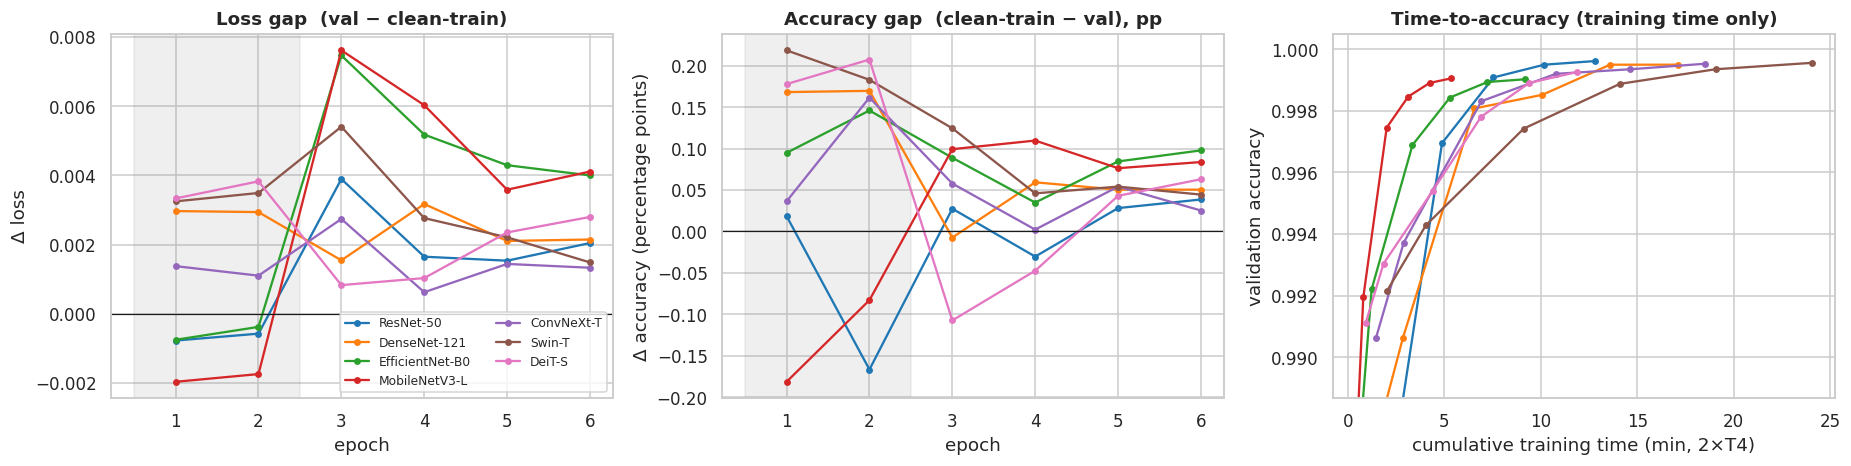

In [23]:
# ---- generalisation gap (clean train subset, no augmentation) + time-to-accuracy ----
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4)); lpn = max(n_lp(k) for k in MODEL_ORDER)
for k in MODEL_ORDER:
    g_loss = (stack_hist(k, 'val_loss') - stack_hist(k, 'trainclean_loss')).mean(0)
    g_acc = (stack_hist(k, 'trainclean_acc') - stack_hist(k, 'val_acc')).mean(0) * 100
    ep = np.arange(1, len(g_loss) + 1)
    axes[0].plot(ep, g_loss, marker='o', ms=3.5, color=COLORS[k], label=k)
    axes[1].plot(ep, g_acc, marker='o', ms=3.5, color=COLORS[k])
for ax, t, yl in zip(axes[:2], ['Loss gap  (val − clean-train)', 'Accuracy gap  (clean-train − val), pp'], ['Δ loss', 'Δ accuracy (percentage points)']):
    ax.axhline(0, color='k', lw=.8); ax.axvspan(0.5, lpn + .5, color='grey', alpha=.12); ax.set_title(t); ax.set_xlabel('epoch'); ax.set_ylabel(yl)
axes[0].legend(ncol=2, fontsize=8)
for k in MODEL_ORDER:
    t = stack_hist(k, 'cum_time').mean(0) / 60; va = stack_hist(k, 'val_acc').mean(0)
    axes[2].plot(t, va, marker='o', ms=3.5, color=COLORS[k], label=k)
axes[2].set_title('Time-to-accuracy (training time only)'); axes[2].set_xlabel('cumulative training time (min, 2×T4)'); axes[2].set_ylabel('validation accuracy')
v = np.concatenate([stack_hist(k, 'val_acc').mean(0)[1:] for k in MODEL_ORDER]); axes[2].set_ylim(np.percentile(v, 3) - 0.002, 1.0005)
plt.tight_layout(); savefig('03_gap_and_time_to_accuracy')

<a class="anchor" id="sec11"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">11 · Metric comparison</p>

Bar height = mean over seeds, error bar = ±1 std. Differences smaller than the error bars are **not** meaningful; a formal significance test follows in section 13.

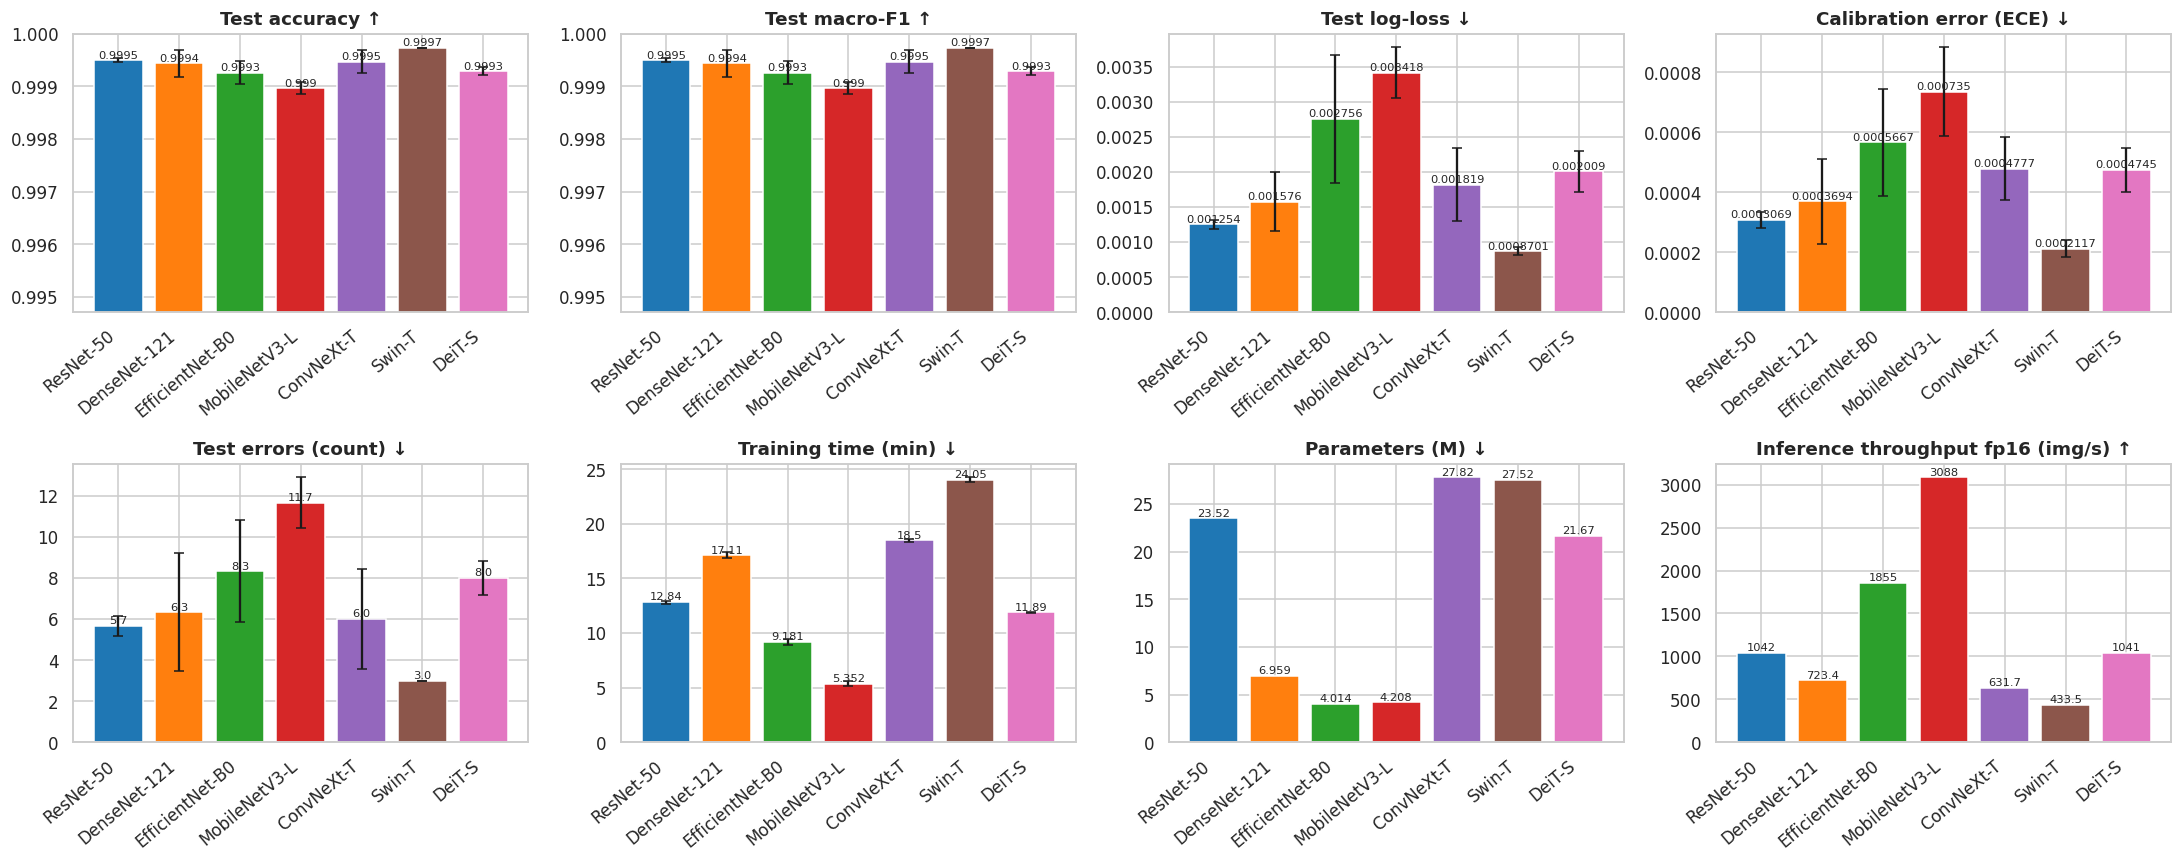

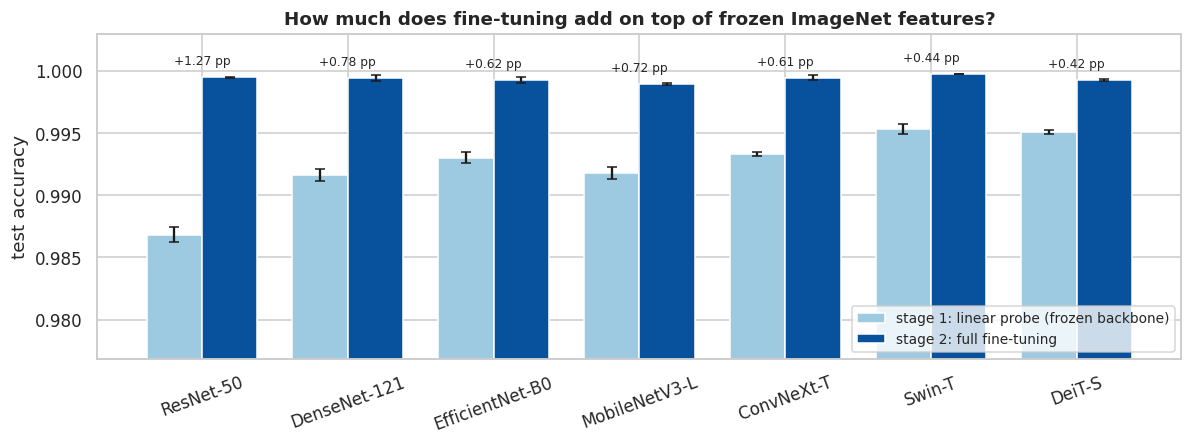

In [24]:
bar_specs = [('test_acc', 'Test accuracy ↑', 'zoom'), ('test_macro_f1', 'Test macro-F1 ↑', 'zoom'), ('test_log_loss', 'Test log-loss ↓', None),
             ('test_ece', 'Calibration error (ECE) ↓', None), ('test_n_errors', 'Test errors (count) ↓', None),
             ('train_time_min', 'Training time (min) ↓', None), ('params_m', 'Parameters (M) ↓', None), ('throughput_fp16', 'Inference throughput fp16 (img/s) ↑', None)]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, (col, title, zoom) in zip(axes.ravel(), bar_specs):
    vals = ALL.loc[MODEL_ORDER, col].values; err = SUM_STD.loc[MODEL_ORDER, col].values if col in SUM_STD.columns else None
    ax.bar(range(len(MODEL_ORDER)), vals, yerr=err, capsize=3, color=[COLORS[k] for k in MODEL_ORDER])
    ax.set_xticks(range(len(MODEL_ORDER))); ax.set_xticklabels(MODEL_ORDER, rotation=40, ha='right'); ax.set_title(title)
    if zoom: ax.set_ylim(vals.min() - 0.004 - (0 if err is None else err.max()), min(1.0, vals.max() + 0.002 + (0 if err is None else err.max())))
    for i, v in enumerate(vals): ax.text(i, v, f'{v:.4g}' if col != 'test_n_errors' else f'{v:.1f}', ha='center', va='bottom', fontsize=7.5)
plt.tight_layout(); savefig('04_metric_bars')

# ---- linear probe vs. fine-tuning ----
fig, ax = plt.subplots(figsize=(11, 4.2)); w = 0.38; x = np.arange(len(MODEL_ORDER))
lp_v, ft_v = ALL.loc[MODEL_ORDER, 'lp_test_acc'].values, ALL.loc[MODEL_ORDER, 'test_acc'].values
ax.bar(x - w/2, lp_v, w, yerr=SUM_STD.loc[MODEL_ORDER, 'lp_test_acc'], capsize=3, label='stage 1: linear probe (frozen backbone)', color='#9ecae1')
ax.bar(x + w/2, ft_v, w, yerr=SUM_STD.loc[MODEL_ORDER, 'test_acc'], capsize=3, label='stage 2: full fine-tuning', color='#08519c')
for i, (a, b) in enumerate(zip(lp_v, ft_v)): ax.text(i, max(a, b) + 0.001, f'+{(b-a)*100:.2f} pp', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(MODEL_ORDER, rotation=20); ax.set_ylabel('test accuracy')
ax.set_ylim(np.nanmin(lp_v) - 0.01, 1.003); ax.set_title('How much does fine-tuning add on top of frozen ImageNet features?'); ax.legend(loc='lower right')
plt.tight_layout(); savefig('05_linear_probe_vs_finetune')

<a class="anchor" id="sec12"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">12 · Where do the models make mistakes?</p>
Confusion matrices (first seed), per-class F1 (mean over seeds) and reliability diagrams (is the predicted confidence trustworthy?).

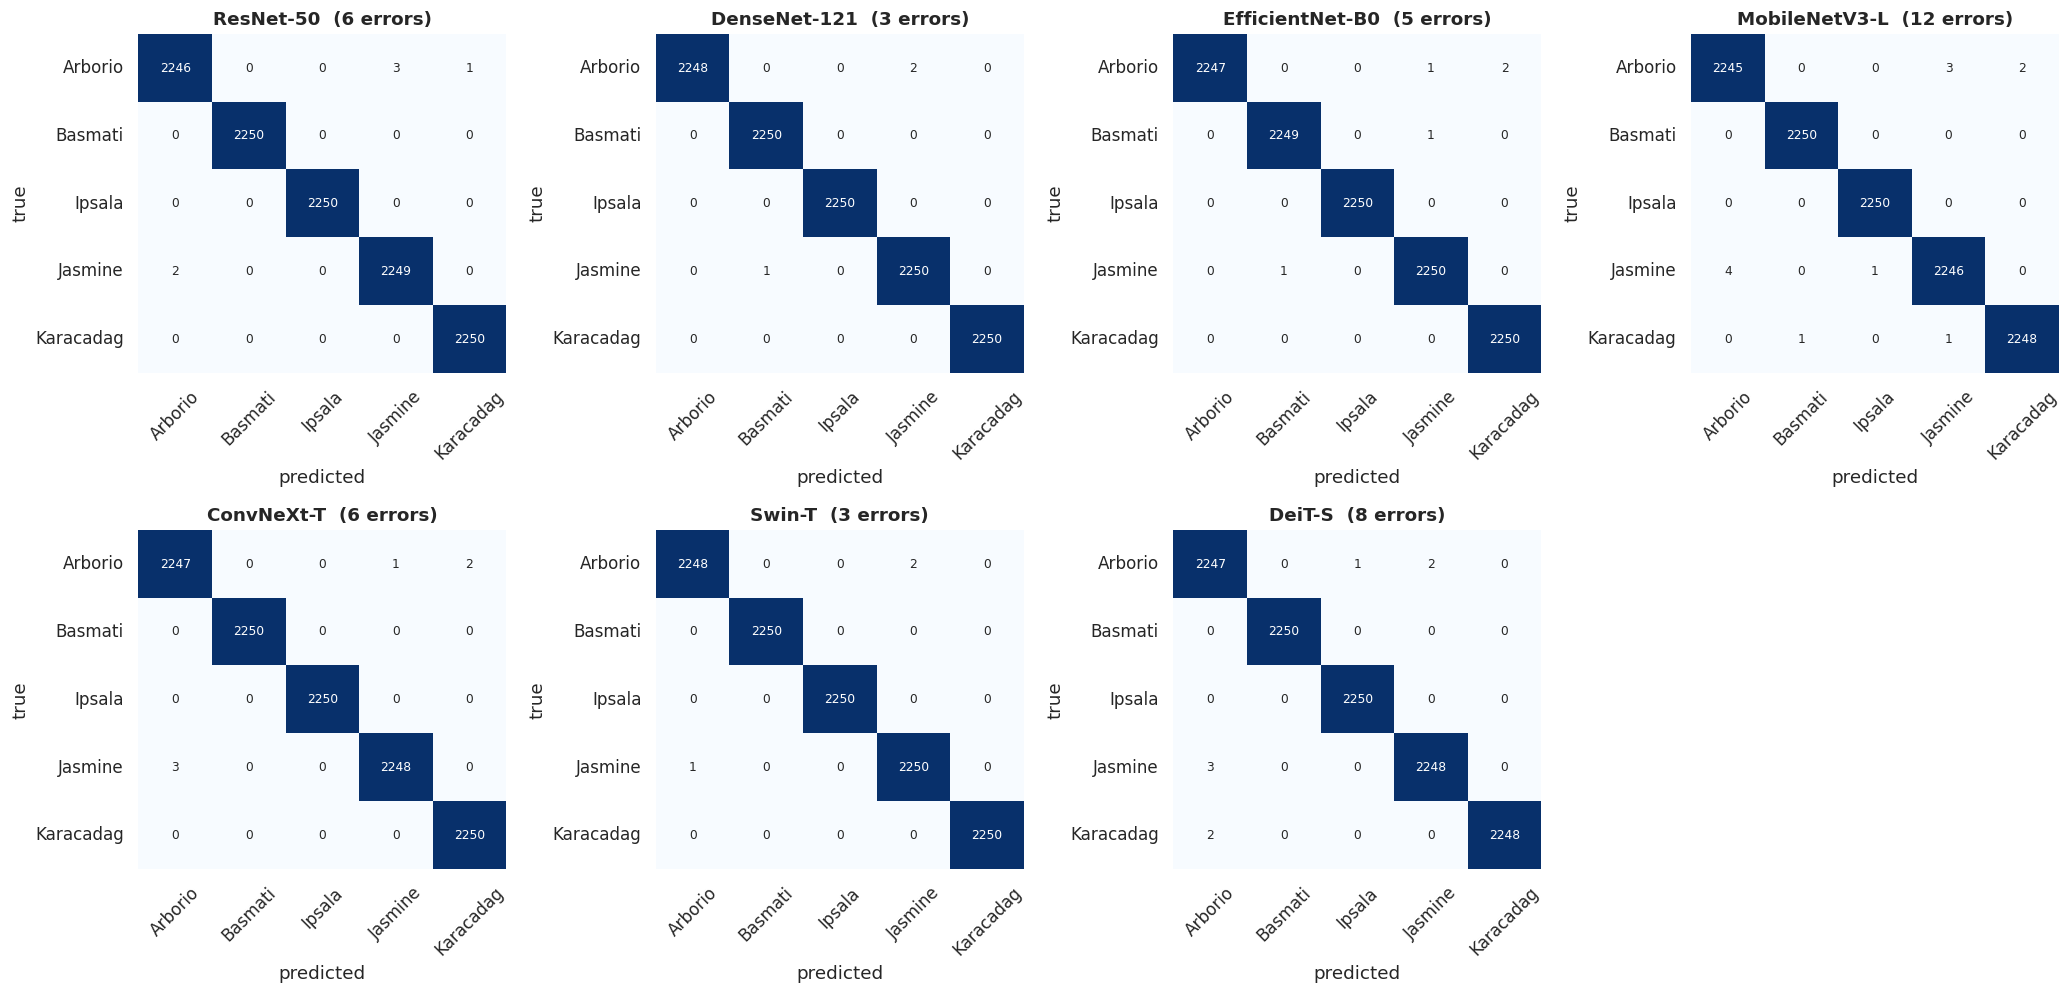

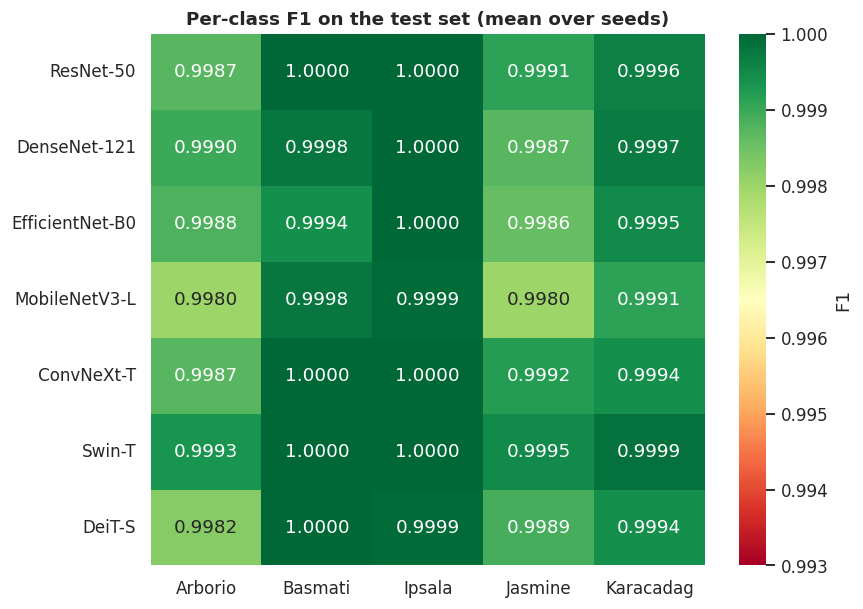

,Arborio,Basmati,Ipsala,Jasmine,Karacadag
ResNet-50,0.9987,1.0000,1.0000,0.9991,0.9996
DenseNet-121,0.9990,0.9998,1.0000,0.9987,0.9997
EfficientNet-B0,0.9988,0.9994,1.0000,0.9986,0.9995
MobileNetV3-L,0.9980,0.9998,0.9999,0.9980,0.9991
ConvNeXt-T,0.9987,1.0000,1.0000,0.9992,0.9994
Swin-T,0.9993,1.0000,1.0000,0.9995,0.9999
DeiT-S,0.9982,1.0000,0.9999,0.9989,0.9994


In [25]:
runs_seed0 = {r['model']: r for r in main_runs if r['seed'] == SEED0}
nrow = math.ceil(len(MODEL_ORDER) / 4)
fig, axes = plt.subplots(nrow, 4, figsize=(19, 4.6 * nrow))
for ax in axes.ravel(): ax.axis('off')
for ax, k in zip(axes.ravel(), MODEL_ORDER):
    ax.axis('on'); cm = np.array(runs_seed0[k]['test_metrics']['confusion']); cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, ax=ax, cmap='Blues', vmin=0, vmax=1, cbar=False, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                annot=np.array([[f'{v}' for v in row] for row in cm]), fmt='', annot_kws={'fontsize': 8})
    ax.set_title(f'{k}  ({runs_seed0[k]["test_metrics"]["n_errors"]} errors)'); ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); savefig('06_confusion_matrices')

# ---- per-class F1 ----
f1 = pd.DataFrame({k: np.mean([r['test_metrics']['per_class_f1'] for r in main_runs if r['model'] == k], axis=0) for k in MODEL_ORDER}, index=CLASS_NAMES).T
fig, ax = plt.subplots(figsize=(8, 0.6 * len(MODEL_ORDER) + 1.5))
sns.heatmap(f1, annot=True, fmt='.4f', cmap='RdYlGn', vmin=max(0.9, f1.values.min() - 0.005), vmax=1, ax=ax, cbar_kws={'label': 'F1'})
ax.set_title('Per-class F1 on the test set (mean over seeds)'); plt.tight_layout(); savefig('07_per_class_f1')
display(f1.round(4))

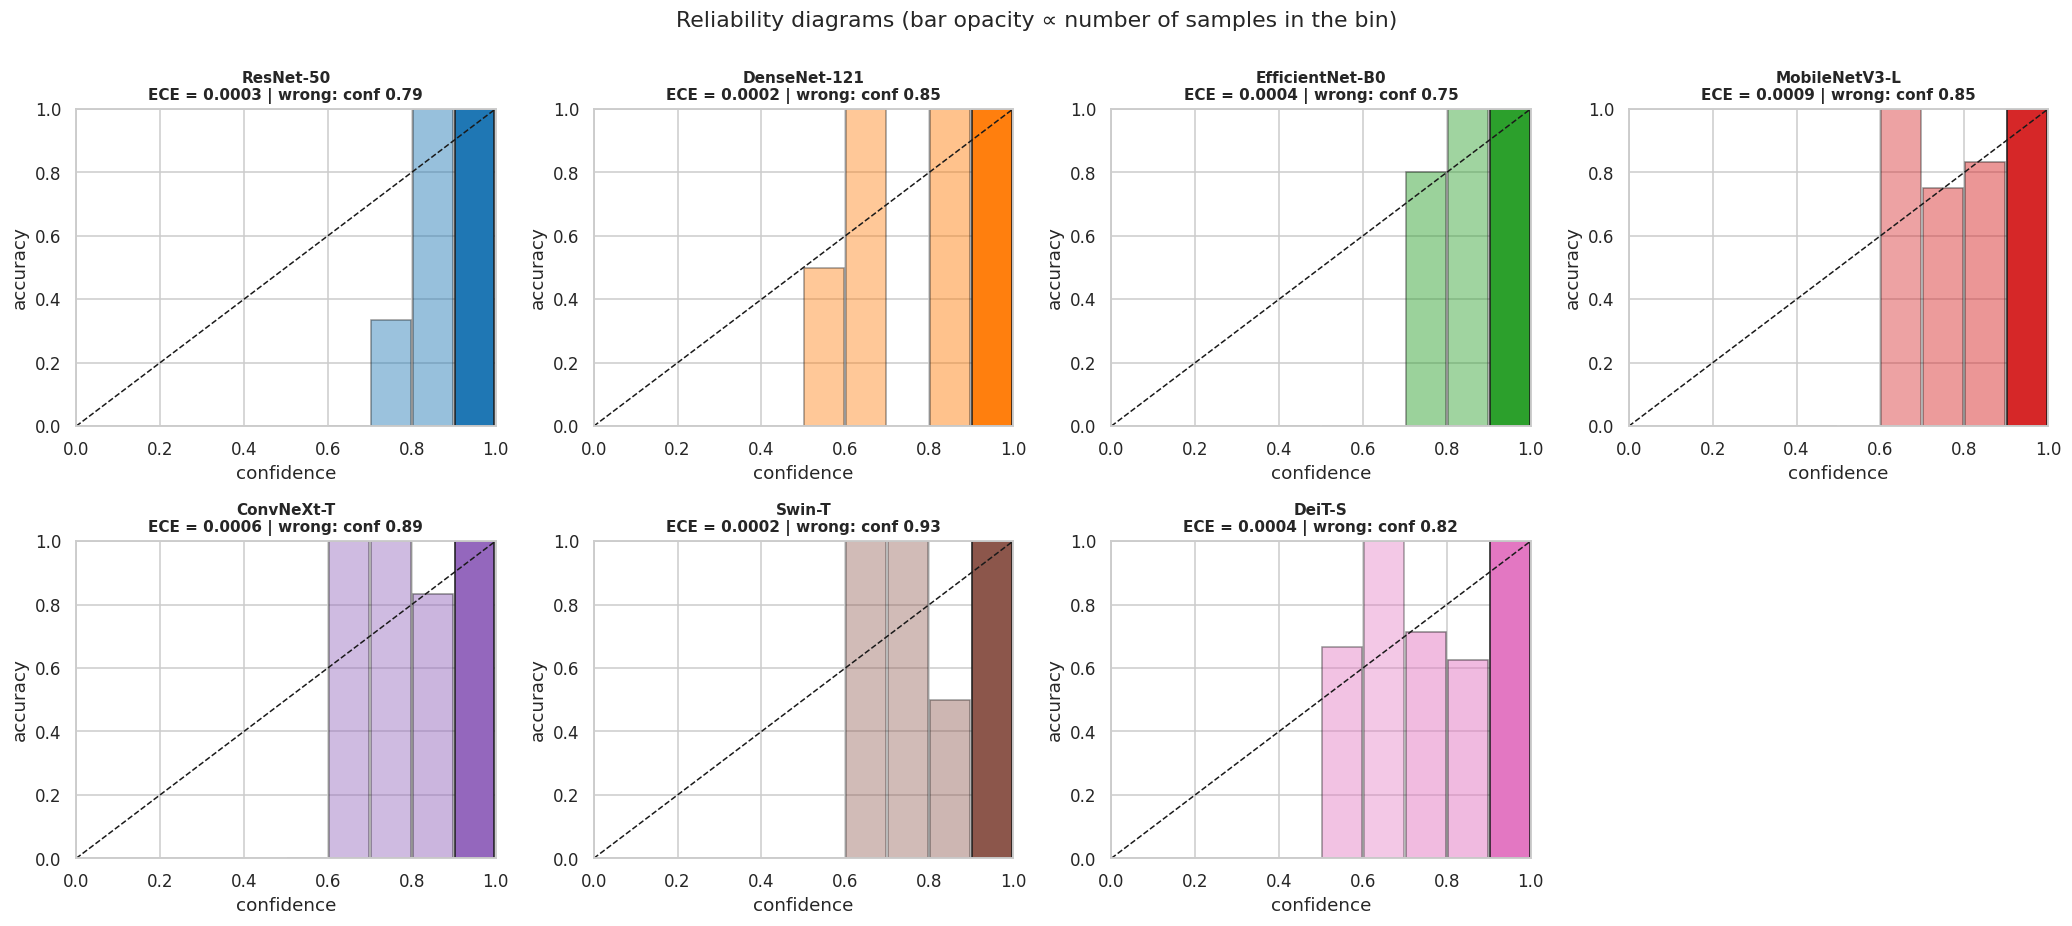

In [26]:
def load_probs(key, seed):
    d = np.load(RES_DIR / f'{slugify(key)}_s{seed}_test.npz')
    return d['probs'].astype(np.float64), d['y'], d['idx']

# ---- reliability diagrams ----
fig, axes = plt.subplots(nrow, 4, figsize=(19, 4.2 * nrow))
for ax in axes.ravel(): ax.axis('off')
edges = np.linspace(0, 1, 11)
for ax, k in zip(axes.ravel(), MODEL_ORDER):
    ax.axis('on'); p, yy, _ = load_probs(k, SEED0); conf, ok = p.max(1), (p.argmax(1) == yy)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum(): ax.bar((lo + hi) / 2, ok[m].mean(), width=0.095, color=COLORS[k], alpha=0.35 + 0.65 * min(1, np.log10(m.sum() + 1) / 4), edgecolor='k')
    ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title(f'{k}\nECE = {ece_score(p, yy):.4f} | wrong: conf {conf[~ok].mean() if (~ok).any() else float("nan"):.2f}', fontsize=10)
    ax.set_xlabel('confidence'); ax.set_ylabel('accuracy')
plt.suptitle('Reliability diagrams (bar opacity ∝ number of samples in the bin)', y=1.0)
plt.tight_layout(); savefig('08_reliability')

<a class="anchor" id="sec13"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">13 · Are the differences statistically real?</p>

**McNemar's exact test** compares two classifiers on the *same* test images: only the images where exactly one of the two is wrong matter. `p > 0.05` ⇒ the two models are statistically indistinguishable on this test set (no correction for multiple comparisons is applied, so the p-values are indicative). Then we look at the images that fool several models at once.

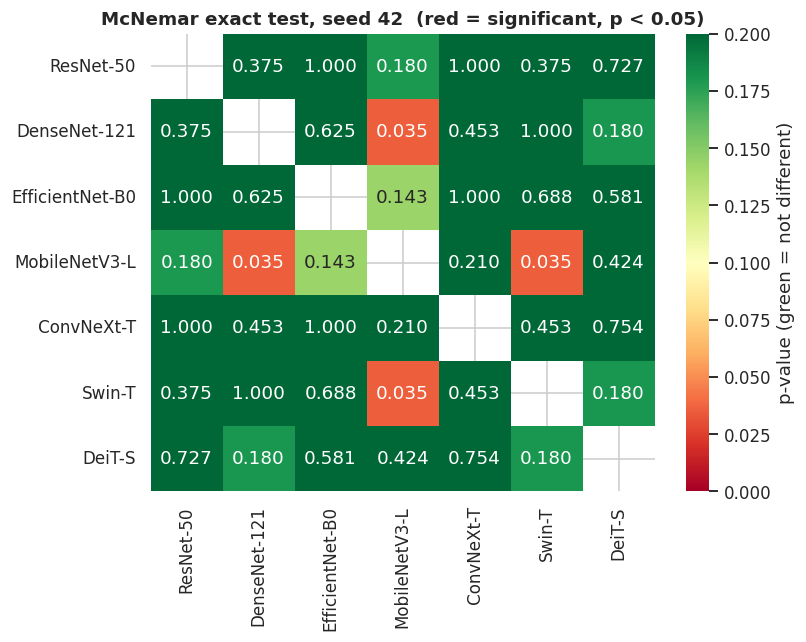

number of test images misclassified by k models: {0: 11226, 1: 15, 2: 5, 3: 3, 4: 1, 5: 1, 6: 0, 7: 0}


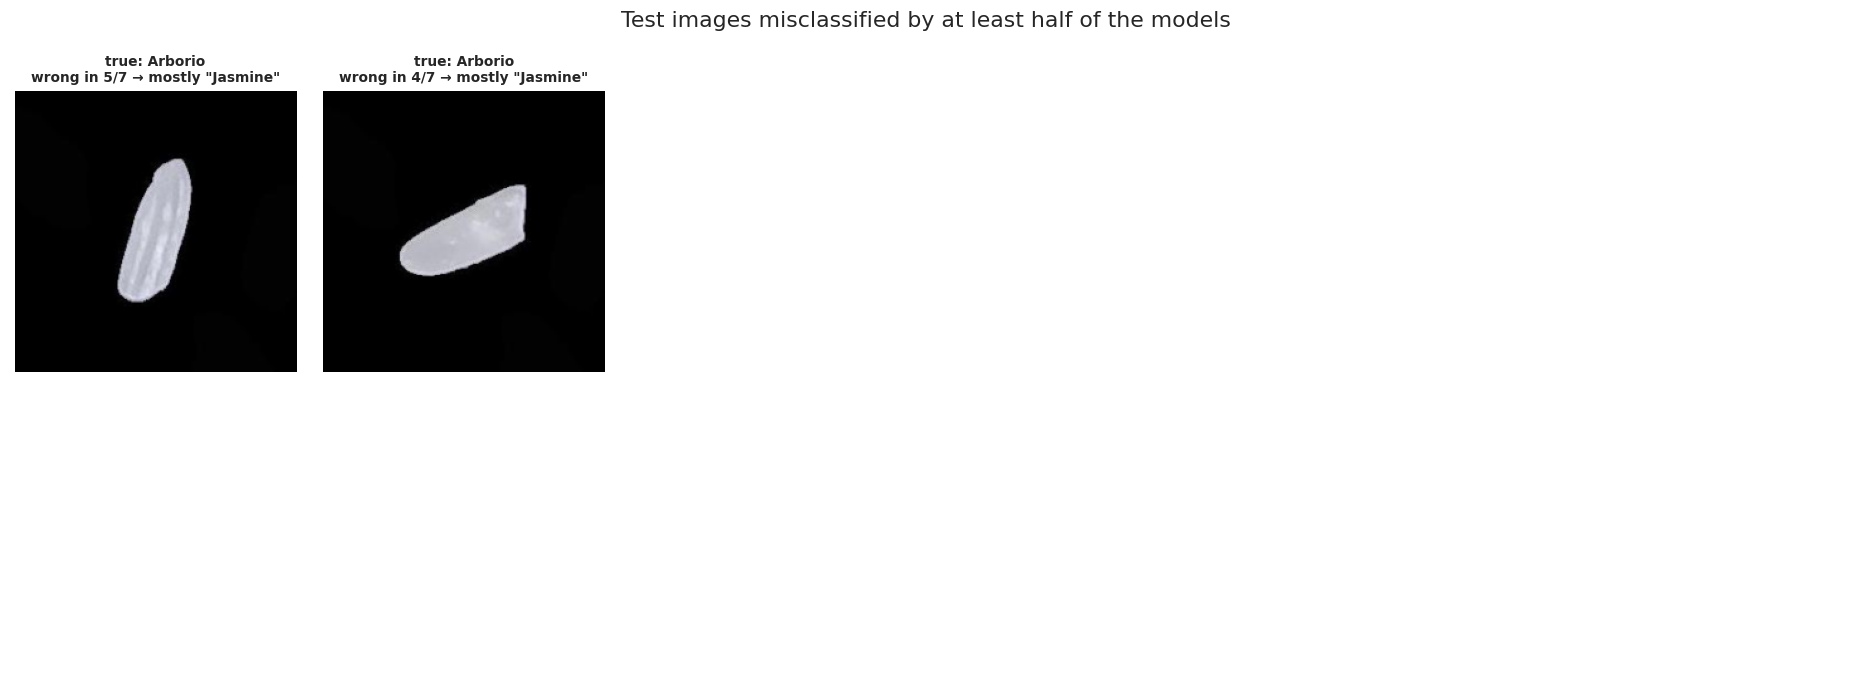


Most frequent confusions of the most accurate model (Swin-T): Arborio→Jasmine: 2; Jasmine→Arborio: 1


In [27]:
P = {k: load_probs(k, SEED0) for k in MODEL_ORDER}
y_t, idx_t = P[MODEL_ORDER[0]][1], P[MODEL_ORDER[0]][2]
wrong = {k: P[k][0].argmax(1) != y_t for k in MODEL_ORDER}
pm = pd.DataFrame(np.nan, index=MODEL_ORDER, columns=MODEL_ORDER)
for a in MODEL_ORDER:
    for b in MODEL_ORDER:
        if a == b: continue
        n01, n10 = int((~wrong[a] & wrong[b]).sum()), int((wrong[a] & ~wrong[b]).sum())
        pm.loc[a, b] = 1.0 if n01 + n10 == 0 else binomtest(min(n01, n10), n01 + n10, 0.5).pvalue
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(pm, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=0.2, mask=pm.isna(), ax=ax, cbar_kws={'label': 'p-value (green = not different)'})
ax.set_title(f'McNemar exact test, seed {SEED0}  (red = significant, p < 0.05)'); plt.tight_layout(); savefig('09_mcnemar')

# ---- images that fool several models ----
n_wrong = np.sum([wrong[k] for k in MODEL_ORDER], axis=0)
print('number of test images misclassified by k models:', {int(k): int((n_wrong == k).sum()) for k in range(len(MODEL_ORDER) + 1)})
thr = max(2, math.ceil(len(MODEL_ORDER) / 2)); hard = np.where(n_wrong >= thr)[0]
hard = hard[np.argsort(-n_wrong[hard])][:12]
if len(hard):
    fig, axes = plt.subplots(2, 6, figsize=(17, 6.2))
    for ax in axes.ravel(): ax.axis('off')
    for ax, i in zip(axes.ravel(), hard):
        ax.imshow(X_np[idx_t[i]]); votes = [CLASS_NAMES[P[k][0][i].argmax()] for k in MODEL_ORDER if wrong[k][i]]
        common = max(set(votes), key=votes.count)
        ax.set_title(f'true: {CLASS_NAMES[y_t[i]]}\nwrong in {n_wrong[i]}/{len(MODEL_ORDER)} → mostly "{common}"', fontsize=9)
    plt.suptitle('Test images misclassified by at least half of the models', y=1.0); plt.tight_layout(); savefig('10_hard_examples')
else:
    print('No test image is misclassified by half of the models or more.')

best_model = ALL.loc[MODEL_ORDER, 'test_acc'].idxmax()
cm = np.array(runs_seed0[best_model]['test_metrics']['confusion']); np.fill_diagonal(cm, 0)
pairs = sorted([(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm[i, j] > 0], reverse=True)[:5]
print(f'\nMost frequent confusions of the most accurate model ({best_model}): ' + '; '.join(f'{t}→{p}: {n}' for n, t, p in pairs))

<a class="anchor" id="sec14"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">14 · Accuracy vs. cost (Pareto view)</p>

A model is on the **Pareto frontier** if no other model is both at least as accurate *and* cheaper. Bubble area ∝ number of parameters.

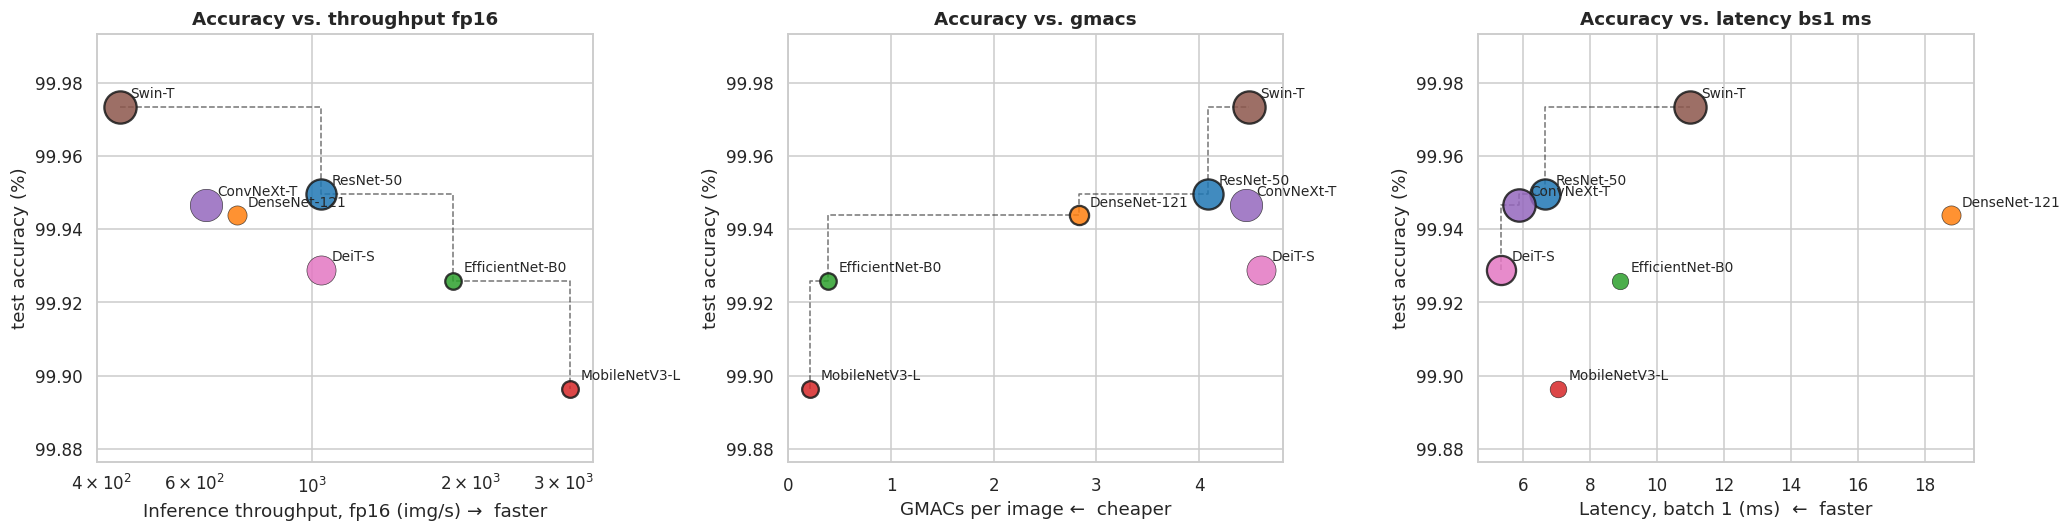

In [28]:
def pareto_mask(x, y, x_higher_better):
    n = len(x); keep = np.ones(n, bool)
    for i in range(n):
        for j in range(n):
            if i == j: continue
            better_x = x[j] >= x[i] if x_higher_better else x[j] <= x[i]
            strict = (y[j] > y[i]) or ((x[j] > x[i]) if x_higher_better else (x[j] < x[i]))
            if y[j] >= y[i] and better_x and strict: keep[i] = False; break
    return keep

specs = [('throughput_fp16', 'Inference throughput, fp16 (img/s) →  faster', True, True),
         ('gmacs', 'GMACs per image ←  cheaper', False, False), ('latency_bs1_ms', 'Latency, batch 1 (ms)  ←  faster', False, False)]
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
ys = ALL.loc[MODEL_ORDER, 'test_acc'].values * 100
for ax, (col, xl, hib, logx) in zip(axes, specs):
    xs = ALL.loc[MODEL_ORDER, col].values; keep = pareto_mask(xs, ys, hib)
    for i, k in enumerate(MODEL_ORDER):
        ax.scatter(xs[i], ys[i], s=60 + 14 * ALL.loc[k, 'params_m'], color=COLORS[k], alpha=.85, edgecolor='k', lw=1.5 if keep[i] else .4, zorder=3)
        ax.annotate(k, (xs[i], ys[i]), textcoords='offset points', xytext=(7, 6), fontsize=9)
    fx, fy = xs[keep], ys[keep]; o = np.argsort(fx); ax.step(fx[o], fy[o], where='post' if hib else 'pre', color='k', lw=1, ls='--', alpha=.6, zorder=1)
    if logx: ax.set_xscale('log')
    ax.set_xlabel(xl); ax.set_ylabel('test accuracy (%)'); ax.set_title('Accuracy vs. ' + col.replace('_', ' '))
    pad = max(0.02, (ys.max() - ys.min()) * 0.15); ax.set_ylim(ys.min() - pad, ys.max() + pad)
plt.tight_layout(); savefig('11_pareto')

<a class="anchor" id="sec15"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">15 · Data-efficiency results</p>

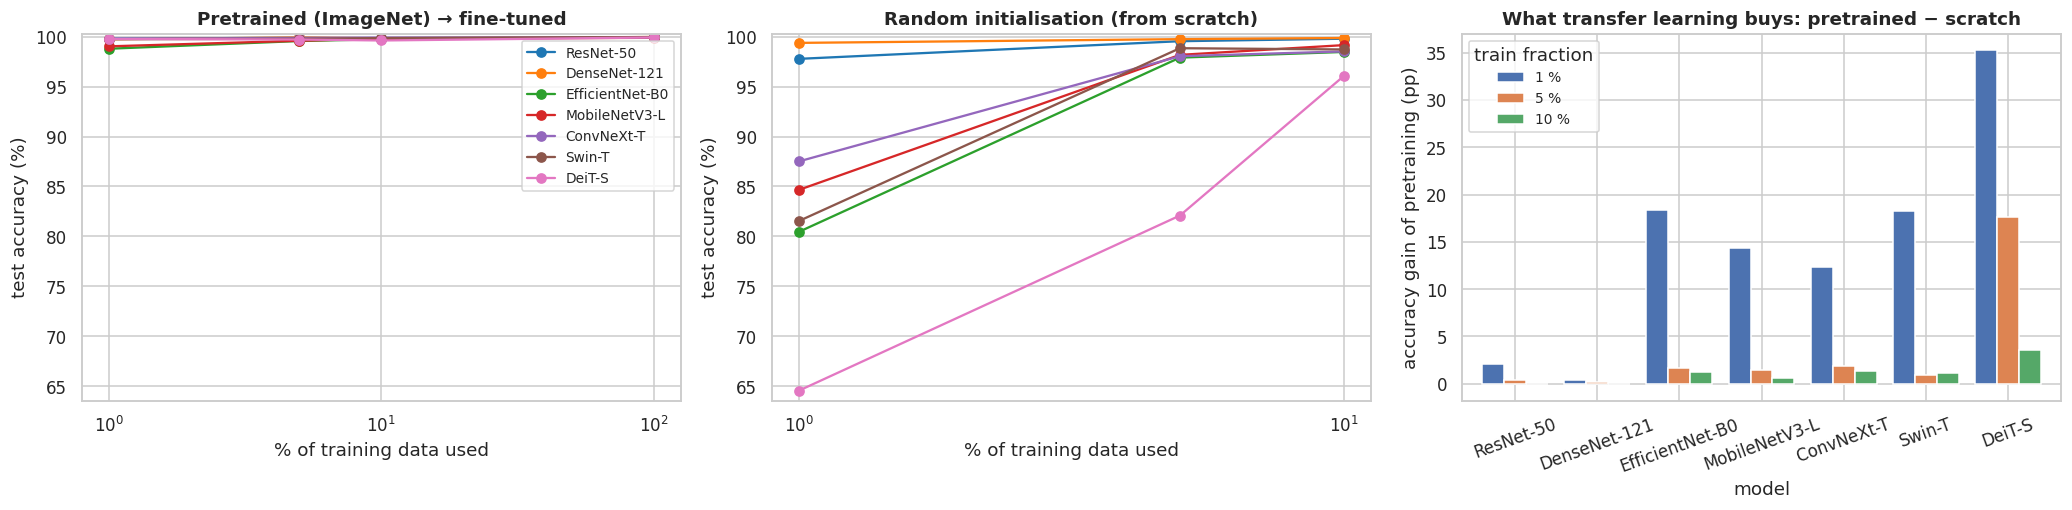

pretrained        False                   True                         
frac               0.01    0.05    0.10    0.01    0.05    0.10    1.00
model                                                                  
ConvNeXt-T       0.8751  0.9805  0.9853  0.9980  0.9988  0.9992  0.9995
DeiT-S           0.6455  0.8209  0.9609  0.9979  0.9972  0.9963  0.9993
DenseNet-121     0.9939  0.9976  0.9988  0.9975  0.9993  0.9984  0.9997
EfficientNet-B0  0.8046  0.9791  0.9848  0.9880  0.9957  0.9975  0.9996
MobileNetV3-L    0.8466  0.9819  0.9916  0.9904  0.9960  0.9980  0.9989
ResNet-50        0.9779  0.9956  0.9980  0.9981  0.9989  0.9981  0.9995
Swin-T           0.8154  0.9885  0.9873  0.9975  0.9980  0.9987  0.9997

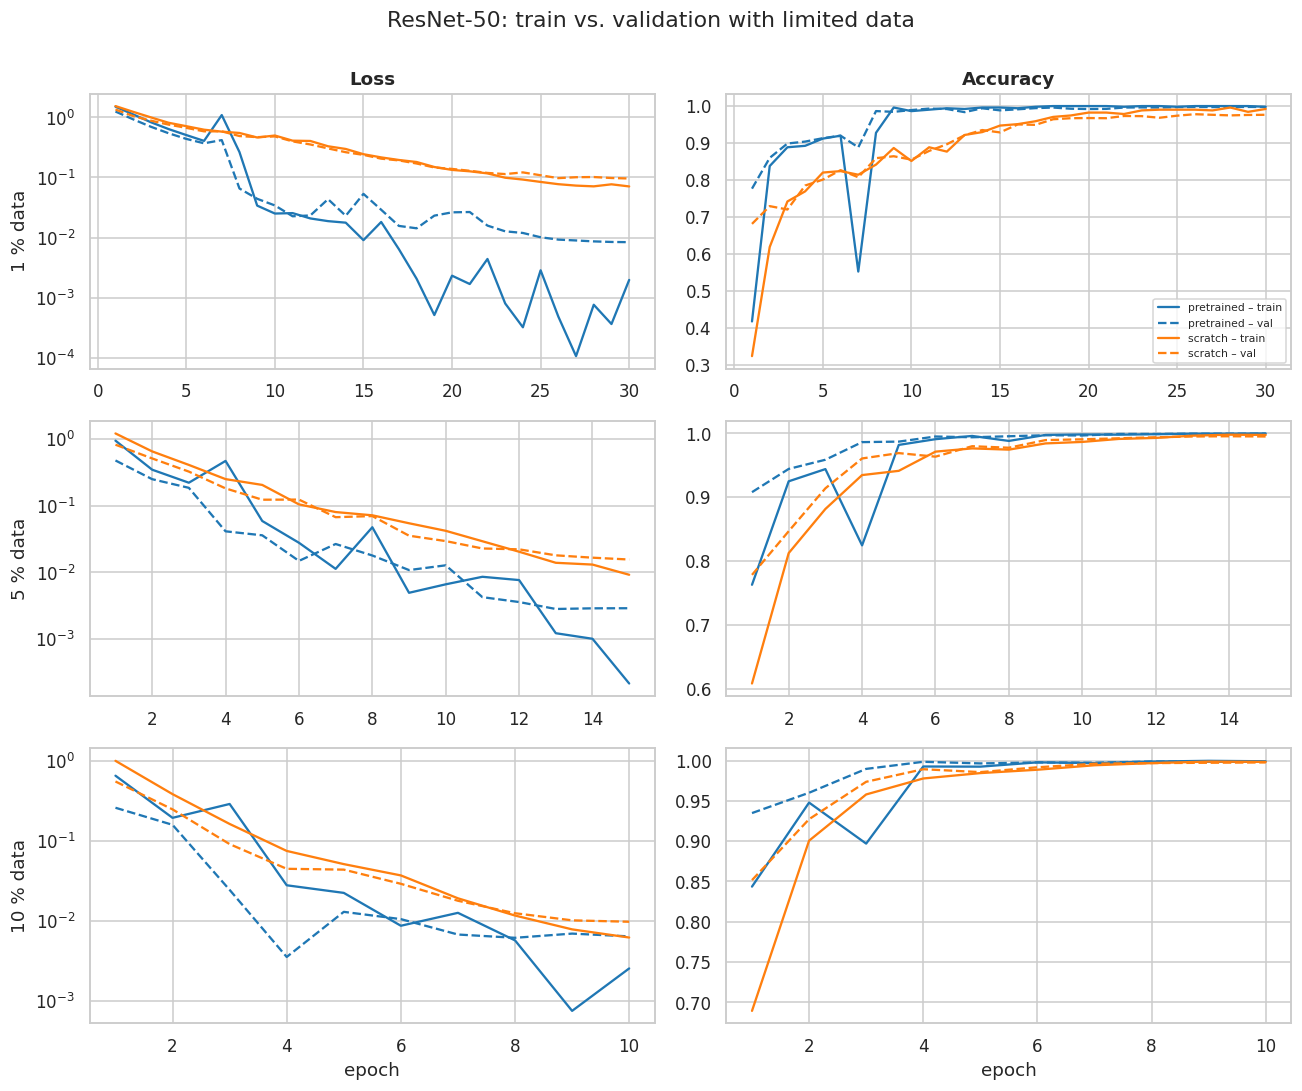

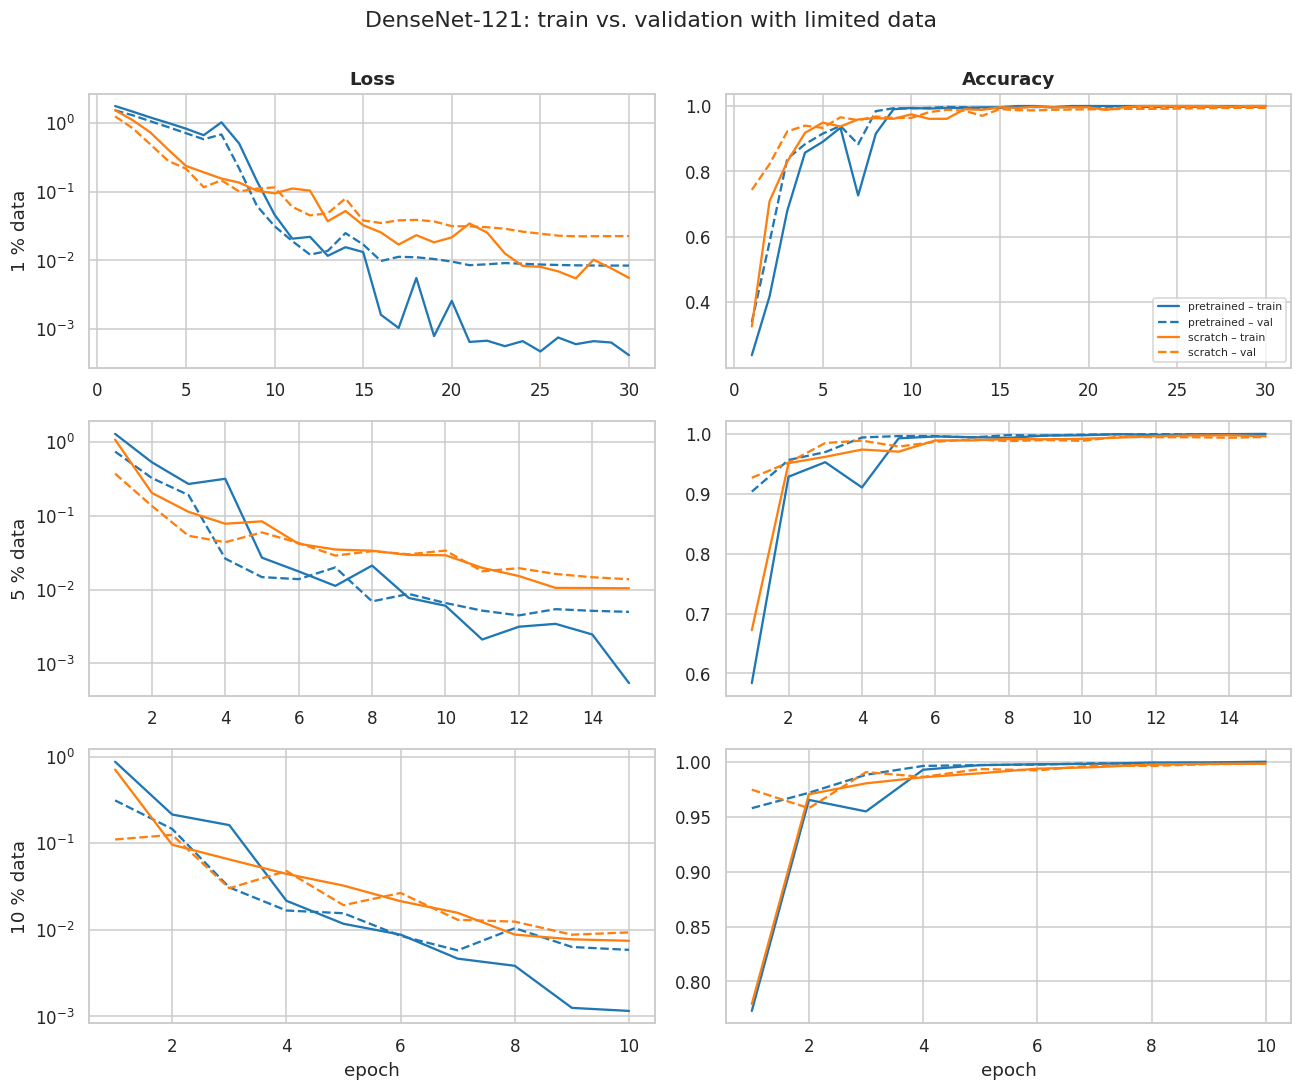

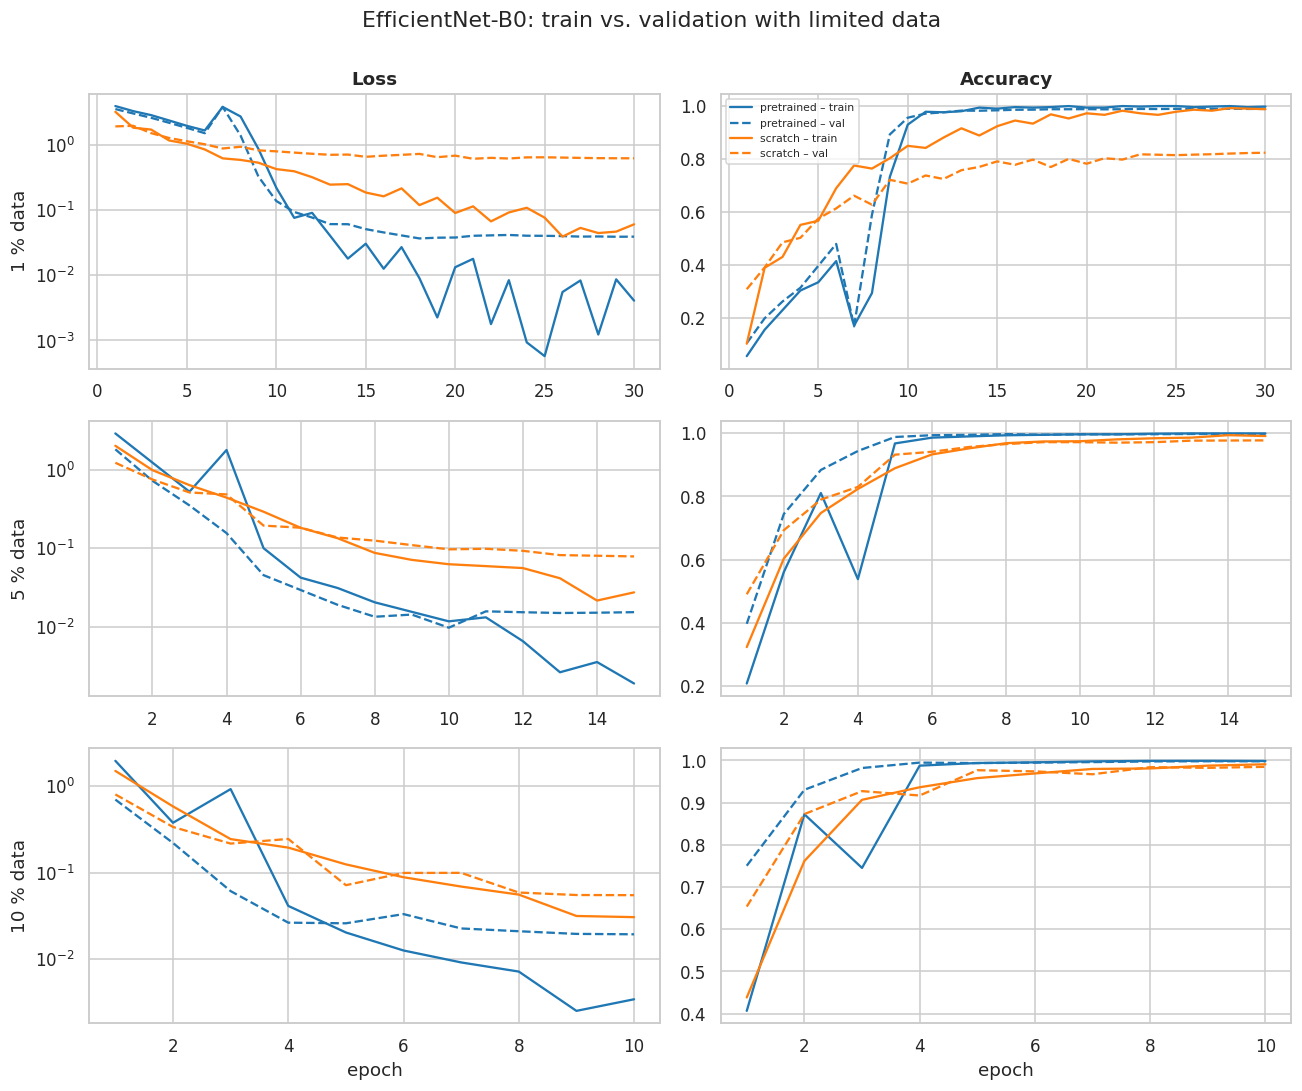

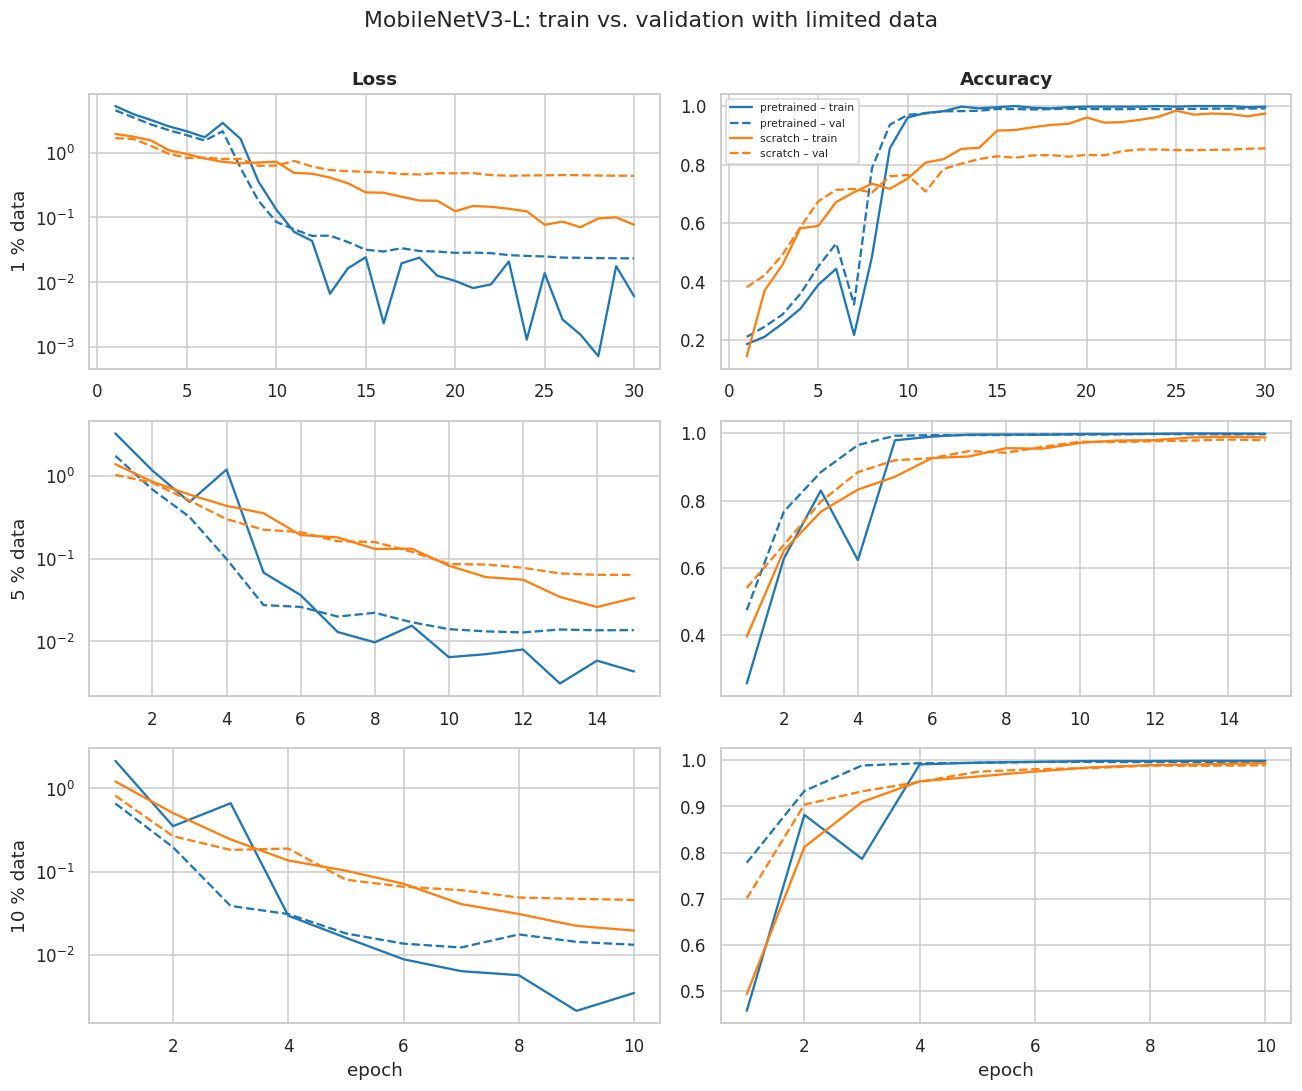

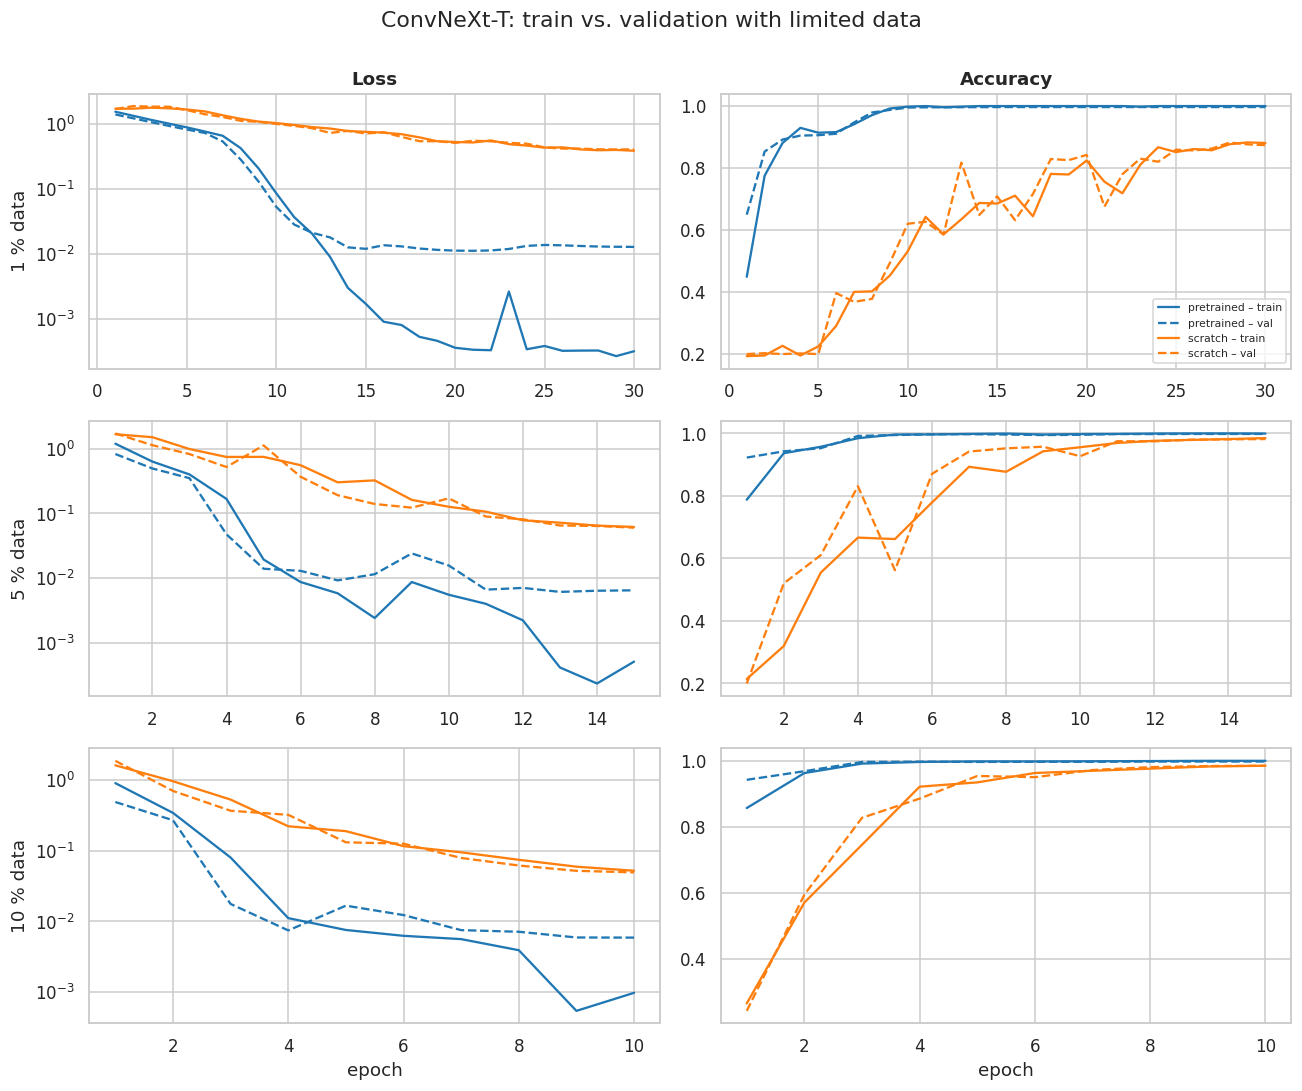

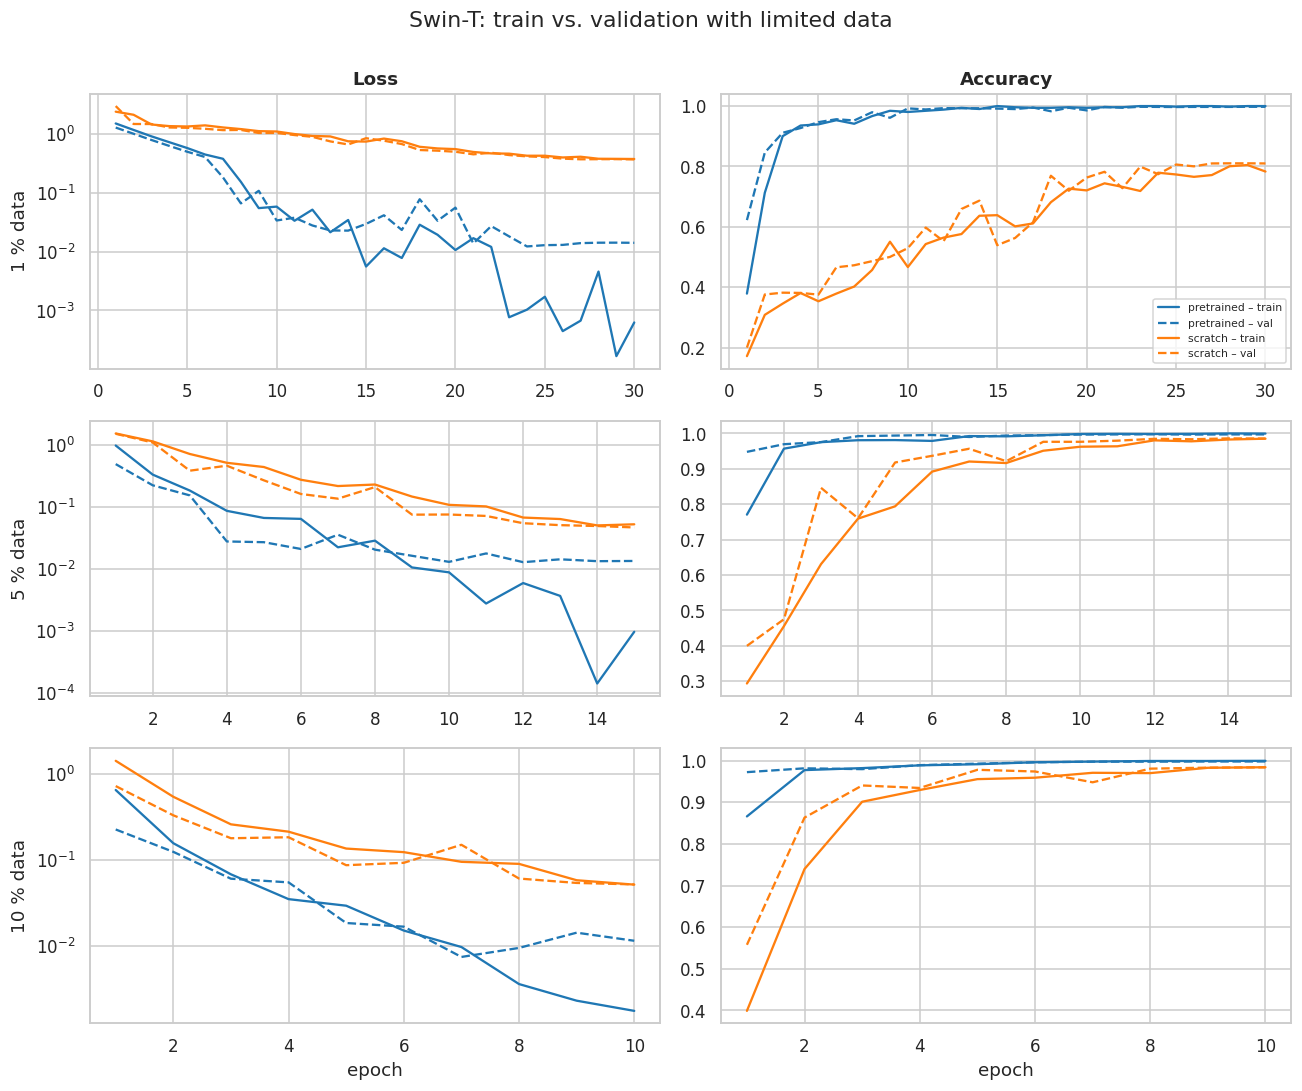

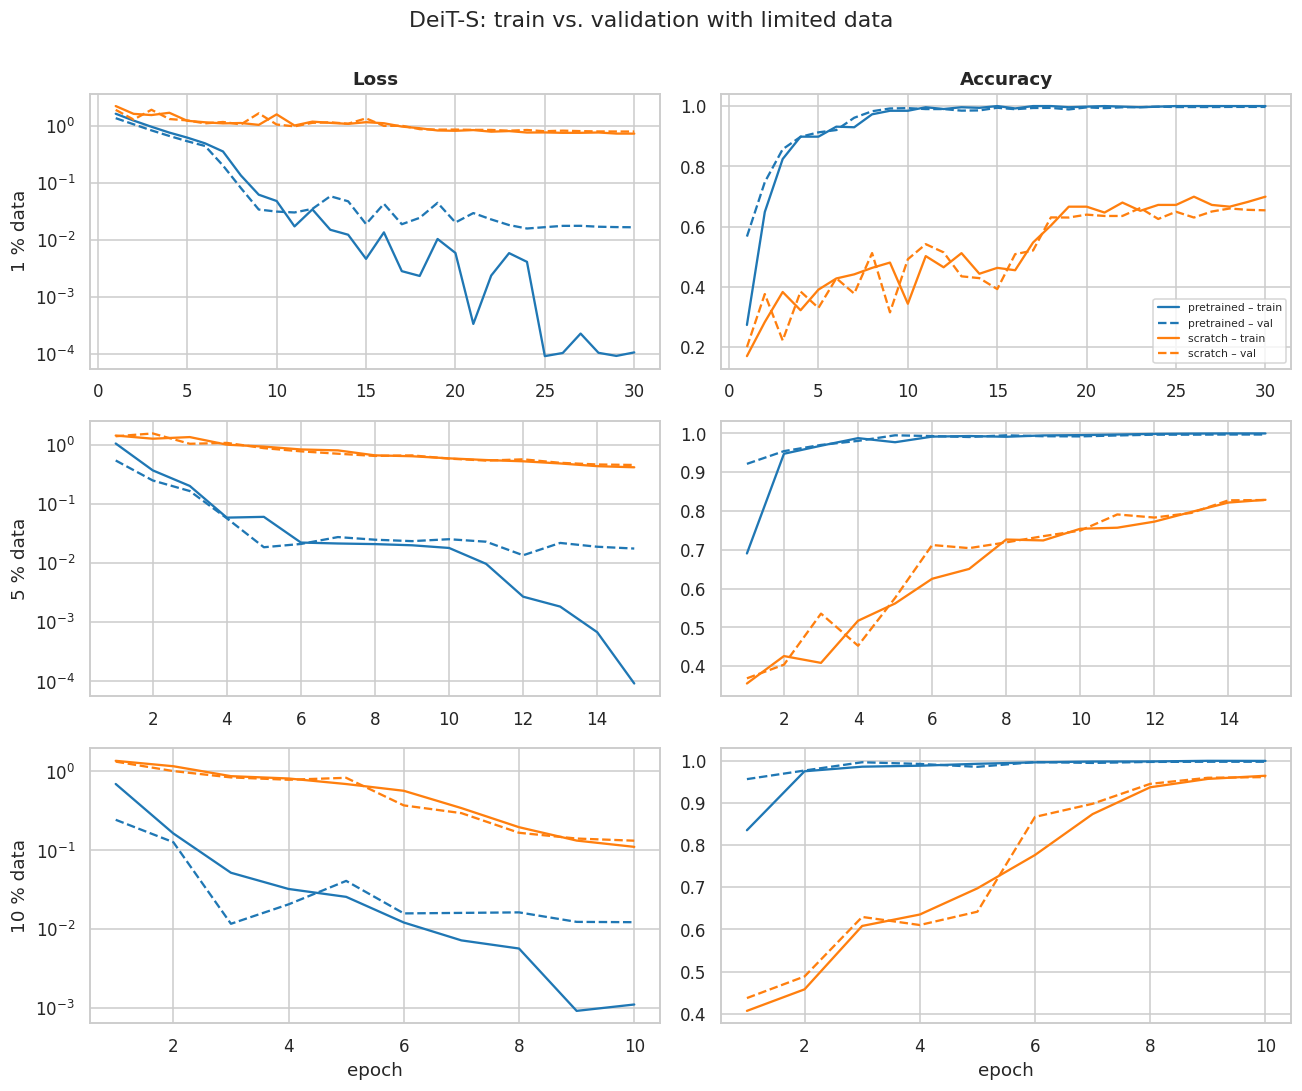

In [29]:
de_runs = load_results('data_eff')
if not de_runs:
    print('No data-efficiency runs found.')
else:
    rows = [dict(model=r['model'], frac=r['frac'], pretrained=r['pretrained'], n_train=r['n_train'],
                 test_acc=r['test_metrics']['acc'], test_f1=r['test_metrics']['macro_f1']) for r in de_runs]
    # the 100 % point comes from the main benchmark (first seed, pretrained)
    for r in main_runs:
        if r['seed'] == SEED0 and r['model'] in {x['model'] for x in de_runs}:
            rows.append(dict(model=r['model'], frac=r['frac'], pretrained=True, n_train=r['n_train'], test_acc=r['test_metrics']['acc'], test_f1=r['test_metrics']['macro_f1']))
    df_de = pd.DataFrame(rows).sort_values(['model', 'pretrained', 'frac'])
    de_models = [k for k in MODEL_ORDER if k in set(df_de.model)]
    fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
    for k in de_models:
        for pt, ax in [(True, axes[0]), (False, axes[1])]:
            d = df_de[(df_de.model == k) & (df_de.pretrained == pt)]
            ax.plot(d.frac * 100, d.test_acc * 100, marker='o', color=COLORS[k], label=k)
    for ax, t in zip(axes[:2], ['Pretrained (ImageNet) → fine-tuned', 'Random initialisation (from scratch)']):
        ax.set_xscale('log'); ax.set_xlabel('% of training data used'); ax.set_ylabel('test accuracy (%)'); ax.set_title(t)
    lo = df_de.test_acc.min() * 100 - 1; axes[0].set_ylim(lo, 100.3); axes[1].set_ylim(lo, 100.3); axes[0].legend()
    gain = df_de[df_de.frac < 1].pivot_table(index=['model', 'frac'], columns='pretrained', values='test_acc')
    if True in gain.columns and False in gain.columns:
        gain = ((gain[True] - gain[False]) * 100).unstack('frac')
        gain.loc[de_models].plot.bar(ax=axes[2], rot=20, width=.8); axes[2].set_ylabel('accuracy gain of pretraining (pp)')
        axes[2].set_title('What transfer learning buys: pretrained − scratch'); axes[2].legend(title='train fraction', labels=[f'{f*100:g} %' for f in gain.columns])
    plt.tight_layout(); savefig('12_data_efficiency')
    display(df_de.pivot_table(index='model', columns=['pretrained', 'frac'], values='test_acc').round(4))

    def plot_de_curves(key):
        fr = sorted({r['frac'] for r in de_runs if r['model'] == key})
        fig, axes = plt.subplots(len(fr), 2, figsize=(12, 3.3 * len(fr)), squeeze=False)
        for i, f in enumerate(fr):
            for r in [r for r in de_runs if r['model'] == key and r['frac'] == f]:
                h = r['history']; ep = h['epoch']; c = '#1f77b4' if r['pretrained'] else '#ff7f0e'; lab = 'pretrained' if r['pretrained'] else 'scratch'
                for j, fld in enumerate(['loss', 'acc']):
                    axes[i, j].plot(ep, h[f'train_{fld}'], '-', color=c, label=f'{lab} – train'); axes[i, j].plot(ep, h[f'val_{fld}'], '--', color=c, label=f'{lab} – val')
            axes[i, 0].set_ylabel(f'{f*100:g} % data'); axes[i, 0].set_yscale('log')
            axes[i, 0].set_title('Loss' if i == 0 else ''); axes[i, 1].set_title('Accuracy' if i == 0 else '')
        axes[0, 1].legend(fontsize=7); axes[-1, 0].set_xlabel('epoch'); axes[-1, 1].set_xlabel('epoch')
        plt.suptitle(f'{key}: train vs. validation with limited data', y=1.0); plt.tight_layout(); savefig(f'13_de_curves_{slugify(key)}')
    for k in de_models: plot_de_curves(k)

<a class="anchor" id="sec16"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">16 · Robustness results</p>

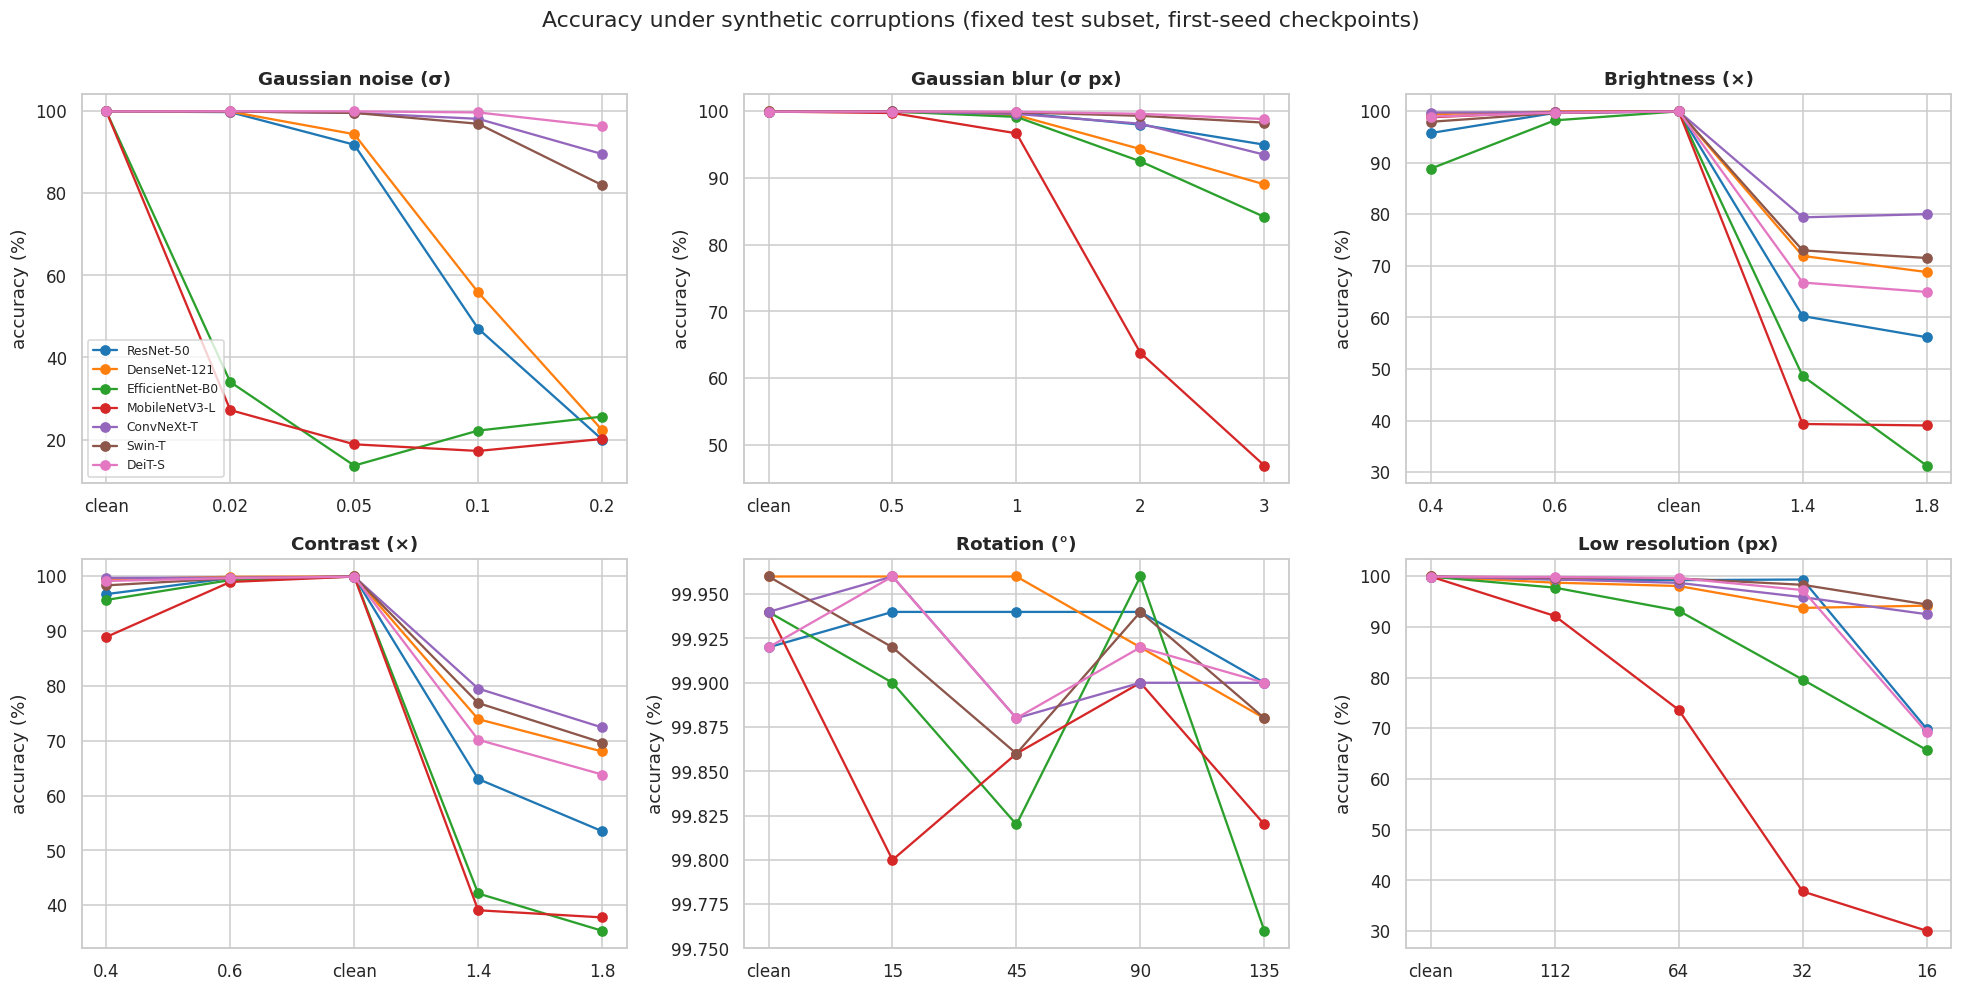

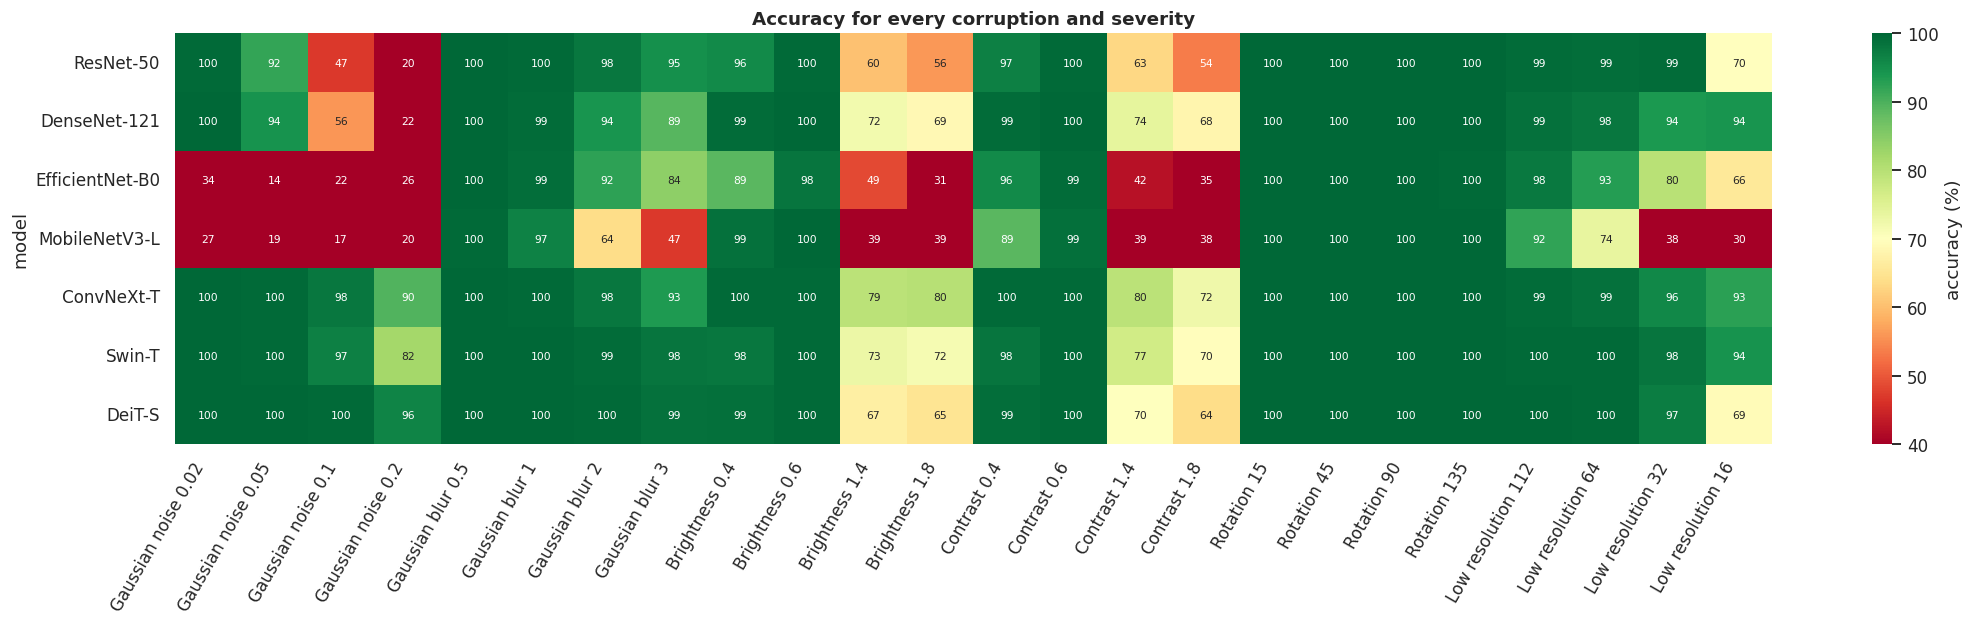

,clean acc,mean corrupted acc,mean drop (pp)
model,,,
ConvNeXt-T,0.9994,0.9478,5.1625
Swin-T,0.9996,0.9392,6.0442
DeiT-S,0.9992,0.9262,7.2958
DenseNet-121,0.9996,0.8837,11.5867
ResNet-50,0.9992,0.8515,14.7725
EfficientNet-B0,0.9994,0.7276,27.1767
MobileNetV3-L,0.9994,0.6522,34.7175


In [30]:
if df_rob.empty:
    print('No robustness data.')
else:
    rob_models = [k for k in MODEL_ORDER if k in set(df_rob.model)]
    clean_x = {'noise': 0, 'blur': 0, 'brightness': 1, 'contrast': 1, 'rotation': 0, 'lowres': S}
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    for ax, (cname, (kind, levels)) in zip(axes.ravel(), CORRUPTIONS.items()):
        xs = sorted(set(levels + [clean_x[kind]]), reverse=(kind == 'lowres'))
        for k in rob_models:
            d = df_rob[df_rob.model == k]; clean = d[d.corruption == 'Clean'].acc.iloc[0]
            ys_ = [clean if v == clean_x[kind] else d[(d.corruption == cname) & np.isclose(d.level, v)].acc.iloc[0] for v in xs]
            ax.plot(range(len(xs)), np.array(ys_) * 100, marker='o', color=COLORS[k], label=k)
        ax.set_xticks(range(len(xs))); ax.set_xticklabels([('clean' if v == clean_x[kind] else f'{v:g}') for v in xs]); ax.set_title(cname); ax.set_ylabel('accuracy (%)')
    axes[0, 0].legend(fontsize=8); plt.suptitle('Accuracy under synthetic corruptions (fixed test subset, first-seed checkpoints)', y=1.0)
    plt.tight_layout(); savefig('14_robustness_curves')

    piv = df_rob[df_rob.corruption != 'Clean'].assign(col=lambda d: d.corruption.str.replace(r' \(.*\)', '', regex=True) + ' ' + d.level.map(lambda v: f'{v:g}')).pivot(index='model', columns='col', values='acc').loc[rob_models]
    order = [f"{c.split(' (')[0]} {l:g}" for c, (_, ls) in CORRUPTIONS.items() for l in ls]
    fig, ax = plt.subplots(figsize=(20, 0.55 * len(rob_models) + 2))
    sns.heatmap(piv[order] * 100, annot=True, fmt='.0f', cmap='RdYlGn', vmin=40, vmax=100, ax=ax, annot_kws={'fontsize': 7}, cbar_kws={'label': 'accuracy (%)'})
    ax.set_xlabel(''); ax.set_title('Accuracy for every corruption and severity'); plt.xticks(rotation=60, ha='right'); plt.tight_layout(); savefig('15_robustness_heatmap')

    clean_acc = df_rob[df_rob.corruption == 'Clean'].set_index('model').acc
    ROB_SUMMARY = pd.DataFrame({'clean acc': clean_acc, 'mean corrupted acc': df_rob[df_rob.corruption != 'Clean'].groupby('model').acc.mean()}).loc[rob_models]
    ROB_SUMMARY['mean drop (pp)'] = (ROB_SUMMARY['clean acc'] - ROB_SUMMARY['mean corrupted acc']) * 100
    display(ROB_SUMMARY.round(4).sort_values('mean corrupted acc', ascending=False))

<a class="anchor" id="sec17"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">17 · Explainability: Grad-CAM</p>

Where does each backbone look? One random correctly-labelled test grain per variety is shown with the Grad-CAM heat-map of the *predicted* class (red = high influence). A well-behaved model is expected to focus on the grain itself, not on the black background. For the Vision Transformers the hook sits on the normalisation layer in the last block (the final block's output cannot carry gradient to patch tokens).

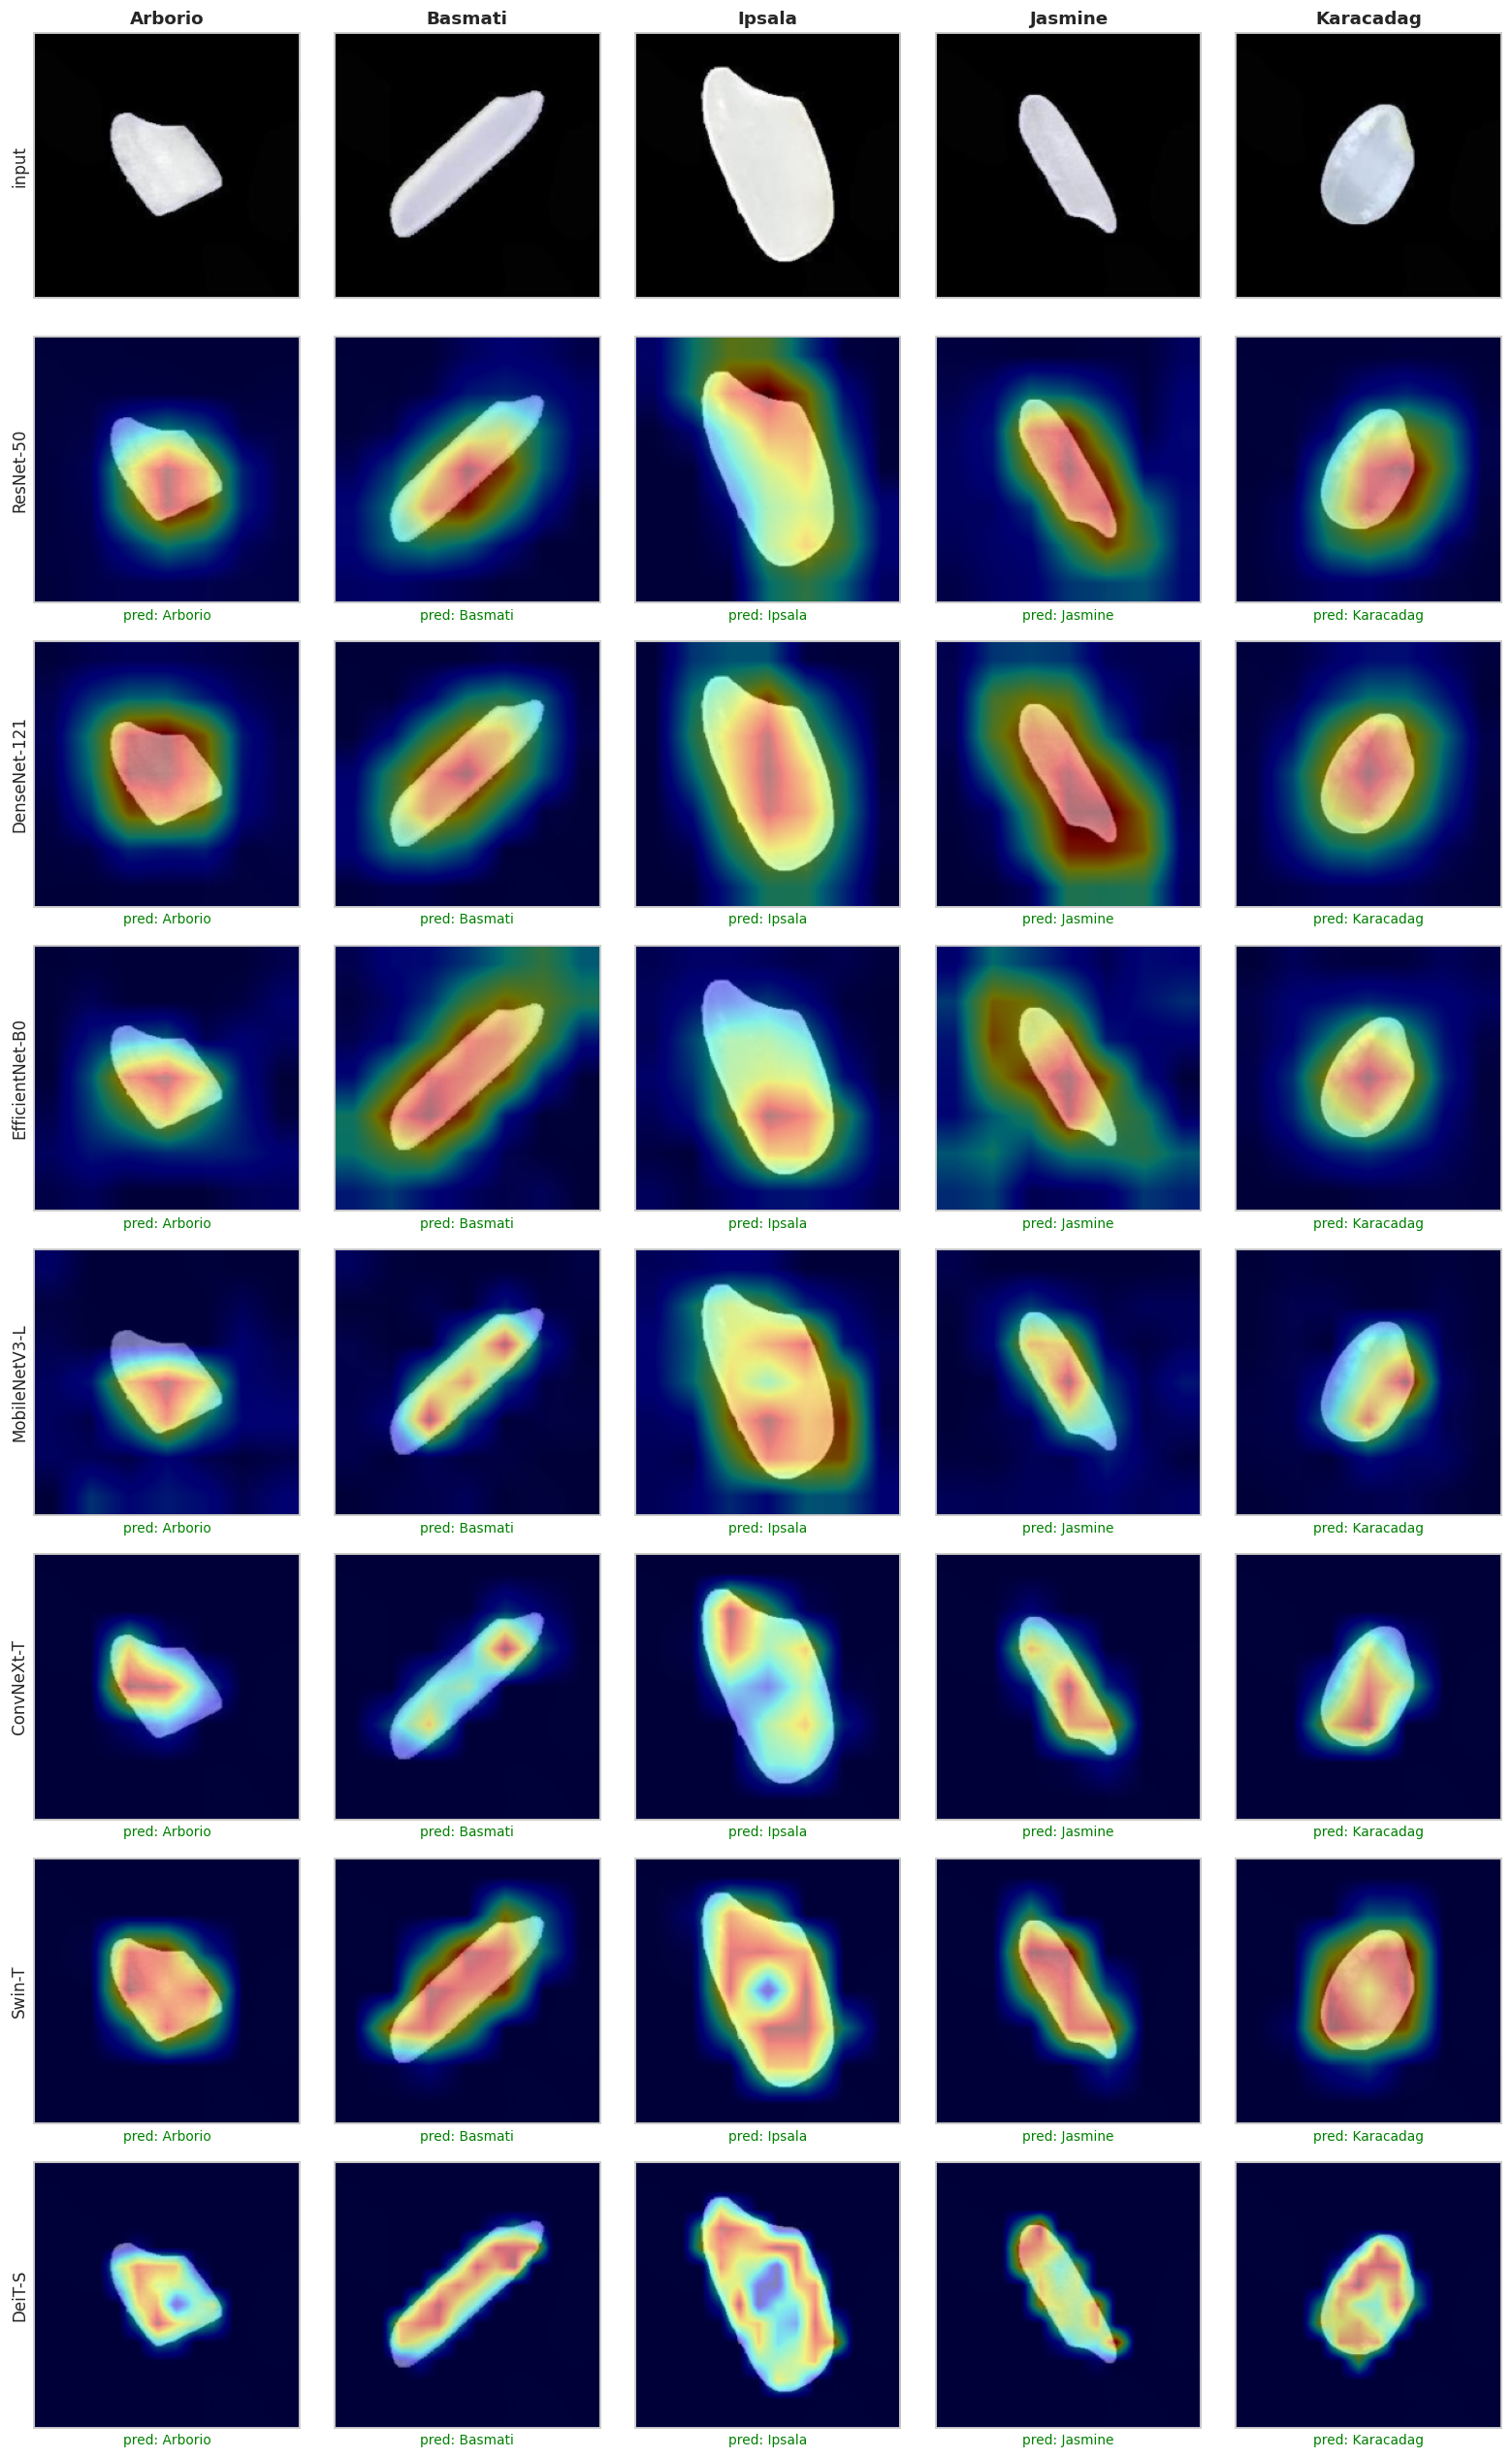

In [31]:
CAM_LAYERS = {'ResNet-50': lambda m: m.layer4[-1], 'DenseNet-121': lambda m: m.features,
              'EfficientNet-B0': lambda m: m.blocks[-1], 'MobileNetV3-L': lambda m: m.blocks[-1],
              'ConvNeXt-T': lambda m: m.stages[-1], 'Swin-T': lambda m: m.layers[-1], 'DeiT-S': lambda m: m.blocks[-1].norm1}

def to_spatial(t):
    if t.ndim == 4:
        return t.permute(0, 3, 1, 2) if (t.shape[1] == t.shape[2] and t.shape[3] != t.shape[1]) else t
    n = t.shape[1]; g = math.isqrt(n); t = t[:, -g * g:, :]
    return t.reshape(t.shape[0], g, g, t.shape[2]).permute(0, 3, 1, 2)

def grad_cam(model, layer, x):
    store = {}
    def fwd(m, i, o):
        store['a'] = o; o.register_hook(lambda g: store.__setitem__('g', g))
    h = layer.register_forward_hook(fwd)
    model.zero_grad(set_to_none=True)
    with torch.enable_grad():
        out = model(x); pred = out.argmax(1); out.gather(1, pred[:, None]).sum().backward()
    h.remove()
    A, G = to_spatial(store['a'].detach()), to_spatial(store['g'].detach())
    cam = F.relu((G.mean((2, 3), keepdim=True) * A).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[:, 0]
    mn = cam.flatten(1).min(1)[0][:, None, None]; cam = cam - mn
    cam = cam / (cam.flatten(1).max(1)[0][:, None, None] + 1e-8)
    return cam.cpu().numpy(), pred.cpu().numpy()

rng = np.random.default_rng(1)
cam_idx = np.array([rng.choice(test_idx[y_all[test_idx] == c]) for c in range(NUM_CLASSES)])
cam_imgs = X_np[cam_idx]; x_in = prep_batch(X_t.index_select(0, torch.from_numpy(cam_idx)), dev, False, None, False)
cam_models = [k for k in MODEL_ORDER if (CKPT_DIR / f'{slugify(k)}.pt').exists() and k in CAM_LAYERS]
fig, axes = plt.subplots(len(cam_models) + 1, NUM_CLASSES, figsize=(2.9 * NUM_CLASSES, 2.9 * (len(cam_models) + 1)))
for c in range(NUM_CLASSES):
    axes[0, c].imshow(cam_imgs[c]); axes[0, c].set_title(CLASS_NAMES[c], fontweight='bold')
axes[0, 0].set_ylabel('input', fontsize=11)
for r_, k in enumerate(cam_models, 1):
    m = load_trained(k); cams, preds = grad_cam(m, CAM_LAYERS[k](m), x_in)
    for c in range(NUM_CLASSES):
        axes[r_, c].imshow(cam_imgs[c]); axes[r_, c].imshow(cams[c], cmap='jet', alpha=0.45)
        axes[r_, c].set_xlabel(f'pred: {CLASS_NAMES[preds[c]]}', color='green' if preds[c] == c else 'red', fontsize=9)
    axes[r_, 0].set_ylabel(k, fontsize=11); del m; gc.collect(); torch.cuda.empty_cache()
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig('16_gradcam')

<a class="anchor" id="sec18"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">18 · Final scorecard</p>

Every backbone is scored on the criteria that are available **for all models** (accuracy, macro-F1, calibration, inference speed, size, training cost, robustness and — if it was run for every backbone — data-efficiency). A criterion that was measured for only some models is left out so that all ranks are comparable. Scores are min–max normalised across the models (1 = best of the group, 0 = worst), so tiny accuracy differences are *visually exaggerated* (they are put in context by the error bars and the McNemar test above).

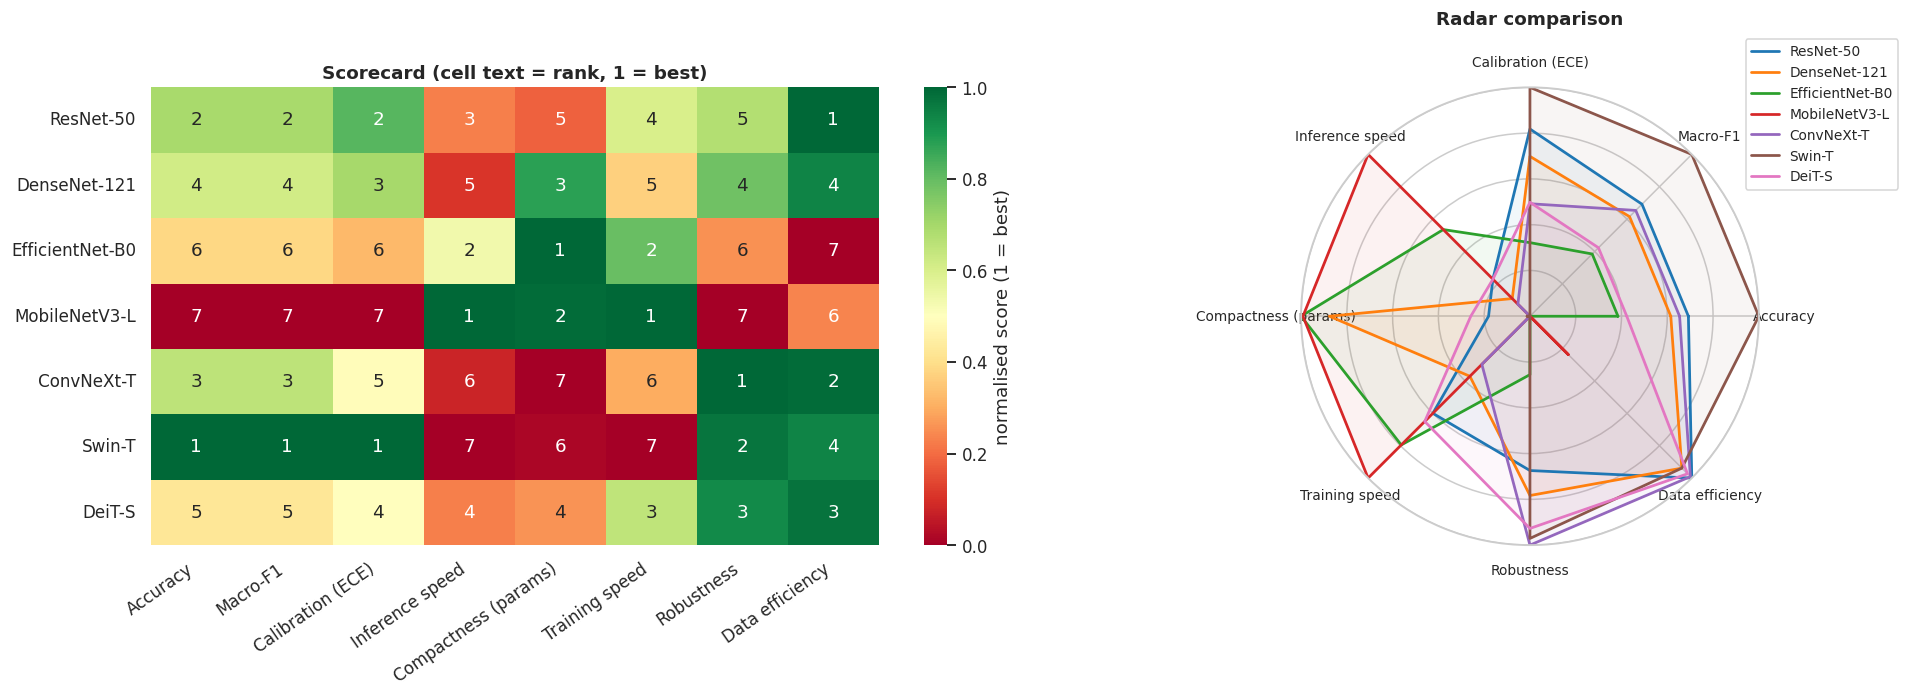

,Accuracy,Macro-F1,Calibration (ECE),Inference speed,Compactness (params),Training speed,Robustness,Data efficiency,mean rank
ResNet-50,2.0,2.0,2.0,3.0,5.0,4.0,5.0,1.0,3.000
Swin-T,1.0,1.0,1.0,7.0,6.0,7.0,2.0,4.0,3.625
DeiT-S,5.0,5.0,4.0,4.0,4.0,3.0,3.0,3.0,3.875
DenseNet-121,4.0,4.0,3.0,5.0,3.0,5.0,4.0,4.0,4.000
ConvNeXt-T,3.0,3.0,5.0,6.0,7.0,6.0,1.0,2.0,4.125
EfficientNet-B0,6.0,6.0,6.0,2.0,1.0,2.0,6.0,7.0,4.500
MobileNetV3-L,7.0,7.0,7.0,1.0,2.0,1.0,7.0,6.0,4.750


In [32]:
SC = pd.DataFrame(index=MODEL_ORDER)
crit = {'Accuracy': ('test_acc', True), 'Macro-F1': ('test_macro_f1', True), 'Calibration (ECE)': ('test_ece', False),
        'Inference speed': ('throughput_fp16', True), 'Compactness (params)': ('params_m', False), 'Training speed': ('train_time_min', False)}
for name, (col, hib) in crit.items(): SC[name] = ALL.loc[MODEL_ORDER, col]
HIB = {n: h for n, (c, h) in crit.items()}
if not df_rob.empty:
    SC['Robustness'] = ROB_SUMMARY['mean corrupted acc'].reindex(MODEL_ORDER); HIB['Robustness'] = True
if de_runs:
    low = df_de[(df_de.frac == df_de.frac[df_de.frac < 1].min()) & df_de.pretrained].set_index('model').test_acc
    SC['Data efficiency'] = low.reindex(MODEL_ORDER); HIB['Data efficiency'] = True
incomplete = [c for c in SC.columns if SC[c].isna().any()]
if incomplete:
    print(f'ℹ️  Not used in the composite score because they are not available for every model: {incomplete}. '
          f'(Data efficiency is reported in section 15; set de_all_models=True to include it here.)')
SC = SC.drop(columns=incomplete)
def minmax(s, hib):
    s = s.astype(float); rng_ = s.max() - s.min()
    if not np.isfinite(rng_) or rng_ == 0: return s * 0 + 0.5
    return (s - s.min()) / rng_ if hib else (s.max() - s) / rng_
NORM = pd.DataFrame({c: minmax(SC[c], HIB[c]) for c in SC.columns})
RANK = pd.DataFrame({c: SC[c].rank(ascending=not HIB[c], method='min') for c in SC.columns})

fig = plt.figure(figsize=(19, 6.5))
ax = fig.add_subplot(1, 2, 1)
sns.heatmap(NORM, annot=RANK.fillna(0).astype(int), fmt='d', cmap='RdYlGn', vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'normalised score (1 = best)'})
ax.set_title('Scorecard (cell text = rank, 1 = best)'); plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
axr = fig.add_subplot(1, 2, 2, polar=True)
ang = np.linspace(0, 2 * np.pi, len(NORM.columns), endpoint=False).tolist(); ang += ang[:1]
for k in MODEL_ORDER:
    v = NORM.loc[k].tolist() + NORM.loc[k].tolist()[:1]; axr.plot(ang, v, color=COLORS[k], lw=1.8, label=k); axr.fill(ang, v, color=COLORS[k], alpha=.06)
axr.set_xticks(ang[:-1]); axr.set_xticklabels(NORM.columns, fontsize=9); axr.set_yticklabels([]); axr.set_ylim(0, 1)
axr.legend(loc='upper right', bbox_to_anchor=(1.32, 1.12)); axr.set_title('Radar comparison', pad=20)
plt.tight_layout(); savefig('17_scorecard')

RANK['mean rank'] = RANK.mean(axis=1)
display(RANK.sort_values('mean rank'))
SC.round(4).to_csv(WORK / 'scorecard_raw.csv'); NORM.round(3).to_csv(WORK / 'scorecard_normalised.csv')

In [33]:
# ---- automatic summary of the findings ----
best_acc = ALL.loc[MODEL_ORDER, 'test_acc']; top = best_acc.max(); tol = 0.002
close = best_acc[best_acc >= top - tol].index.tolist()
def line(label, model, extra=''): print(f'• {label:<42s} {model}  {extra}')
print(f'Models evaluated: {len(MODEL_ORDER)} | seeds: {n_seeds} | test images: {runs_seed0[MODEL_ORDER[0]]["test_metrics"]["n"]}\n')
line('Highest test accuracy', best_acc.idxmax(), f'({top*100:.2f} %, {SUM_MEAN.loc[best_acc.idxmax(), "test_n_errors"]:.1f} errors)')
line('Best macro-F1', ALL.test_macro_f1.idxmax(), f'({ALL.test_macro_f1.max():.4f})')
line('Best calibrated (lowest ECE)', ALL.test_ece.idxmin(), f'(ECE {ALL.test_ece.min():.4f})')
line('Lowest log-loss', ALL.test_log_loss.idxmin(), f'({ALL.test_log_loss.min():.4f})')
line(f'Fastest within {tol*100:.1f} pp of the best', ALL.loc[close, 'throughput_fp16'].idxmax(), f'({ALL.loc[close, "throughput_fp16"].max():.0f} img/s)')
line(f'Smallest within {tol*100:.1f} pp of the best', ALL.loc[close, 'params_m'].idxmin(), f'({ALL.loc[close, "params_m"].min():.1f} M params)')
line('Cheapest to train within that group', ALL.loc[close, 'train_time_min'].idxmin(), f'({ALL.loc[close, "train_time_min"].min():.1f} min)')
line('Largest gain from fine-tuning', ALL.ft_gain.idxmax(), f'(+{ALL.ft_gain.max()*100:.2f} pp over the linear probe)')
line('Best frozen features (linear probe)', ALL.lp_test_acc.idxmax(), f'({ALL.lp_test_acc.max()*100:.2f} %)')
line('Fastest convergence (epochs → 99 % val)', ALL.epochs_to_99.idxmin(), f'({ALL.epochs_to_99.min():.1f} epochs)')
if 'Robustness' in SC: line('Most robust to corruptions', SC['Robustness'].idxmax(), f'(mean {SC["Robustness"].max()*100:.1f} %)')
if de_runs:
    _low = df_de[(df_de.frac == df_de.frac[df_de.frac < 1].min()) & df_de.pretrained].set_index('model').test_acc
    line('Best with the least data', _low.idxmax(), f'({_low.max()*100:.1f} % with {df_de.frac[df_de.frac<1].min()*100:g} % of the data; {len(_low)} models tested)')
line('Best overall (lowest mean rank)', RANK['mean rank'].idxmin(), f'(mean rank {RANK["mean rank"].min():.2f} over {len(SC.columns)} criteria)')
_best = best_acc.idxmax()
_tied = [m for m in MODEL_ORDER if m != _best and pm.loc[_best, m] > 0.05]
print(f'\nStatistical note: {_best} has the highest mean accuracy, but is NOT significantly different (McNemar p > 0.05, seed {SEED0}) from: {", ".join(_tied) if _tied else "none"}.')
print('→ accuracy differences between these models are within noise; robustness, data efficiency and cost are what separate them.')

Models evaluated: 7 | seeds: 3 | test images: 11251

• Highest test accuracy                      Swin-T  (99.97 %, 3.0 errors)
• Best macro-F1                              Swin-T  (0.9997)
• Best calibrated (lowest ECE)               Swin-T  (ECE 0.0002)
• Lowest log-loss                            Swin-T  (0.0009)
• Fastest within 0.2 pp of the best          MobileNetV3-L  (3088 img/s)
• Smallest within 0.2 pp of the best         EfficientNet-B0  (4.0 M params)
• Cheapest to train within that group        MobileNetV3-L  (5.4 min)
• Largest gain from fine-tuning              ResNet-50  (+1.27 pp over the linear probe)
• Best frozen features (linear probe)        Swin-T  (99.53 %)
• Fastest convergence (epochs → 99 % val)    ConvNeXt-T  (1.0 epochs)
• Most robust to corruptions                 ConvNeXt-T  (mean 94.8 %)
• Best with the least data                   ResNet-50  (99.8 % with 1 % of the data; 7 models tested)
• Best overall (lowest mean rank)            ResNet-50  (mean rank

<a class="anchor" id="sec19"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">19 · Conclusions</p>

**Setup.** 7 ImageNet-1k–pretrained backbones (ResNet-50, DenseNet-121, EfficientNet-B0, MobileNetV3-L, ConvNeXt-T, Swin-T, DeiT-S), one identical two-stage recipe (linear probe → full fine-tuning, 6 epochs), one stratified split, 3 seeds each, evaluated on 11,251 held-out test images. Everything below is taken from the tables and figures above.

### Summary of the comparison

| Backbone | Test accuracy | Test errors (of 11,251) | Mean accuracy under corruptions | Throughput (img/s, fp16, T4) | Params | Train time / run |
|---|---|---|---|---|---|---|
| ResNet-50 | 99.95 % | 5.7 ± 0.5 | 85.2 % | 1,042 | 23.5 M | 12.8 min |
| DenseNet-121 | 99.94 % | 6.3 ± 2.9 | 88.4 % | 723 | 7.0 M | 17.1 min |
| EfficientNet-B0 | 99.93 % | 8.3 ± 2.5 | 72.8 % | 1,855 | 4.0 M | 9.2 min |
| MobileNetV3-L | 99.90 % | 11.7 ± 1.2 | 65.2 % | 3,088 | 4.2 M | 5.4 min |
| ConvNeXt-T | 99.95 % | 6.0 ± 2.4 | **94.8 %** | 632 | 27.8 M | 18.5 min |
| Swin-T | **99.97 %** | **3.0 ± 0.0** | 93.9 % | 433 | 27.5 M | 24.1 min |
| DeiT-S | 99.93 % | 8.0 ± 0.8 | 92.6 % | 1,041 | 21.7 M | 11.9 min |

### Findings

1. **Accuracy is saturated — the models are statistically tied.** All seven reach 99.90–99.97 %, i.e. 3–12 mistakes on 11,251 images; 11,226 test images are classified correctly by *every* model and only one image fools as many as five. McNemar's test finds no significant difference between any two models except MobileNetV3-L vs. DenseNet-121 and Swin-T (p = 0.035), which would not survive a correction for the 21 pairwise comparisons. The seed-to-seed spread (up to ±2.9 errors for DenseNet-121 and ±2.4 for ConvNeXt-T) is as large as the gap between most models, so **accuracy alone does not rank these backbones**. The few remaining errors are almost all Arborio ↔ Jasmine confusions (lowest per-class F1 for both, ≈ 0.998–0.999; Basmati and Ipsala are ≈ 1.000).
2. **What transfer learning buys.** A frozen backbone with only a new linear head already reaches 98.7–99.5 % (best: Swin-T 99.53 %, DeiT-S 99.51 %); fine-tuning adds a further +0.4 to +1.3 pp (largest for ResNet-50, +1.27 pp). The transformers and ConvNeXt exceed 99 % validation accuracy after the very first (frozen) epoch, ResNet-50 needs three.
3. **Pre-training matters most when labels are scarce.** With only **1 % of the training data (≈ 525 images)** every pretrained backbone still reaches 98.8–99.8 %. From random initialisation the same architectures collapse: DeiT-S 64.6 %, EfficientNet-B0 80.5 %, Swin-T 81.5 %, MobileNetV3-L 84.7 %, ConvNeXt-T 87.5 % — a gain from pre-training of +12 to +35 pp. The exceptions are the classic CNNs: ResNet-50 (97.8 %) and DenseNet-121 (99.4 %) learn this simple task from scratch remarkably well, and DenseNet-121 matches its pretrained twin at 10 % of the data (99.88 % vs. 99.84 %). *(Single seed — differences below ≈ 0.1 pp are noise.)*
4. **Robustness is where the backbones really differ.** Under synthetic noise, blur, lighting, resolution and rotation shifts, mean accuracy ranges from 94.8 % (ConvNeXt-T) and 93.9 % (Swin-T) down to 72.8 % (EfficientNet-B0) and 65.2 % (MobileNetV3-L), although all have identical clean accuracy.
   * *Noise:* EfficientNet-B0 and MobileNetV3-L fall to ≈ 30 % at a barely visible σ = 0.02; ConvNeXt-T, Swin-T and DeiT-S still exceed 99 % at σ = 0.05.
   * *Resolution / blur:* downscaling to 32 px leaves the transformers above 95 % but drops MobileNetV3-L to 38 %.
   * *Exposure:* **no** backbone is robust to strong brightness or contrast *increases* (×1.4–1.8: best case ≈ 80 % / 72 %) — a real system needs controlled lighting or exposure normalisation.
   * *Orientation:* all models stay above 99.7 % for rotations of 15–135°, so the flip/rotate-90° augmentation generalised to unseen angles.
5. **Training behaviour is healthy.** Train–validation gaps are ≤ 0.1 pp in accuracy for every model, i.e. no over-fitting. The training loss spikes in the first fine-tuning epoch (unfreezing the backbone) and recovers within one epoch. The best checkpoint is almost always the last epoch, so slightly longer fine-tuning could still help a little. All models are well calibrated (ECE ≤ 0.0007); their *wrong* predictions carry only ≈ 0.80–0.87 confidence, so low confidence is a usable signal for sending a grain to manual inspection.
6. **Where the models look (Grad-CAM).** All backbones attend to the grain, but ResNet-50, DenseNet-121 and EfficientNet-B0 produce diffuse heat-maps that extend into the black background, whereas ConvNeXt-T, Swin-T and DeiT-S concentrate on the grain itself. This is consistent with — but does not prove — their better robustness.

### Recommendation

| Situation | Choice | Why |
|---|---|---|
| Controlled, clean imaging; lowest cost | **EfficientNet-B0** (or MobileNetV3-L if speed is critical) | 99.93 % at 4 M parameters and 1,855 img/s (MobileNetV3-L: 99.90 % at 3,088 img/s) — but both are fragile under noise, blur and low resolution |
| Variable cameras, lighting, resolution | **ConvNeXt-T** or **Swin-T** | 94–95 % under corruptions, best calibration (Swin-T) and fewest errors (3); Swin-T is the slowest (433 img/s) |
| Balanced default | **ResNet-50** | best composite rank over 8 criteria (mean rank 3.0), 99.95 %, 1,042 img/s — but only 85 % under corruptions |
| Very little labelled data | any pretrained backbone | avoid training ViTs (DeiT-S, Swin-T) from scratch |

### Limitations and next steps
* The dataset is clean — a single centred grain, uniform black background, controlled lighting — so near-perfect accuracy here does **not** prove performance on photos from a real sorting line; the corruptions are synthetic stand-ins. Testing on real-world images is the most important next step.
* Statistics: 3 seeds for the main benchmark, 1 seed for the data-efficiency study; McNemar p-values are uncorrected for multiple comparisons; the 11,251-image test set cannot resolve differences below ≈ 0.01 pp.
* Fixed 6-epoch budget and one hyper-parameter setting for all backbones (no per-model tuning); only ImageNet-1k pre-training was compared.
* Possible extensions: self-supervised / CLIP backbones, knowledge distillation or quantisation of the best model, robustness-oriented augmentation (noise, exposure, blur) and test-time calibration, evaluation on a second rice dataset.

---
**Reproducibility:** fixed split (seed 42), seeds `[42, 43, 44]`, library versions printed at the top, all raw results in `/kaggle/working/results_v2/*.json`, all figures in `/kaggle/working/figures/`, summary tables in `/kaggle/working/*.csv`.
